# CSE428 — Pet Segmentation & Breed Classification
Joint **segmentation + 37-way breed classification** on the Oxford-IIIT Pet Dataset using Base U-Net, Attention U-Net, an EfficientDet-style BiFPN decoder, and a pretrained ResNet34 U-Net.

> Executed on Kaggle (2× Tesla T4). Paths point to a Kaggle dataset mount — change `images_dir` / `masks_dir` (and `/kaggle/working`) to run elsewhere.

**Metric definitions used throughout:** binary-segmentation **mIoU** = mean IoU over {background, foreground}. **Dice in per-epoch training logs** = foreground-only Dice; **Dice in the final summary table** = mean Dice over {background, foreground}; the ResNet34 test Dice (cell 11) is foreground-only. Compare models on mIoU / pixel accuracy; compare Dice only within the same definition.

In [1]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

#import os 
#for dirname, _, filenames in os.walk('/kaggle/input'):
#    for filename in filenames:
#        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session3

In [2]:
# CSE428 Project — Oxford-IIIT Pet Dataset
# Pet Segmentation & Classification with U-Net / Attention U-Net / EfficientDet-UNet
# Kaggle T4x2 GPU Environment
# =============================================================================
# Dataset: https://www.robots.ox.ac.uk/~vgg/data/pets/
# Paper (U-Net): https://arxiv.org/abs/1505.04597
# Paper (Att-UNet): https://arxiv.org/abs/1804.03999
# Paper (EfficientDet): https://arxiv.org/abs/1911.09070
# =============================================================================

!pip install -q albumentations

import os, cv2, random, warnings, copy, time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import torch, torch.nn as nn, torch.nn.functional as F
from torch.cuda.amp import GradScaler, autocast
from sklearn.metrics import (accuracy_score, precision_recall_fscore_support,
                             confusion_matrix, ConfusionMatrixDisplay)
warnings.filterwarnings('ignore')

# ── GPU Setup ──────────────────────────────────────────────────────────────────
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
num_gpus = torch.cuda.device_count()
print(f"Device: {device}  |  GPUs available: {num_gpus}")
if torch.cuda.is_available():
    for i in range(num_gpus):
        print(f"  GPU {i}: {torch.cuda.get_device_name(i)}")

def seed_everything(seed=42):
    random.seed(seed); np.random.seed(seed); torch.manual_seed(seed)
    if torch.cuda.is_available(): torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = True
seed_everything(42)
print("\nRandom seeds fixed to 42 for reproducibility.")

Device: cuda  |  GPUs available: 2
  GPU 0: Tesla T4
  GPU 1: Tesla T4

Random seeds fixed to 42 for reproducibility.


Images dir exists: True
Masks  dir exists: True

Total image-mask pairs : 7390
Unique breeds (classes): 37
Species breakdown       : Cats=2400 | Dogs=4990


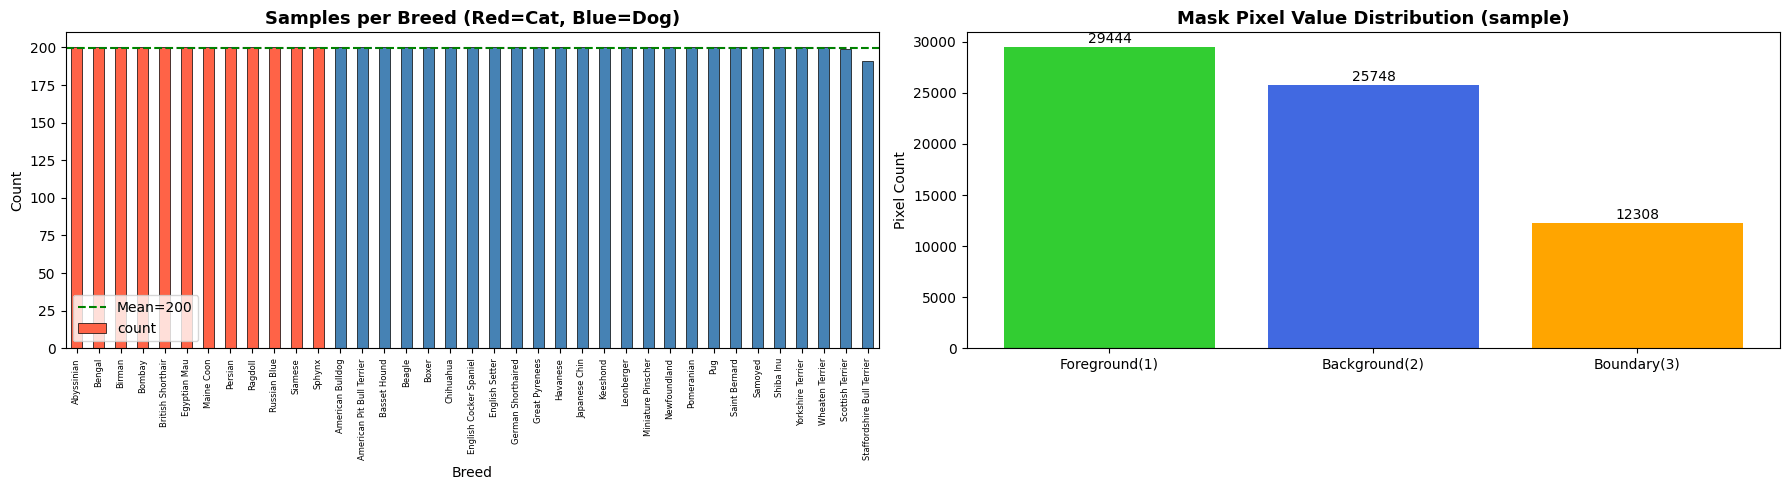

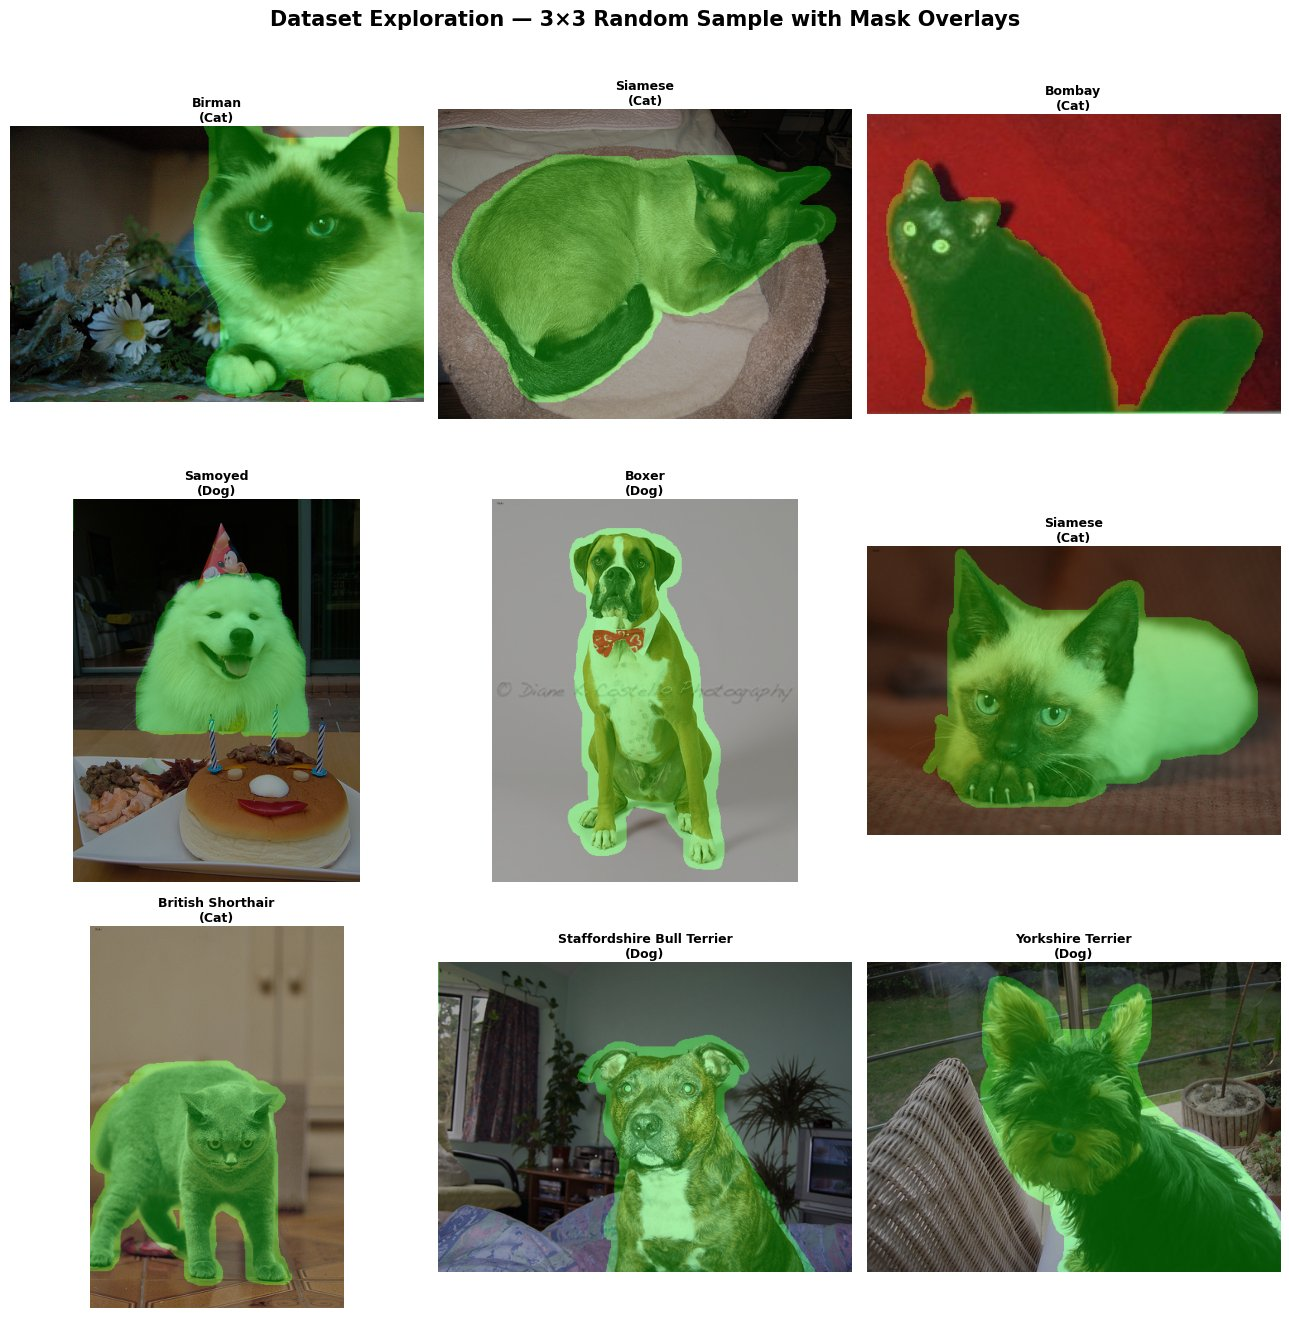


Cell 1 complete — dataset loaded and explored.


In [3]:
# ═══════════════════════════════════════════════════════════════════════════
# CELL 1 ─ DATASET EXPLORATION
# PURPOSE : Load data paths, parse breed/species labels, handle mask pixel values,
#           visualise class distribution, and display 3×3 image+overlay grid.
# MASK ENCODING (Oxford-IIIT trimaps):
#   1 → Pet foreground  | 2 → Background  | 3 → Unclassified/Boundary
#   We map 1&3 → 1 (foreground), 2 → 0 (background) for binary segmentation.
# ═══════════════════════════════════════════════════════════════════════════

# ── Paths (adjust if your Kaggle dataset slug differs) ────────────────────────
images_dir = '/kaggle/input/datasets/mdtanvirulislamrifat/pet-dataset/images/images'
masks_dir  = '/kaggle/input/datasets/mdtanvirulislamrifat/pet-dataset/annotations/annotations/trimaps'

print(f"Images dir exists: {os.path.exists(images_dir)}")
print(f"Masks  dir exists: {os.path.exists(masks_dir)}")

# ── Build Dataset Info List ───────────────────────────────────────────────────
image_files = [f for f in os.listdir(images_dir) if f.endswith('.jpg') and not f.startswith('.')]

dataset_info = []
for img_file in sorted(image_files):
    mask_file = img_file.replace('.jpg', '.png')
    mask_path = os.path.join(masks_dir, mask_file)
    if not os.path.exists(mask_path):
        continue
    breed_raw   = img_file.rsplit('_', 1)[0]
    species     = "Cat" if breed_raw[0].isupper() else "Dog"
    breed_clean = breed_raw.replace('_', ' ').title()
    dataset_info.append({
        'img_path': os.path.join(images_dir, img_file),
        'mask_path': mask_path,
        'breed': breed_clean,
        'species': species,
        'class_id': breed_raw
    })

unique_breeds = sorted(list(set(d['breed'] for d in dataset_info)))
NUM_CLASSES   = len(unique_breeds)
print(f"\nTotal image-mask pairs : {len(dataset_info)}")
print(f"Unique breeds (classes): {NUM_CLASSES}")
print(f"Species breakdown       : Cats={sum(1 for d in dataset_info if d['species']=='Cat')} | Dogs={sum(1 for d in dataset_info if d['species']=='Dog')}")

# ── Visualisation 1: Class Distribution Bar Chart ────────────────────────────
breed_counts = pd.Series([d['breed'] for d in dataset_info]).value_counts()
colors = ['steelblue' if d['species']=='Dog' else 'tomato'
          for d in dataset_info if d['breed'] == breed_counts.index[0]][:1] * len(breed_counts)
colors = ['tomato' if any(d['species']=='Cat' and d['breed']==b for d in dataset_info) else 'steelblue'
          for b in breed_counts.index]

fig, axes = plt.subplots(1, 2, figsize=(18, 5))
breed_counts.plot(kind='bar', ax=axes[0], color=colors, edgecolor='black', linewidth=0.5)
axes[0].set_title('Samples per Breed (Red=Cat, Blue=Dog)', fontsize=13, fontweight='bold')
axes[0].set_xlabel('Breed'); axes[0].set_ylabel('Count')
axes[0].tick_params(axis='x', rotation=90, labelsize=6)
axes[0].axhline(breed_counts.mean(), color='green', linestyle='--', label=f'Mean={breed_counts.mean():.0f}')
axes[0].legend()

# Mask pixel distribution on a sample
sample = random.choice(dataset_info)
mask_raw = cv2.imread(sample['mask_path'], cv2.IMREAD_GRAYSCALE)
vals, cnts = np.unique(mask_raw, return_counts=True)
val_labels = {1: 'Foreground(1)', 2: 'Background(2)', 3: 'Boundary(3)'}
axes[1].bar([val_labels.get(v, str(v)) for v in vals], cnts,
            color=['limegreen','royalblue','orange'])
axes[1].set_title('Mask Pixel Value Distribution (sample)', fontsize=13, fontweight='bold')
axes[1].set_ylabel('Pixel Count')
for bar, cnt in zip(axes[1].patches, cnts):
    axes[1].text(bar.get_x()+bar.get_width()/2, bar.get_height()+100, f'{cnt}',
                 ha='center', va='bottom', fontsize=10)
plt.tight_layout(); plt.show()

# ── Visualisation 2: 3×3 Image + Mask Overlay Grid ───────────────────────────
def plot_3x3_exploration(dataset_records, seed=None):
    """Plots 9 random images with green foreground mask overlay."""
    if seed: random.seed(seed)
    samples = random.sample(dataset_records, 9)
    fig, axes = plt.subplots(3, 3, figsize=(13, 13))
    fig.suptitle('Dataset Exploration — 3×3 Random Sample with Mask Overlays',
                 fontsize=15, fontweight='bold', y=1.01)
    for i, sample in enumerate(samples):
        ax = axes[i // 3, i % 3]
        img  = cv2.cvtColor(cv2.imread(sample['img_path']), cv2.COLOR_BGR2RGB)
        mask = cv2.imread(sample['mask_path'], cv2.IMREAD_GRAYSCALE)
        # Binary mask: 1(foreground) + 3(boundary) → foreground
        bin_mask = np.where((mask == 1) | (mask == 3), 1, 0).astype(np.uint8)
        overlay  = np.zeros_like(img); overlay[bin_mask == 1] = [0, 220, 0]
        blended  = cv2.addWeighted(img, 0.65, overlay, 0.35, 0)
        ax.imshow(blended)
        ax.set_title(f"{sample['breed']}\n({sample['species']})",
                     fontsize=9, fontweight='bold', pad=3)
        ax.axis('off')
    plt.tight_layout(); plt.show()

plot_3x3_exploration(dataset_info, seed=123)
print("\nCell 1 complete — dataset loaded and explored.")

In [4]:
# ═══════════════════════════════════════════════════════════════════════════
# CELL 2 ─ PYTORCH DATASET, AUGMENTATION & DATALOADERS
# PURPOSE : Define PetDataset class, create rich augmentation pipeline (Bonus 2),
#           stratified train/val/test split, and DataLoaders.
#
# IMPORTANT BUG FIX (vs original):
#   After albumentations ToTensorV2, mask shape is [C,H,W] NOT [H,W,C].
#   Correct indexing: combined_masks[0] → binary | combined_masks[1] → triclass
# ═══════════════════════════════════════════════════════════════════════════

from torch.utils.data import Dataset, DataLoader
import albumentations as A
from albumentations.pytorch import ToTensorV2
from sklearn.model_selection import train_test_split

class_to_idx = {breed: idx for idx, breed in enumerate(unique_breeds)}
idx_to_class = {idx: breed for breed, idx in class_to_idx.items()}
# breed -> species lookup (title-cased breed names all start uppercase, so species
# must be derived from the raw filename convention, not from the cleaned name)
breed_to_species = {d['breed']: ('cat' if d['species']=='Cat' else 'dog') for d in dataset_info}
print(f"Class mapping built: {NUM_CLASSES} breeds")

class PetDataset(Dataset):
    def __init__(self, data_list, transform=None):
        self.data_list = data_list
        self.transform = transform

    def __len__(self): return len(self.data_list)

    def __getitem__(self, idx):
        item     = self.data_list[idx]
        image    = cv2.cvtColor(cv2.imread(item['img_path']), cv2.COLOR_BGR2RGB)
        mask_raw = cv2.imread(item['mask_path'], cv2.IMREAD_GRAYSCALE)

        binary_mask   = np.where((mask_raw == 1) | (mask_raw == 3), 1.0, 0.0).astype(np.float32)
        triclass_mask = np.zeros_like(mask_raw, dtype=np.float32)
        triclass_mask[mask_raw == 1] = 1.0
        triclass_mask[mask_raw == 3] = 2.0

        # Stack: [H, W, 2]
        combined = np.stack([binary_mask, triclass_mask], axis=-1)

        if self.transform:
            aug      = self.transform(image=image, mask=combined)
            image    = aug['image']    # [3, H, W] — ToTensorV2 handles image correctly
            combined = aug['mask']     # may be [H, W, 2] tensor depending on albumentations version

            # ── FIX: ensure combined is [2, H, W] regardless of albumentations version ──
            if isinstance(combined, torch.Tensor):
                if combined.dim() == 3 and combined.shape[-1] == 2:
                    combined = combined.permute(2, 0, 1)   # [H, W, 2] → [2, H, W]
                # else: already [2, H, W], do nothing
            else:
                # still numpy [H, W, 2]
                combined = torch.from_numpy(combined.transpose(2, 0, 1))  # [2, H, W]
        else:
            # No transform: manually convert to tensors
            image    = torch.from_numpy(image.transpose(2, 0, 1)).float() / 255.0
            combined = torch.from_numpy(combined.transpose(2, 0, 1))

        binary_out   = combined[0].unsqueeze(0).float()   # [1, H, W]
        triclass_out = combined[1].long()                 # [H, W]

        label = class_to_idx[item['breed']]
        return image, torch.tensor(label, dtype=torch.long), binary_out, triclass_out

# ── Transforms ────────────────────────────────────────────────────────────────
IMG_SIZE = 256

train_transform_aug = A.Compose([
    A.Resize(288, 288),
    A.RandomCrop(IMG_SIZE, IMG_SIZE),
    A.HorizontalFlip(p=0.5),
    A.ShiftScaleRotate(shift_limit=0.05, scale_limit=0.1, rotate_limit=15, p=0.5),
    A.ColorJitter(brightness=0.25, contrast=0.25, saturation=0.25, hue=0.1, p=0.5),
    A.GaussianBlur(blur_limit=(3,5), p=0.2),
    A.GridDistortion(num_steps=5, distort_limit=0.15, p=0.2),
    A.CoarseDropout(max_holes=4, max_height=32, max_width=32,
                    min_holes=1, fill_value=0, p=0.3),
    A.Normalize(mean=(0.485,0.456,0.406), std=(0.229,0.224,0.225)),
    ToTensorV2()
])

train_transform_no_aug = A.Compose([
    A.Resize(IMG_SIZE, IMG_SIZE),
    A.Normalize(mean=(0.485,0.456,0.406), std=(0.229,0.224,0.225)),
    ToTensorV2()
])

val_test_transform = A.Compose([
    A.Resize(IMG_SIZE, IMG_SIZE),
    A.Normalize(mean=(0.485,0.456,0.406), std=(0.229,0.224,0.225)),
    ToTensorV2()
])

# ── Splits ────────────────────────────────────────────────────────────────────
strat_labels = [d['breed'] for d in dataset_info]
train_info, temp_info = train_test_split(
    dataset_info, test_size=0.30, random_state=42, stratify=strat_labels)
val_info, test_info = train_test_split(
    temp_info, test_size=0.50, random_state=42,
    stratify=[d['breed'] for d in temp_info])

print(f"Split → Train: {len(train_info)} | Val: {len(val_info)} | Test: {len(test_info)}")

# ── Quick sanity check on mask shapes ─────────────────────────────────────────
_ds = PetDataset(train_info[:4], transform=val_test_transform)
_img, _lbl, _bin, _tri = _ds[0]
print(f"Sanity check → image: {_img.shape} | binary_mask: {_bin.shape} | triclass_mask: {_tri.shape}")
assert _bin.shape == torch.Size([1, IMG_SIZE, IMG_SIZE]), f"binary mask shape wrong: {_bin.shape}"
assert _tri.shape == torch.Size([IMG_SIZE, IMG_SIZE]),    f"triclass mask shape wrong: {_tri.shape}"
print("✔ Mask shapes correct\n")
del _ds, _img, _lbl, _bin, _tri

# ── Datasets & Loaders ────────────────────────────────────────────────────────
BATCH_SIZE = 32

train_ds_aug    = PetDataset(train_info, transform=train_transform_aug)
train_ds_no_aug = PetDataset(train_info, transform=train_transform_no_aug)
val_ds          = PetDataset(val_info,   transform=val_test_transform)
test_ds         = PetDataset(test_info,  transform=val_test_transform)

train_loader_aug    = DataLoader(train_ds_aug,    batch_size=BATCH_SIZE, shuffle=True,
                                 num_workers=2, pin_memory=True, drop_last=True)
train_loader_no_aug = DataLoader(train_ds_no_aug, batch_size=BATCH_SIZE, shuffle=True,
                                 num_workers=2, pin_memory=True, drop_last=True)
val_loader          = DataLoader(val_ds,  batch_size=BATCH_SIZE, shuffle=False,
                                 num_workers=2, pin_memory=True)
test_loader         = DataLoader(test_ds, batch_size=BATCH_SIZE, shuffle=False,
                                 num_workers=2, pin_memory=True)

print(f"Loaders ready — Train: {len(train_ds_aug)} | Val: {len(val_ds)} | Test: {len(test_ds)}")
print("Cell 2 complete.")

Class mapping built: 37 breeds
Split → Train: 5173 | Val: 1108 | Test: 1109
Sanity check → image: torch.Size([3, 256, 256]) | binary_mask: torch.Size([1, 256, 256]) | triclass_mask: torch.Size([256, 256])
✔ Mask shapes correct

Loaders ready — Train: 5173 | Val: 1108 | Test: 1109
Cell 2 complete.


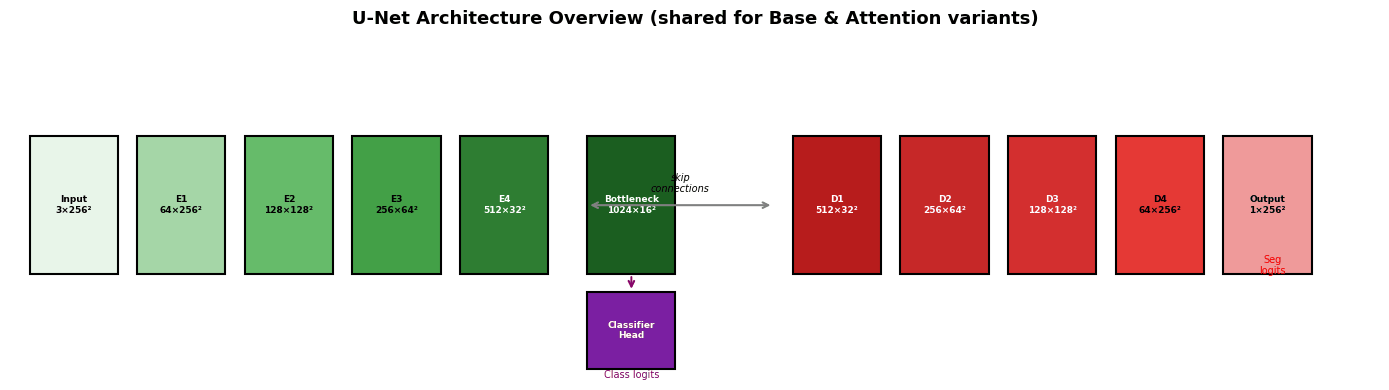

Base U-Net parameters   : 31,704,294
Attention U-Net params  : 32,054,862

Cell 3 complete — architectures built with Kaiming He initialisation.


In [5]:
# ═══════════════════════════════════════════════════════════════════════════
# CELL 3 ─ MODEL ARCHITECTURES: BASE U-NET & ATTENTION U-NET
# PURPOSE : Define both architectures with shared encoder, joint segmentation +
#           classification heads, and Kaiming He weight initialisation.
#
# IMPROVEMENTS over original:
#   ✔ Kaiming He weight initialisation for all Conv2d layers
#   ✔ Deeper classifier head with BatchNorm + higher Dropout
#   ✔ Architecture diagram printed via matplotlib
#   ✔ Duplicate cell removed (was duplicated in original notebook)
# ═══════════════════════════════════════════════════════════════════════════

# ── Shared Building Blocks ─────────────────────────────────────────────────────
class ConvBlock(nn.Module):
    """Double Conv → BN → ReLU (encoder/decoder unit)."""
    def __init__(self, in_ch, out_ch):
        super().__init__()
        self.net = nn.Sequential(
            nn.Conv2d(in_ch, out_ch, 3, padding=1, bias=False),
            nn.BatchNorm2d(out_ch), nn.ReLU(inplace=True),
            nn.Conv2d(out_ch, out_ch, 3, padding=1, bias=False),
            nn.BatchNorm2d(out_ch), nn.ReLU(inplace=True)
        )
    def forward(self, x): return self.net(x)

def init_weights(m):
    """Kaiming He initialisation — better convergence than default Xavier."""
    if isinstance(m, (nn.Conv2d, nn.ConvTranspose2d)):
        nn.init.kaiming_normal_(m.weight, mode='fan_out', nonlinearity='relu')
        if m.bias is not None: nn.init.zeros_(m.bias)
    elif isinstance(m, nn.BatchNorm2d):
        nn.init.ones_(m.weight); nn.init.zeros_(m.bias)
    elif isinstance(m, nn.Linear):
        nn.init.kaiming_normal_(m.weight); nn.init.zeros_(m.bias)

# ── Base U-Net ─────────────────────────────────────────────────────────────────
class BaseUNet(nn.Module):
    """
    U-Net (Ronneberger et al. 2015) with joint segmentation + classification.
    Encoder bottleneck → shared features → (i) segmentation decoder (ii) classifier head.
    """
    def __init__(self, in_ch=3, seg_ch=1, num_classes=37):
        super().__init__()
        # Encoder
        self.e1 = ConvBlock(in_ch,  64);   self.e2 = ConvBlock(64,  128)
        self.e3 = ConvBlock(128, 256);     self.e4 = ConvBlock(256, 512)
        self.pool = nn.MaxPool2d(2, 2)
        self.bottleneck = ConvBlock(512, 1024)

        # Classifier head (attached to bottleneck)
        self.classifier = nn.Sequential(
            nn.AdaptiveAvgPool2d(1), nn.Flatten(),
            nn.Linear(1024, 512), nn.BatchNorm1d(512), nn.ReLU(),
            nn.Dropout(0.4),
            nn.Linear(512, 256), nn.ReLU(),
            nn.Dropout(0.3),
            nn.Linear(256, num_classes)
        )

        # Decoder
        self.up1 = nn.ConvTranspose2d(1024, 512, 2, 2); self.d1 = ConvBlock(1024, 512)
        self.up2 = nn.ConvTranspose2d(512,  256, 2, 2); self.d2 = ConvBlock(512,  256)
        self.up3 = nn.ConvTranspose2d(256,  128, 2, 2); self.d3 = ConvBlock(256,  128)
        self.up4 = nn.ConvTranspose2d(128,   64, 2, 2); self.d4 = ConvBlock(128,   64)
        self.seg_head = nn.Conv2d(64, seg_ch, 1)

        self.apply(init_weights)

    def forward(self, x):
        s1 = self.e1(x);         s2 = self.e2(self.pool(s1))
        s3 = self.e3(self.pool(s2)); s4 = self.e4(self.pool(s3))
        b  = self.bottleneck(self.pool(s4))
        cls = self.classifier(b)
        d   = self.d1(torch.cat([s4, self.up1(b)], 1))
        d   = self.d2(torch.cat([s3, self.up2(d)], 1))
        d   = self.d3(torch.cat([s2, self.up3(d)], 1))
        d   = self.d4(torch.cat([s1, self.up4(d)], 1))
        return self.seg_head(d), cls

# ── Attention Gate ─────────────────────────────────────────────────────────────
class AttentionGate(nn.Module):
    """
    Attention gate (Oktay et al. 2018): gates skip-connection features
    by a gating signal from the decoder path, suppressing irrelevant regions.
    """
    def __init__(self, F_g, F_l, F_int):
        super().__init__()
        self.W_g = nn.Sequential(nn.Conv2d(F_g, F_int, 1, bias=False), nn.BatchNorm2d(F_int))
        self.W_x = nn.Sequential(nn.Conv2d(F_l, F_int, 1, bias=False), nn.BatchNorm2d(F_int))
        self.psi = nn.Sequential(nn.Conv2d(F_int, 1, 1, bias=False), nn.BatchNorm2d(1), nn.Sigmoid())
        self.relu = nn.ReLU(inplace=True)

    def forward(self, g, x):
        return x * self.psi(self.relu(self.W_g(g) + self.W_x(x)))

# ── Attention U-Net ────────────────────────────────────────────────────────────
class AttentionUNet(nn.Module):
    """Attention U-Net: same structure as BaseUNet but with attention gates on skip connections."""
    def __init__(self, in_ch=3, seg_ch=1, num_classes=37):
        super().__init__()
        self.e1=ConvBlock(in_ch,64); self.e2=ConvBlock(64,128)
        self.e3=ConvBlock(128,256);  self.e4=ConvBlock(256,512)
        self.pool=nn.MaxPool2d(2,2); self.bottleneck=ConvBlock(512,1024)

        self.classifier = nn.Sequential(
            nn.AdaptiveAvgPool2d(1), nn.Flatten(),
            nn.Linear(1024,512), nn.BatchNorm1d(512), nn.ReLU(), nn.Dropout(0.4),
            nn.Linear(512,256), nn.ReLU(), nn.Dropout(0.3),
            nn.Linear(256, num_classes)
        )

        self.up1=nn.ConvTranspose2d(1024,512,2,2); self.ag1=AttentionGate(512,512,256); self.d1=ConvBlock(1024,512)
        self.up2=nn.ConvTranspose2d(512,256,2,2);  self.ag2=AttentionGate(256,256,128); self.d2=ConvBlock(512,256)
        self.up3=nn.ConvTranspose2d(256,128,2,2);  self.ag3=AttentionGate(128,128,64);  self.d3=ConvBlock(256,128)
        self.up4=nn.ConvTranspose2d(128,64,2,2);   self.ag4=AttentionGate(64,64,32);    self.d4=ConvBlock(128,64)
        self.seg_head=nn.Conv2d(64,seg_ch,1)
        self.apply(init_weights)

    def forward(self, x):
        s1=self.e1(x); s2=self.e2(self.pool(s1))
        s3=self.e3(self.pool(s2)); s4=self.e4(self.pool(s3))
        b=self.bottleneck(self.pool(s4))
        cls=self.classifier(b)
        u1=self.up1(b); a1=self.ag1(g=u1,x=s4); d1=self.d1(torch.cat([a1,u1],1))
        u2=self.up2(d1);a2=self.ag2(g=u2,x=s3); d2=self.d2(torch.cat([a2,u2],1))
        u3=self.up3(d2);a3=self.ag3(g=u3,x=s2); d3=self.d3(torch.cat([a3,u3],1))
        u4=self.up4(d3);a4=self.ag4(g=u4,x=s1); d4=self.d4(torch.cat([a4,u4],1))
        return self.seg_head(d4), cls

# ── Architecture Diagram ───────────────────────────────────────────────────────
fig, ax = plt.subplots(figsize=(14, 4))
ax.set_xlim(0,14); ax.set_ylim(0,4); ax.axis('off')
ax.set_title('U-Net Architecture Overview (shared for Base & Attention variants)',
             fontsize=13, fontweight='bold')

# Draw encoder blocks
encoder = [(0.2, 'Input\n3×256²'), (1.3,'E1\n64×256²'), (2.4,'E2\n128×128²'),
           (3.5,'E3\n256×64²'), (4.6,'E4\n512×32²'), (5.9,'Bottleneck\n1024×16²')]
decoder = [(8.0,'D1\n512×32²'), (9.1,'D2\n256×64²'),
           (10.2,'D3\n128×128²'), (11.3,'D4\n64×256²'), (12.4,'Output\n1×256²')]

for (x, lbl), col in zip(encoder, ['#E8F5E9','#A5D6A7','#66BB6A','#43A047','#2E7D32','#1B5E20']):
    ax.add_patch(plt.Rectangle((x,1.2),0.9,1.6, color=col, ec='black', lw=1.5))
    ax.text(x+0.45, 2.0, lbl, ha='center', va='center', fontsize=6.5, fontweight='bold',
            color='white' if col in ['#2E7D32','#1B5E20'] else 'black')

for (x, lbl), col in zip(decoder, ['#B71C1C','#C62828','#D32F2F','#E53935','#EF9A9A']):
    ax.add_patch(plt.Rectangle((x,1.2),0.9,1.6, color=col, ec='black', lw=1.5))
    ax.text(x+0.45, 2.0, lbl, ha='center', va='center', fontsize=6.5, fontweight='bold',
            color='white' if col in ['#B71C1C','#C62828','#D32F2F'] else 'black')

# Classifier branch
ax.add_patch(plt.Rectangle((5.9,0.1),0.9,0.9, color='#7B1FA2', ec='black', lw=1.5))
ax.text(6.35, 0.55, 'Classifier\nHead', ha='center', va='center', fontsize=6.5,
        fontweight='bold', color='white')

# Arrows
ax.annotate('', xy=(5.9,2.0), xytext=(7.8,2.0),
            arrowprops=dict(arrowstyle='<->', color='gray', lw=1.5))
ax.text(6.85, 2.15, 'skip\nconnections', ha='center', fontsize=7, style='italic')
ax.annotate('', xy=(6.35,1.0), xytext=(6.35,1.2),
            arrowprops=dict(arrowstyle='->', color='purple', lw=1.5))
ax.text(6.35, 0.0, 'Class logits', ha='center', fontsize=7, color='purple')
ax.text(12.9, 1.2, 'Seg\nlogits', ha='center', fontsize=7, color='red')
plt.tight_layout(); plt.show()

# ── Parameter Count ────────────────────────────────────────────────────────────
base_unet = BaseUNet(seg_ch=1, num_classes=NUM_CLASSES)
att_unet  = AttentionUNet(seg_ch=1, num_classes=NUM_CLASSES)
def count_params(m): return sum(p.numel() for p in m.parameters() if p.requires_grad)
print(f"Base U-Net parameters   : {count_params(base_unet):,}")
print(f"Attention U-Net params  : {count_params(att_unet):,}")
print("\nCell 3 complete — architectures built with Kaiming He initialisation.")

EfficientDet U-Net params: 21,098,617
Smoke-test  seg output  : torch.Size([2, 1, 256, 256])  (expect [2,1,256,256])
Smoke-test  cls output  : torch.Size([2, 37])  (expect [2,37])


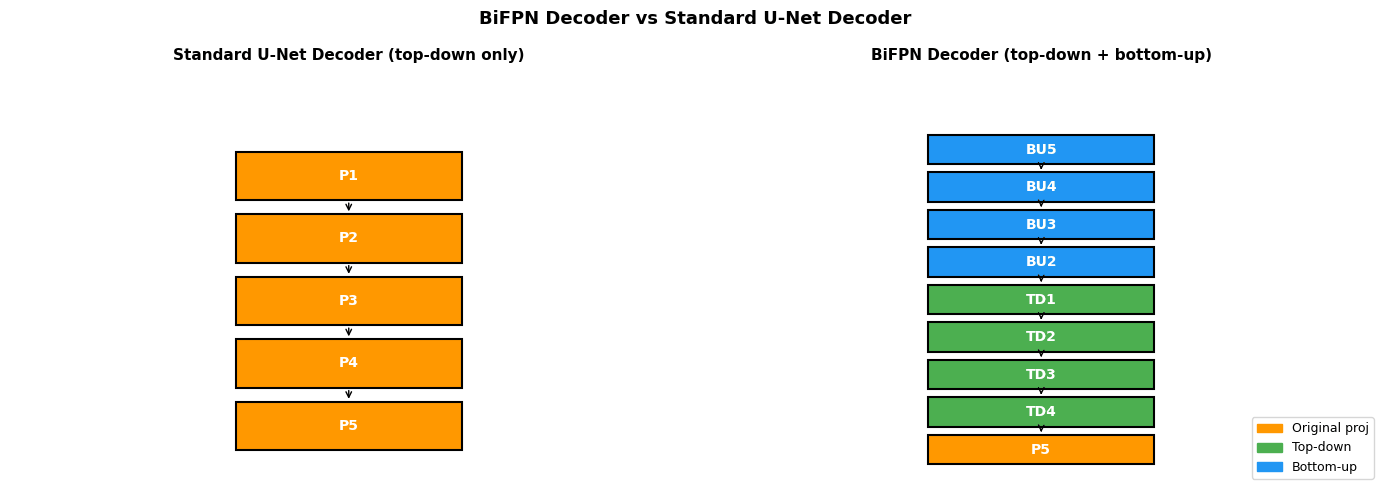

Cell 4 complete — EfficientDet U-Net (BiFPN) built.


In [6]:
# ═══════════════════════════════════════════════════════════════════════════
# CELL 4 ─ EFFICIENTDET U-NET WITH BiFPN DECODER  (BONUS TASK 5)
# PURPOSE : Implement BiFPN (Bidirectional Feature Pyramid Network) as the
#           decoder for U-Net (EfficientDet architecture, Tan et al. 2019).
#
# BiFPN KEY IDEA:
#   - Projects encoder features to a common channel width (bifpn_ch=128)
#   - Performs ONE top-down pass + ONE bottom-up pass with LEARNED weights
#   - Weighted fusion learns relative importance of each scale (fast norm fusion)
#   - Final segmentation output comes from the finest-scale feature map
# ═══════════════════════════════════════════════════════════════════════════

class FastNormFusion(nn.Module):
    """
    Fast Normalised Fusion (EfficientDet): fuses N feature maps of identical
    channel width with learnable positive scalar weights, followed by a conv.
    """
    def __init__(self, num_inputs, channels):
        super().__init__()
        self.w   = nn.Parameter(torch.ones(num_inputs, dtype=torch.float32))
        self.eps = 1e-4
        self.conv = nn.Sequential(
            nn.Conv2d(channels, channels, 3, padding=1, bias=False),
            nn.BatchNorm2d(channels), nn.ReLU(inplace=True)
        )

    def forward(self, feats):
        w = F.relu(self.w)
        w = w / (w.sum() + self.eps)
        fused = sum(feats[i] * w[i] for i in range(len(feats)))
        return self.conv(fused)


class EfficientDetUNet(nn.Module):
    """
    U-Net with BiFPN decoder + joint classifier head.
    Encoder: identical to Base/Attention U-Net (Conv blocks).
    Decoder: BiFPN top-down then bottom-up with fast normalised fusion.
    """
    def __init__(self, in_ch=3, seg_ch=1, num_classes=37, bifpn_ch=128):
        super().__init__()
        # Encoder (same as BaseUNet)
        self.e1=ConvBlock(in_ch,64); self.e2=ConvBlock(64,128)
        self.e3=ConvBlock(128,256);  self.e4=ConvBlock(256,512)
        self.pool=nn.MaxPool2d(2,2); self.bottleneck=ConvBlock(512,1024)

        # Classifier
        self.classifier = nn.Sequential(
            nn.AdaptiveAvgPool2d(1), nn.Flatten(),
            nn.Linear(1024,512), nn.BatchNorm1d(512), nn.ReLU(), nn.Dropout(0.4),
            nn.Linear(512,256), nn.ReLU(), nn.Dropout(0.3),
            nn.Linear(256, num_classes)
        )

        # BiFPN channel projections (normalise all scales to bifpn_ch)
        self.proj = nn.ModuleList([
            nn.Sequential(nn.Conv2d(ch, bifpn_ch, 1, bias=False), nn.BatchNorm2d(bifpn_ch))
            for ch in [64, 128, 256, 512, 1024]
        ])
        self.up = nn.Upsample(scale_factor=2, mode='bilinear', align_corners=False)
        self.down = nn.MaxPool2d(2,2)

        # Top-down path
        self.td4 = FastNormFusion(2, bifpn_ch)
        self.td3 = FastNormFusion(2, bifpn_ch)
        self.td2 = FastNormFusion(2, bifpn_ch)
        self.td1 = FastNormFusion(2, bifpn_ch)

        # Bottom-up path (3 inputs: original proj + top-down + downsampled)
        self.bu2 = FastNormFusion(3, bifpn_ch)
        self.bu3 = FastNormFusion(3, bifpn_ch)
        self.bu4 = FastNormFusion(3, bifpn_ch)
        self.bu5 = FastNormFusion(2, bifpn_ch)

        # Final segmentation upsampling to original resolution
        self.final_up = nn.Sequential(
            nn.Upsample(scale_factor=2, mode='bilinear', align_corners=False),
            nn.Conv2d(bifpn_ch, bifpn_ch, 3, padding=1, bias=False),
            nn.BatchNorm2d(bifpn_ch), nn.ReLU(inplace=True)
        )
        self.seg_head = nn.Conv2d(bifpn_ch, seg_ch, 1)
        self.apply(init_weights)

    def forward(self, x):
        # Encoder
        s1=self.e1(x); s2=self.e2(self.pool(s1))
        s3=self.e3(self.pool(s2)); s4=self.e4(self.pool(s3))
        b =self.bottleneck(self.pool(s4))
        cls = self.classifier(b)

        # Project to BiFPN channels
        p1,p2,p3,p4,p5 = [self.proj[i](f) for i,f in enumerate([s1,s2,s3,s4,b])]

        # Top-down
        td4=self.td4([p4, self.up(p5)])
        td3=self.td3([p3, self.up(td4)])
        td2=self.td2([p2, self.up(td3)])
        td1=self.td1([p1, self.up(td2)])

        # Bottom-up
        out1=td1
        out2=self.bu2([p2, td2, self.down(out1)])
        out3=self.bu3([p3, td3, self.down(out2)])
        out4=self.bu4([p4, td4, self.down(out3)])
        out5=self.bu5([p5,      self.down(out4)])  # finest bottleneck update

        seg = self.seg_head(out1)
        return seg, cls

# ── Parameter Count & Quick Smoke-Test ────────────────────────────────────────
eff_unet = EfficientDetUNet(seg_ch=1, num_classes=NUM_CLASSES)
print(f"EfficientDet U-Net params: {count_params(eff_unet):,}")

dummy = torch.randn(2, 3, 256, 256)
with torch.no_grad():
    seg_out, cls_out = eff_unet(dummy)
print(f"Smoke-test  seg output  : {seg_out.shape}  (expect [2,1,256,256])")
print(f"Smoke-test  cls output  : {cls_out.shape}  (expect [2,{NUM_CLASSES}])")

# ── BiFPN vs Standard Decoder Diagram ─────────────────────────────────────────
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
fig.suptitle('BiFPN Decoder vs Standard U-Net Decoder', fontsize=13, fontweight='bold')

for ax_idx, (title, arrows) in enumerate([
    ('Standard U-Net Decoder (top-down only)',
     [('P5','P4',False),('P4','P3',False),('P3','P2',False),('P2','P1',False)]),
    ('BiFPN Decoder (top-down + bottom-up)',
     [('P5','TD4',False),('TD4','TD3',False),('TD3','TD2',False),('TD2','TD1',False),
      ('TD1','BU2',True),('BU2','BU3',True),('BU3','BU4',True),('BU4','BU5',True)])
]):
    ax = axes[ax_idx]
    ax.set_xlim(0,6); ax.set_ylim(-0.5,len(arrows)+1.5); ax.axis('off')
    ax.set_title(title, fontsize=11, fontweight='bold')
    levels = ['P5','P4','P3','P2','P1'] if ax_idx==0 else ['P5','TD4','TD3','TD2','TD1','BU2','BU3','BU4','BU5']
    for i,lbl in enumerate(levels):
        c='#4CAF50' if 'TD' in lbl else ('#2196F3' if 'BU' in lbl else '#FF9800')
        ax.add_patch(plt.Rectangle((2,i*0.9),2,0.7,color=c,ec='black',lw=1.5))
        ax.text(3,i*0.9+0.35,lbl,ha='center',va='center',fontsize=10,fontweight='bold',color='white')
        if i>0: ax.annotate('',xy=(3,(i-1)*0.9+0.7),xytext=(3,i*0.9),
                            arrowprops=dict(arrowstyle='->',color='black'))

patch_handles = [mpatches.Patch(color='#FF9800',label='Original proj'),
                 mpatches.Patch(color='#4CAF50',label='Top-down'),
                 mpatches.Patch(color='#2196F3',label='Bottom-up')]
axes[1].legend(handles=patch_handles, loc='lower right', fontsize=9)
plt.tight_layout(); plt.show()
print("Cell 4 complete — EfficientDet U-Net (BiFPN) built.")

In [7]:
# ── MEMORY CLEANUP CELL (run before Cell 5) ───────────────────────────────────
import gc, os

# Save all trained model weights to disk first
print("Saving models to disk...")
models_to_save = {
    'base_unet':  base_unet  if 'base_unet'  in dir() else None,
    'att_unet':   att_unet   if 'att_unet'   in dir() else None,
    'eff_unet':   eff_unet   if 'eff_unet'   in dir() else None,
}
for name, model in models_to_save.items():
    if model is not None:
        torch.save(model.state_dict(), f'/kaggle/working/{name}_weights.pth')
        print(f"  ✔ Saved {name} → /kaggle/working/{name}_weights.pth")

# Now delete from RAM
print("\nClearing RAM...")
for var in ['base_unet', 'att_unet', 'eff_unet',
            'image_cache', 'cls_val_tensors', 'cls_test_tensors',
            'train_ds_aug', 'train_ds_no_aug', 'val_ds', 'test_ds',
            'train_loader_aug', 'train_loader_no_aug', 'val_loader', 'test_loader']:
    if var in globals():
        del globals()[var]

gc.collect()
torch.cuda.empty_cache()

# Check RAM after cleanup
import psutil
ram = psutil.virtual_memory()
print(f"RAM after cleanup: {ram.used/1e9:.1f} GB used / {ram.total/1e9:.1f} GB total")
print(f"Disk space: {psutil.disk_usage('/kaggle/working').free/1e9:.1f} GB free")
print("\nReady to run Cell 5.")

Saving models to disk...
  ✔ Saved base_unet → /kaggle/working/base_unet_weights.pth
  ✔ Saved att_unet → /kaggle/working/att_unet_weights.pth
  ✔ Saved eff_unet → /kaggle/working/eff_unet_weights.pth

Clearing RAM...
RAM after cleanup: 1.8 GB used / 33.7 GB total
Disk space: 20.6 GB free

Ready to run Cell 5.


=== Bonus Task 1: Pretrained Classifier Comparison ===

───────────────────────────────────────────────────────
Starting: mobilenet_v2
───────────────────────────────────────────────────────
Downloading: "https://download.pytorch.org/models/mobilenet_v2-7ebf99e0.pth" to /root/.cache/torch/hub/checkpoints/mobilenet_v2-7ebf99e0.pth


100%|██████████| 13.6M/13.6M [00:00<00:00, 123MB/s]


[mobilenet_v2] Ep 1/5:   0%|          | 0/323 [00:00<?, ?it/s]

Corrupt JPEG data: 240 extraneous bytes before marker 0xd9
Corrupt JPEG data: premature end of data segment


  [mobilenet_v2] Ep 1/5  train=0.5234  val=0.8430  lr=9.05e-05
    ✔ Best val=0.8430


...

Corrupt JPEG data: 240 extraneous bytes before marker 0xd9
Corrupt JPEG data: premature end of data segment


  [densenet121] Ep 4/5  train=0.9721  val=0.9251  lr=9.55e-06
    ✔ Best val=0.9251


[densenet121] Ep 5/5:   0%|          | 0/323 [00:00<?, ?it/s]

Corrupt JPEG data: 240 extraneous bytes before marker 0xd9
Corrupt JPEG data: premature end of data segment


  [densenet121] Ep 5/5  train=0.9822  val=0.9323  lr=0.00e+00
    ✔ Best val=0.9323
  Saved to /kaggle/working/densenet121_best.pth
  [densenet121] TEST  acc=0.9297  f1=0.9292



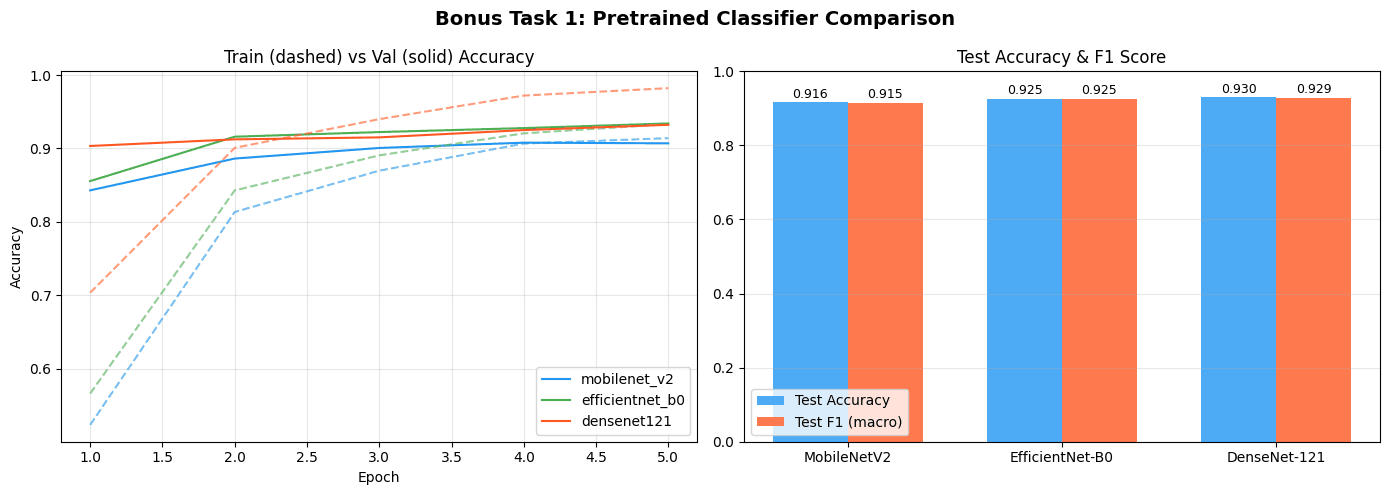


Bonus Task 1 Final Summary:
                    acc    prec     rec      f1
mobilenet_v2     0.9161  0.9167  0.9159  0.9154
efficientnet_b0  0.9252  0.9284  0.9250  0.9251
densenet121      0.9297  0.9306  0.9295  0.9292

Cell 5 complete.


In [8]:
# ═══════════════════════════════════════════════════════════════════════════
# CELL 5 ─ PRE-TRAINED STANDALONE CLASSIFIERS  (BONUS TASK 1)
# ═══════════════════════════════════════════════════════════════════════════

import gc, torchvision.models as tvm
from tqdm.auto import tqdm

CLS_BATCH = 16   # small batch → lower peak RAM

val_cls_transform = A.Compose([
    A.Resize(256, 256),
    A.Normalize(mean=(0.485,0.456,0.406), std=(0.229,0.224,0.225)),
    ToTensorV2()
])
train_cls_transform = A.Compose([
    A.Resize(256, 256),
    A.HorizontalFlip(p=0.5),
    A.ColorJitter(brightness=0.2, contrast=0.2, saturation=0.2, p=0.4),
    A.ShiftScaleRotate(shift_limit=0.05, scale_limit=0.1, rotate_limit=10, p=0.4),
    A.Normalize(mean=(0.485,0.456,0.406), std=(0.229,0.224,0.225)),
    ToTensorV2()
])

class LightClassDataset(Dataset):
    def __init__(self, data_list, transform):
        self.data_list = data_list
        self.transform = transform
    def __len__(self): return len(self.data_list)
    def __getitem__(self, idx):
        item = self.data_list[idx]
        img  = cv2.imread(item['img_path'])
        if img is None:
            img = np.zeros((256,256,3), dtype=np.uint8)
        img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
        return self.transform(image=img)['image'], class_to_idx[item['breed']]

cls_train_ld = DataLoader(LightClassDataset(train_info, train_cls_transform),
                          CLS_BATCH, shuffle=True,  num_workers=2,
                          pin_memory=True, drop_last=True, prefetch_factor=4)
cls_val_ld   = DataLoader(LightClassDataset(val_info,   val_cls_transform),
                          CLS_BATCH, shuffle=False, num_workers=2,
                          pin_memory=True, prefetch_factor=4)
cls_test_ld  = DataLoader(LightClassDataset(test_info,  val_cls_transform),
                          CLS_BATCH, shuffle=False, num_workers=2,
                          pin_memory=True, prefetch_factor=4)

def build_classifier(name):
    if name == 'mobilenet_v2':
        m = tvm.mobilenet_v2(weights=tvm.MobileNet_V2_Weights.DEFAULT)
        m.classifier[1] = nn.Linear(m.last_channel, NUM_CLASSES)
    elif name == 'efficientnet_b0':
        m = tvm.efficientnet_b0(weights=tvm.EfficientNet_B0_Weights.DEFAULT)
        m.classifier[1] = nn.Linear(m.classifier[1].in_features, NUM_CLASSES)
    elif name == 'densenet121':
        m = tvm.densenet121(weights=tvm.DenseNet121_Weights.DEFAULT)
        m.classifier = nn.Linear(m.classifier.in_features, NUM_CLASSES)
    return m

def train_classifier(name, epochs=5, lr=1e-4):
    model  = build_classifier(name).to(device)
    opt    = torch.optim.AdamW(model.parameters(), lr=lr, weight_decay=1e-4)
    sched  = torch.optim.lr_scheduler.CosineAnnealingLR(opt, T_max=epochs)
    crit   = nn.CrossEntropyLoss(label_smoothing=0.1)
    scaler = GradScaler()

    hist = {'train_acc': [], 'val_acc': []}
    best_val, best_wts = 0.0, None

    for ep in range(epochs):
        model.train()
        correct, total, run_loss, step = 0, 0, 0.0, 0
        pbar = tqdm(cls_train_ld, desc=f"[{name}] Ep {ep+1}/{epochs}",
                    leave=False, dynamic_ncols=True, mininterval=2.0)
        for imgs, lbls in pbar:
            imgs = imgs.to(device, non_blocking=True)
            lbls = lbls.to(device, non_blocking=True)
            opt.zero_grad(set_to_none=True)
            with autocast():
                out  = model(imgs)
                loss = crit(out, lbls)
            scaler.scale(loss).backward()
            scaler.step(opt); scaler.update()
            step    += 1
            correct += (out.argmax(1) == lbls).sum().item()
            total   += lbls.size(0)
            run_loss += loss.item()
            if step % 20 == 0:
                pbar.set_postfix(loss=f"{run_loss/step:.4f}", acc=f"{correct/total:.3f}")

        sched.step()
        train_acc = correct / total

        model.eval()
        vc, vt_cnt = 0, 0
        with torch.no_grad():
            for imgs, lbls in cls_val_ld:
                out   = model(imgs.to(device, non_blocking=True))
                vc    += (out.argmax(1) == lbls.to(device)).sum().item()
                vt_cnt += lbls.size(0)
        val_acc = vc / vt_cnt

        hist['train_acc'].append(train_acc)
        hist['val_acc'].append(val_acc)
        print(f"  [{name}] Ep {ep+1}/{epochs}  "
              f"train={train_acc:.4f}  val={val_acc:.4f}  "
              f"lr={opt.param_groups[0]['lr']:.2e}")
        if val_acc > best_val:
            best_val = val_acc
            best_wts = copy.deepcopy(model.state_dict())
            print(f"    ✔ Best val={best_val:.4f}")

    model.load_state_dict(best_wts)
    # Save best weights to disk
    torch.save(best_wts, f'/kaggle/working/{name}_best.pth')
    print(f"  Saved to /kaggle/working/{name}_best.pth")

    model.eval()
    all_p, all_t = [], []
    with torch.no_grad():
        for imgs, lbls in cls_test_ld:
            all_p.extend(model(imgs.to(device, non_blocking=True)).argmax(1).cpu().tolist())
            all_t.extend(lbls.tolist())
    prec, rec, f1, _ = precision_recall_fscore_support(all_t, all_p, average='macro', zero_division=0)
    tm = {'acc': accuracy_score(all_t, all_p), 'prec': prec, 'rec': rec, 'f1': f1}
    print(f"  [{name}] TEST  acc={tm['acc']:.4f}  f1={tm['f1']:.4f}\n")

    # Free memory before next model
    model.cpu(); del model, opt, scaler, best_wts
    gc.collect(); torch.cuda.empty_cache()
    return hist, tm

# ── Run all 3 ─────────────────────────────────────────────────────────────────
CLS_EPOCHS = 5
print("=== Bonus Task 1: Pretrained Classifier Comparison ===\n")
cls_results = {}
for cls_name in ['mobilenet_v2', 'efficientnet_b0', 'densenet121']:
    print(f"{'─'*55}\nStarting: {cls_name}\n{'─'*55}")
    hist, tm = train_classifier(cls_name, epochs=CLS_EPOCHS)
    cls_results[cls_name] = {'hist': hist, 'test': tm}
    gc.collect(); torch.cuda.empty_cache()

# ── Comparison Plot ────────────────────────────────────────────────────────────
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
fig.suptitle('Bonus Task 1: Pretrained Classifier Comparison', fontsize=14, fontweight='bold')
colors_cls = {'mobilenet_v2':'#2196F3', 'efficientnet_b0':'#4CAF50', 'densenet121':'#FF5722'}
eps = range(1, CLS_EPOCHS + 1)

for name, data in cls_results.items():
    axes[0].plot(eps, data['hist']['train_acc'], '--', color=colors_cls[name], alpha=0.6)
    axes[0].plot(eps, data['hist']['val_acc'],   '-',  color=colors_cls[name], label=name)
axes[0].set_title('Train (dashed) vs Val (solid) Accuracy')
axes[0].set_xlabel('Epoch'); axes[0].set_ylabel('Accuracy')
axes[0].legend(); axes[0].grid(True, alpha=0.3)

names = list(cls_results.keys())
accs  = [cls_results[n]['test']['acc'] for n in names]
f1s   = [cls_results[n]['test']['f1']  for n in names]
x     = np.arange(len(names)); width = 0.35
bars1 = axes[1].bar(x-width/2, accs, width, label='Test Accuracy',   color='#2196F3', alpha=0.8)
bars2 = axes[1].bar(x+width/2, f1s,  width, label='Test F1 (macro)', color='#FF5722', alpha=0.8)
for b in list(bars1) + list(bars2):
    axes[1].text(b.get_x()+b.get_width()/2, b.get_height()+0.005,
                 f'{b.get_height():.3f}', ha='center', va='bottom', fontsize=9)
axes[1].set_xticks(x)
axes[1].set_xticklabels(['MobileNetV2', 'EfficientNet-B0', 'DenseNet-121'])
axes[1].set_ylim(0, 1); axes[1].set_title('Test Accuracy & F1 Score')
axes[1].legend(); axes[1].grid(True, alpha=0.3, axis='y')
plt.tight_layout(); plt.show()

print("\nBonus Task 1 Final Summary:")
df_cls = pd.DataFrame({n: cls_results[n]['test'] for n in names}).T.round(4)
print(df_cls.to_string())
print("\nCell 5 complete.")

In [9]:
# ── COMPLETE RESTORE CELL (replace your existing restore cell with this) ───────
import gc
print("Restoring all variables...")

# U-Net models
base_unet = BaseUNet(seg_ch=1, num_classes=NUM_CLASSES)
base_unet.load_state_dict(torch.load('/kaggle/working/base_unet_weights.pth', map_location=device))
base_unet = base_unet.to(device); print("✔ base_unet")

att_unet = AttentionUNet(seg_ch=1, num_classes=NUM_CLASSES)
att_unet.load_state_dict(torch.load('/kaggle/working/att_unet_weights.pth', map_location=device))
att_unet = att_unet.to(device); print("✔ att_unet")

eff_unet = EfficientDetUNet(seg_ch=1, num_classes=NUM_CLASSES)
eff_unet.load_state_dict(torch.load('/kaggle/working/eff_unet_weights.pth', map_location=device))
eff_unet = eff_unet.to(device); print("✔ eff_unet")

# Datasets
train_ds_aug    = PetDataset(train_info, transform=train_transform_aug)
train_ds_no_aug = PetDataset(train_info, transform=train_transform_no_aug)
val_ds          = PetDataset(val_info,   transform=val_test_transform)
test_ds         = PetDataset(test_info,  transform=val_test_transform)
print("✔ datasets")

# DataLoaders
train_loader_aug    = DataLoader(train_ds_aug,    batch_size=BATCH_SIZE, shuffle=True,
                                 num_workers=2, pin_memory=True, drop_last=True)
train_loader_no_aug = DataLoader(train_ds_no_aug, batch_size=BATCH_SIZE, shuffle=True,
                                 num_workers=2, pin_memory=True, drop_last=True)
val_loader  = DataLoader(val_ds,   batch_size=BATCH_SIZE, shuffle=False,
                         num_workers=2, pin_memory=True)
test_loader = DataLoader(test_ds,  batch_size=BATCH_SIZE, shuffle=False,
                         num_workers=2, pin_memory=True)
print("✔ dataloaders")

gc.collect(); torch.cuda.empty_cache()
print("\n✔ All variables restored. Ready to continue from any cell.")




Restoring all variables...
✔ base_unet
✔ att_unet
✔ eff_unet
✔ datasets
✔ dataloaders

✔ All variables restored. Ready to continue from any cell.


In [7]:
# ═══════════════════════════════════════════════════════════════════════════
# CELL 6 ─ LOSS FUNCTIONS, METRICS & TRAINING ENGINE
# PURPOSE : Define combined segmentation loss, proper mIoU metric, full
#           training / evaluation loops with Mixed Precision, LR Scheduler,
#           and Gradient Clipping.
#
# IMPROVEMENTS over original:
#   ✔ AdamW optimizer (L2 weight decay) instead of Adam
#   ✔ CosineAnnealingWarmRestarts LR scheduler
#   ✔ torch.cuda.amp mixed precision (2× faster on T4)
#   ✔ Gradient clipping (max_norm=1.0) for training stability
#   ✔ label_smoothing=0.1 in CrossEntropyLoss for regularisation
#   ✔ Correct mIoU: per-class IoU mean (not just foreground class)
#   ✔ Train metrics tracked (not just val)
# ═══════════════════════════════════════════════════════════════════════════


from tqdm.auto import tqdm

class DiceLoss(nn.Module):
    def __init__(self, smooth=1e-6):
        super().__init__(); self.smooth=smooth
    def forward(self, logits, targets):
        p = torch.sigmoid(logits).view(-1); t = targets.view(-1)
        inter = (p*t).sum()
        return 1 - (2*inter+self.smooth) / (p.sum()+t.sum()+self.smooth)

class FocalLoss(nn.Module):
    def __init__(self, alpha=0.8, gamma=2):
        super().__init__(); self.alpha=alpha; self.gamma=gamma
    def forward(self, logits, targets):
        bce = F.binary_cross_entropy_with_logits(logits, targets, reduction='none')
        p_t = torch.exp(-bce)
        return (self.alpha * (1-p_t)**self.gamma * bce).mean()

def seg_loss_fn(logits, targets, is_binary=True):
    if is_binary:
        return (nn.BCEWithLogitsLoss()(logits, targets)
                + DiceLoss()(logits, targets)
                + 0.5 * FocalLoss()(logits, targets))
    else:
        return nn.CrossEntropyLoss()(logits, targets)

cls_loss_fn = nn.CrossEntropyLoss(label_smoothing=0.1)

def compute_miou(preds, targets, num_classes):
    ious = []
    for c in range(num_classes):
        pred_c = (preds == c); targ_c = (targets == c)
        inter  = (pred_c & targ_c).sum().item()
        union  = (pred_c | targ_c).sum().item()
        if union > 0: ious.append(inter / union)
    return float(np.mean(ious)) if ious else 0.0

def compute_seg_metrics(seg_logits, seg_targets, is_binary=True):
    if is_binary:
        preds = (torch.sigmoid(seg_logits) > 0.5).long().view(-1)
        targs = seg_targets.long().view(-1)
        n_cls = 2
    else:
        preds = torch.argmax(seg_logits, 1).view(-1)
        targs = seg_targets.view(-1)
        n_cls = 3
    pixel_acc = (preds == targs).float().mean().item()
    miou      = compute_miou(preds, targs, n_cls)
    if is_binary:
        inter = (preds & targs).sum().item()
        dice  = (2*inter+1e-6) / (preds.sum().item()+targs.sum().item()+1e-6)
    else:
        dices = []
        for c in range(n_cls):
            p_c=(preds==c).float(); t_c=(targs==c).float()
            inter=(p_c*t_c).sum().item()
            dices.append((2*inter+1e-6)/(p_c.sum().item()+t_c.sum().item()+1e-6))
        dice = float(np.mean(dices))
    return pixel_acc, miou, dice

def compute_cls_metrics(cls_logits, cls_targets):
    p = cls_logits.argmax(1).cpu().numpy()
    t = cls_targets.cpu().numpy()
    prec, rec, f1, _ = precision_recall_fscore_support(t, p, average='macro', zero_division=0)
    return accuracy_score(t, p), prec, rec, f1

# ── run_epoch: NOW WITH TQDM PROGRESS BAR ─────────────────────────────────────
def run_epoch(model, loader, optimizer, scaler, is_train, is_binary, device,
              desc=""):
    model.train() if is_train else model.eval()
    total = {'loss':0,'px_acc':0,'miou':0,'dice':0,
             'cls_acc':0,'cls_prec':0,'cls_rec':0,'cls_f1':0}
    steps = 0
    ctx = torch.enable_grad() if is_train else torch.no_grad()

    pbar = tqdm(loader, desc=desc, leave=False,
                dynamic_ncols=True, mininterval=2.0)

    with ctx:
        for imgs, lbls, bin_m, tri_m in pbar:
            imgs = imgs.to(device, non_blocking=True)
            lbls = lbls.to(device, non_blocking=True)
            seg_t = (bin_m if is_binary else tri_m).to(device, non_blocking=True)

            if is_train:
                optimizer.zero_grad(set_to_none=True)

            with autocast():
                seg_out, cls_out = model(imgs)
                l_seg = seg_loss_fn(seg_out, seg_t, is_binary)
                l_cls = cls_loss_fn(cls_out, lbls)
                loss  = l_seg + l_cls

            if is_train:
                scaler.scale(loss).backward()
                scaler.unscale_(optimizer)
                torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)
                scaler.step(optimizer); scaler.update()

            px_acc, miou, dice = compute_seg_metrics(
                seg_out.detach(), seg_t.detach(), is_binary)
            cls_acc, cls_prec, cls_rec, cls_f1 = compute_cls_metrics(
                cls_out.detach(), lbls)

            total['loss']    += loss.item()
            total['px_acc']  += px_acc;   total['miou']    += miou
            total['dice']    += dice;     total['cls_acc'] += cls_acc
            total['cls_prec']+= cls_prec; total['cls_rec'] += cls_rec
            total['cls_f1']  += cls_f1;   steps += 1

            # Live postfix — updates every mininterval seconds
            if steps % 5 == 0:
                pbar.set_postfix(
                    loss  = f"{total['loss']/steps:.4f}",
                    dice  = f"{total['dice']/steps:.4f}",
                    acc   = f"{total['cls_acc']/steps:.3f}"
                )

    pbar.close()
    return {k: v/steps for k,v in total.items()}

# ── train_model & plot_training_history (unchanged) ───────────────────────────
def train_model(model, name, train_ld, val_ld, device,
                epochs=10, is_binary=True, lr=3e-4, weight_decay=1e-4):
    print(f"\n{'='*55}\n  Training: {name}\n{'='*55}")
    if num_gpus > 1:
        model = nn.DataParallel(model)
    model = model.to(device)

    opt    = torch.optim.AdamW(model.parameters(), lr=lr, weight_decay=weight_decay)
    sched  = torch.optim.lr_scheduler.CosineAnnealingWarmRestarts(
                 opt, T_0=max(epochs//2, 1), T_mult=1)
    scaler = GradScaler()

    best_dice, best_wts = 0.0, None
    hist = {k:[] for k in ['train_loss','val_loss','train_dice','val_dice',
                            'train_miou','val_miou','train_cls_acc','val_cls_acc',
                            'train_px_acc','val_px_acc','lr']}
    t0 = time.time()

    for ep in range(1, epochs+1):
        tr = run_epoch(model, train_ld, opt, scaler, True,  is_binary, device,
                       desc=f"  [{name}] Ep {ep}/{epochs} TRAIN")
        vl = run_epoch(model, val_ld,   opt, scaler, False, is_binary, device,
                       desc=f"  [{name}] Ep {ep}/{epochs}  VAL ")
        sched.step()

        for key, val in [('train_loss',tr['loss']),('val_loss',vl['loss']),
                         ('train_dice',tr['dice']),('val_dice',vl['dice']),
                         ('train_miou',tr['miou']),('val_miou',vl['miou']),
                         ('train_cls_acc',tr['cls_acc']),('val_cls_acc',vl['cls_acc']),
                         ('train_px_acc',tr['px_acc']),('val_px_acc',vl['px_acc']),
                         ('lr', opt.param_groups[0]['lr'])]:
            hist[key].append(val)

        # Permanent per-epoch summary line
        print(f"  Ep {ep:3d}/{epochs} "
              f"| Loss {tr['loss']:.4f}/{vl['loss']:.4f} "
              f"| Dice {tr['dice']:.4f}/{vl['dice']:.4f} "
              f"| mIoU {tr['miou']:.4f}/{vl['miou']:.4f} "
              f"| ClsAcc {tr['cls_acc']:.4f}/{vl['cls_acc']:.4f} "
              f"| LR {opt.param_groups[0]['lr']:.2e}")

        if vl['dice'] > best_dice:
            best_dice = vl['dice']
            raw = model.module if num_gpus>1 else model
            best_wts = copy.deepcopy(raw.state_dict())
            torch.save(best_wts, f"{name.replace(' ','_')}_best.pth")
            print(f"    ✔ Best Dice={best_dice:.4f} saved")

    elapsed = (time.time()-t0)/60
    print(f"\n  Finished in {elapsed:.1f} min | Best Val Dice: {best_dice:.4f}")
    raw_model = model.module if num_gpus>1 else model
    raw_model.load_state_dict(best_wts)
    return raw_model, hist

def plot_training_history(hist, name):
    eps = range(1, len(hist['train_loss'])+1)
    fig, axes = plt.subplots(2, 2, figsize=(14, 9))
    fig.suptitle(f'Training Statistics — {name}', fontsize=14, fontweight='bold')
    for ax, (tk, vk, ylabel, title) in zip(axes.flat, [
        ('train_loss','val_loss','Loss','Loss Curve'),
        ('train_dice','val_dice','Dice Score','Segmentation Dice'),
        ('train_miou','val_miou','mIoU','Mean IoU'),
        ('train_cls_acc','val_cls_acc','Accuracy','Classification Accuracy')
    ]):
        ax.plot(eps, hist[tk], '--o', ms=4, label='Train', alpha=0.8)
        ax.plot(eps, hist[vk], '-o',  ms=4, label='Val',   alpha=0.9)
        ax.set_title(title, fontweight='bold'); ax.set_xlabel('Epoch')
        ax.set_ylabel(ylabel); ax.legend(); ax.grid(True, alpha=0.3)
    ax_lr = axes[1,1].twinx()
    ax_lr.plot(eps, hist['lr'], ':', color='red', alpha=0.5)
    ax_lr.set_ylabel('LR', color='red')
    plt.tight_layout(); plt.show()

print("Cell 6 complete — training engine ready.")

Cell 6 complete — training engine ready.


=== Bonus Task 4: Hyperparameter Tuning ===
  Probing: AdamW  | LR=3e-04 ... 

  0%|          | 0/161 [00:00<?, ?it/s]

  0%|          | 0/35 [00:00<?, ?it/s]

Corrupt JPEG data: 240 extraneous bytes before marker 0xd9
Corrupt JPEG data: premature end of data segment


Dice=0.7318 | mIoU=0.5668 | ClsAcc=0.0630
  Probing: Adam   | LR=3e-04 ... 

...

Dice=0.6930 | mIoU=0.4922 | ClsAcc=0.0354
  Probing: SGD    | LR=1e-03 ... 

  0%|          | 0/161 [00:00<?, ?it/s]

  0%|          | 0/35 [00:00<?, ?it/s]

Corrupt JPEG data: 240 extraneous bytes before marker 0xd9
Corrupt JPEG data: premature end of data segment


Dice=0.5120 | mIoU=0.3727 | ClsAcc=0.0437

Hyperparameter Search Results (sorted by Val Dice):
Optimizer     LR  Val Dice  Val mIoU  Val Cls Acc  Val Loss
     Adam 0.0003    0.7593    0.6341       0.0434    4.4934
    AdamW 0.0003    0.7318    0.5668       0.0630    4.6467
    AdamW 0.0001    0.7244    0.5564       0.0641    4.6365
    AdamW 0.0010    0.7093    0.5415       0.0420    4.7689
     Adam 0.0001    0.7071    0.5260       0.0654    5.0946
     Adam 0.0010    0.6930    0.4922       0.0354    4.8276
      SGD 0.0010    0.5120    0.3727       0.0437    6.7922
      SGD 0.0001    0.5073    0.3353       0.0232    7.7483
      SGD 0.0003    0.2389    0.3437       0.0332    8.5485


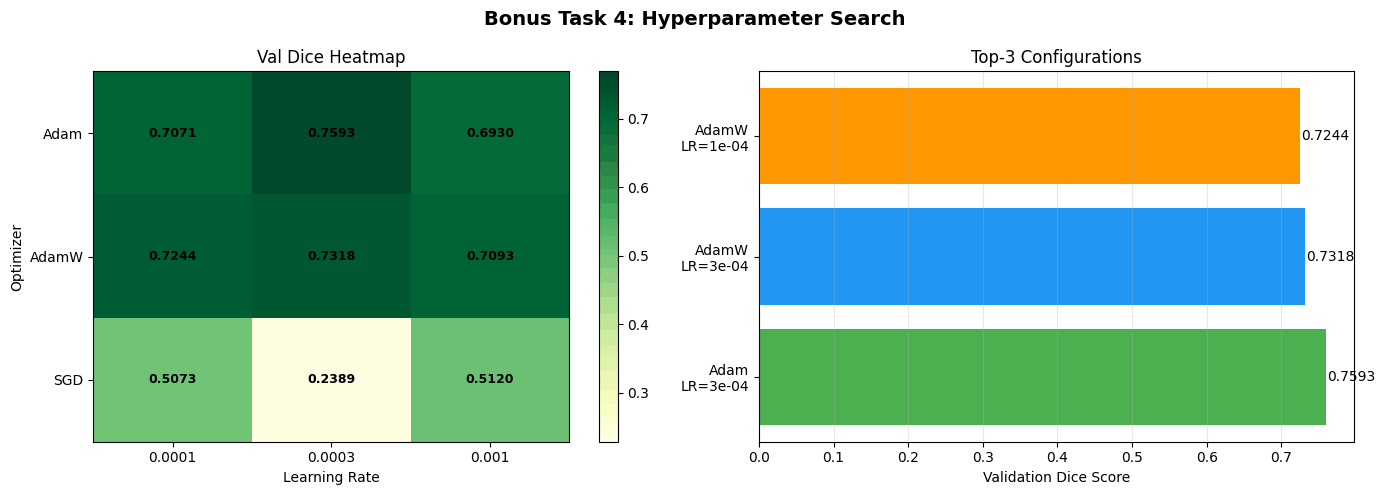


→ Best config: Optimizer=Adam | LR=0.0003
Cell 7 complete — hyperparameter tuning done.


In [11]:
# ═══════════════════════════════════════════════════════════════════════════
# CELL 7 ─ HYPERPARAMETER TUNING  (BONUS TASK 4)
# PURPOSE : Systematically test optimizer × learning-rate combinations on
#           Base U-Net (1 epoch each) to identify the best starting point.
#           Then show a heatmap of validation Dice scores.
# ═══════════════════════════════════════════════════════════════════════════

def run_hparam_search(train_ld, val_ld, device, probe_epochs=1):
    """
    Probe combinations of optimiser × LR on BaseUNet (1 epoch for speed).
    Returns a DataFrame of results.
    """
    lrs        = [3e-4, 1e-4, 1e-3]
    optimizers = ['AdamW', 'Adam', 'SGD']

    records = []
    for lr in lrs:
        for opt_name in optimizers:
            print(f"  Probing: {opt_name:6s} | LR={lr:.0e} ...", end=' ')
            m = BaseUNet(seg_ch=1, num_classes=NUM_CLASSES)
            if num_gpus>1: m = nn.DataParallel(m)
            m = m.to(device)

            if opt_name == 'AdamW':
                opt = torch.optim.AdamW(m.parameters(), lr=lr, weight_decay=1e-4)
            elif opt_name == 'Adam':
                opt = torch.optim.Adam(m.parameters(), lr=lr)
            else:
                opt = torch.optim.SGD(m.parameters(), lr=lr, momentum=0.9, weight_decay=1e-4)

            scaler = GradScaler()
            for _ in range(probe_epochs):
                run_epoch(m, train_ld, opt, scaler, True,  True, device)
            vl = run_epoch(m, val_ld, opt, scaler, False, True, device)

            records.append({'Optimizer':opt_name, 'LR':lr,
                            'Val Dice':round(vl['dice'],4),
                            'Val mIoU':round(vl['miou'],4),
                            'Val Cls Acc':round(vl['cls_acc'],4),
                            'Val Loss':round(vl['loss'],4)})
            print(f"Dice={vl['dice']:.4f} | mIoU={vl['miou']:.4f} | ClsAcc={vl['cls_acc']:.4f}")
            del m, opt; torch.cuda.empty_cache()

    df = pd.DataFrame(records).sort_values('Val Dice', ascending=False)
    return df

print("=== Bonus Task 4: Hyperparameter Tuning ===")
hparam_df = run_hparam_search(train_loader_aug, val_loader, device, probe_epochs=1)

print("\nHyperparameter Search Results (sorted by Val Dice):")
print(hparam_df.to_string(index=False))

# ── Heatmap Visualisation ─────────────────────────────────────────────────────
pivot = hparam_df.pivot(index='Optimizer', columns='LR', values='Val Dice')
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
fig.suptitle('Bonus Task 4: Hyperparameter Search', fontsize=14, fontweight='bold')

im = axes[0].imshow(pivot.values, cmap='YlGn', aspect='auto',
                    vmin=pivot.values.min()-0.01, vmax=pivot.values.max()+0.01)
axes[0].set_xticks(range(len(pivot.columns))); axes[0].set_xticklabels(pivot.columns)
axes[0].set_yticks(range(len(pivot.index)));   axes[0].set_yticklabels(pivot.index)
axes[0].set_xlabel('Learning Rate'); axes[0].set_ylabel('Optimizer')
axes[0].set_title('Val Dice Heatmap')
plt.colorbar(im, ax=axes[0])
for i in range(len(pivot.index)):
    for j in range(len(pivot.columns)):
        axes[0].text(j, i, f'{pivot.values[i,j]:.4f}', ha='center', va='center',
                     fontsize=9, fontweight='bold')

top3 = hparam_df.head(3)
axes[1].barh(range(len(top3)), top3['Val Dice'].values,
             color=['#4CAF50','#2196F3','#FF9800'])
axes[1].set_yticks(range(len(top3)))
axes[1].set_yticklabels([f"{r['Optimizer']}\nLR={r['LR']:.0e}" for _,r in top3.iterrows()])
axes[1].set_xlabel('Validation Dice Score')
axes[1].set_title('Top-3 Configurations')
for i, v in enumerate(top3['Val Dice'].values):
    axes[1].text(v+0.002, i, f'{v:.4f}', va='center', fontsize=10)
axes[1].grid(True, alpha=0.3, axis='x')
plt.tight_layout(); plt.show()

# Extract best config
best_row = hparam_df.iloc[0]
print(f"\n→ Best config: Optimizer={best_row['Optimizer']} | LR={best_row['LR']}")
print("Cell 7 complete — hyperparameter tuning done.")

Training with LR=3.00e-04 for 10 epochs each.

[Run A] Base U-Net — No Augmentation

  Training: BaseUNet_NoAug


  [BaseUNet_NoAug] Ep 1/10 TRAIN:   0%|          | 0/161 [00:00<?, ?it/s]

  [BaseUNet_NoAug] Ep 1/10  VAL :   0%|          | 0/35 [00:00<?, ?it/s]

Corrupt JPEG data: 240 extraneous bytes before marker 0xd9
Corrupt JPEG data: premature end of data segment


  Ep   1/10 | Loss 5.0559/4.6569 | Dice 0.7001/0.7445 | mIoU 0.5883/0.5876 | ClsAcc 0.0338/0.0443 | LR 2.71e-04
    ✔ Best Dice=0.7445 saved


...

  Ep   9/10 | Loss 3.2563/3.2040 | Dice 0.8869/0.8844 | mIoU 0.8226/0.8169 | ClsAcc 0.2387/0.2629 | LR 2.86e-05
    ✔ Best Dice=0.8844 saved


  [BaseUNet_NoAug] Ep 10/10 TRAIN:   0%|          | 0/161 [00:00<?, ?it/s]

  [BaseUNet_NoAug] Ep 10/10  VAL :   0%|          | 0/35 [00:00<?, ?it/s]

Corrupt JPEG data: 240 extraneous bytes before marker 0xd9
Corrupt JPEG data: premature end of data segment


  Ep  10/10 | Loss 3.0700/2.8876 | Dice 0.8953/0.8926 | mIoU 0.8348/0.8306 | ClsAcc 0.2902/0.3689 | LR 3.00e-04
    ✔ Best Dice=0.8926 saved

  Finished in 17.9 min | Best Val Dice: 0.8926


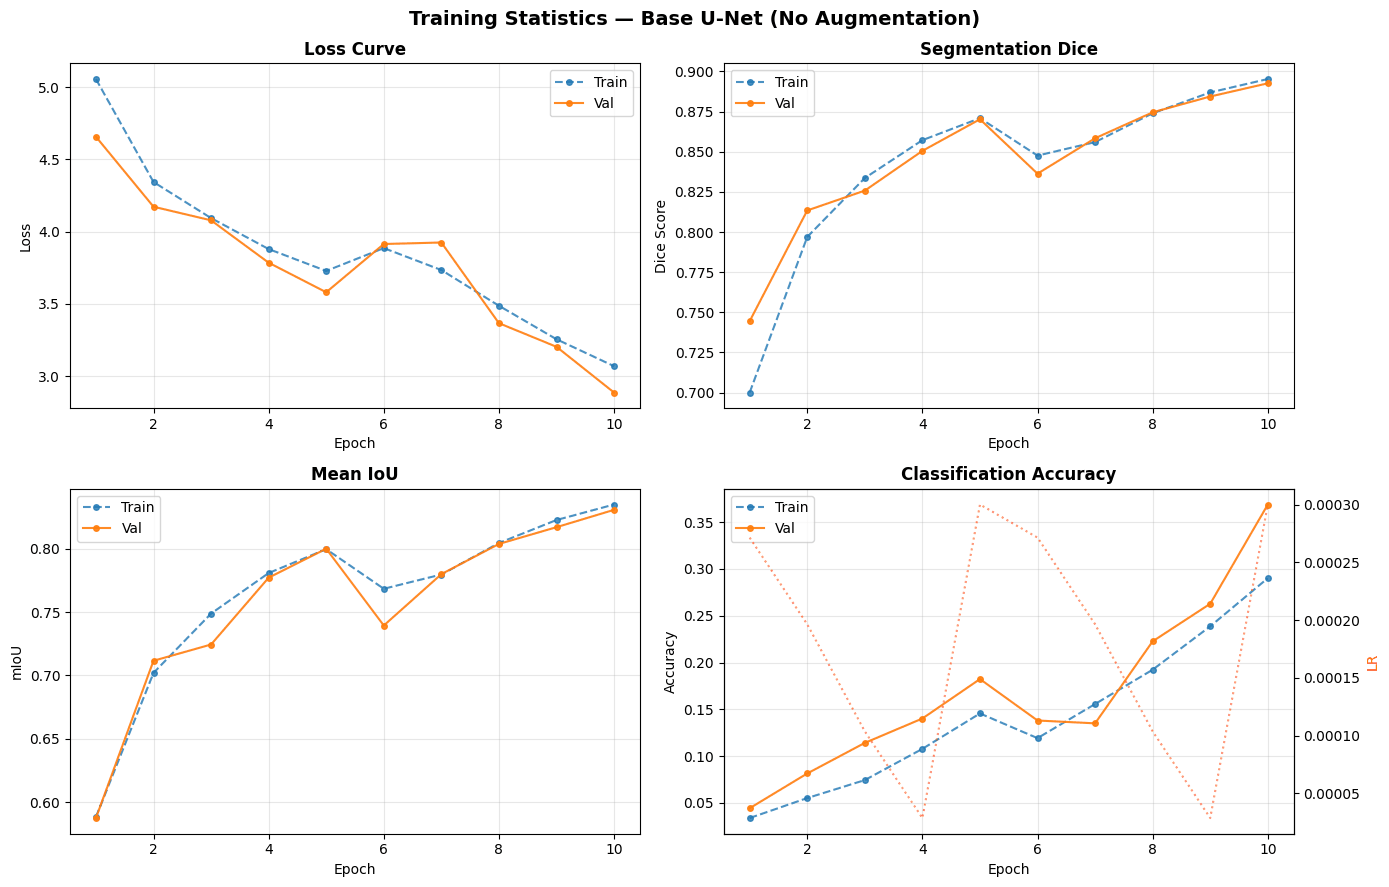

[Run B] Base U-Net — With Augmentation

  Training: BaseUNet_Aug


  [BaseUNet_Aug] Ep 1/10 TRAIN:   0%|          | 0/161 [00:00<?, ?it/s]

  [BaseUNet_Aug] Ep 1/10  VAL :   0%|          | 0/35 [00:00<?, ?it/s]

Corrupt JPEG data: 240 extraneous bytes before marker 0xd9
Corrupt JPEG data: premature end of data segment


  Ep   1/10 | Loss 5.1875/4.6714 | Dice 0.6780/0.7046 | mIoU 0.5163/0.5753 | ClsAcc 0.0363/0.0380 | LR 2.71e-04
    ✔ Best Dice=0.7046 saved


...

  Ep   9/10 | Loss 3.5336/3.3714 | Dice 0.8757/0.8627 | mIoU 0.7838/0.7785 | ClsAcc 0.1972/0.2313 | LR 2.86e-05
    ✔ Best Dice=0.8627 saved


  [BaseUNet_Aug] Ep 10/10 TRAIN:   0%|          | 0/161 [00:00<?, ?it/s]

  [BaseUNet_Aug] Ep 10/10  VAL :   0%|          | 0/35 [00:00<?, ?it/s]

Corrupt JPEG data: 240 extraneous bytes before marker 0xd9
Corrupt JPEG data: premature end of data segment


  Ep  10/10 | Loss 3.3999/3.1792 | Dice 0.8835/0.8800 | mIoU 0.7962/0.8131 | ClsAcc 0.2176/0.2839 | LR 3.00e-04
    ✔ Best Dice=0.8800 saved

  Finished in 18.1 min | Best Val Dice: 0.8800


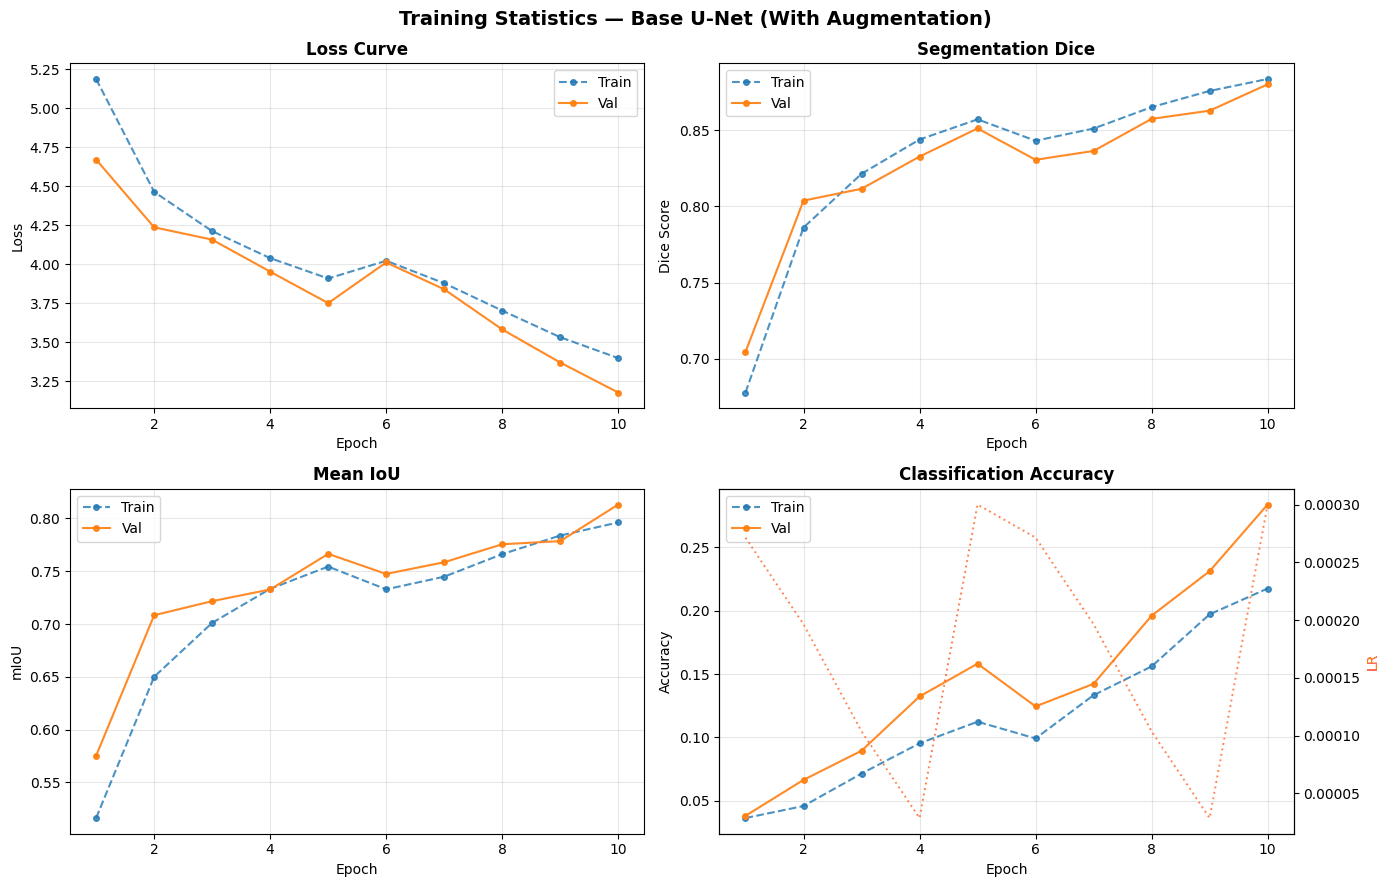

[Run C] Attention U-Net — With Augmentation

  Training: AttentionUNet_Aug


  [AttentionUNet_Aug] Ep 1/10 TRAIN:   0%|          | 0/161 [00:00<?, ?it/s]

  [AttentionUNet_Aug] Ep 1/10  VAL :   0%|          | 0/35 [00:00<?, ?it/s]

Corrupt JPEG data: 240 extraneous bytes before marker 0xd9
Corrupt JPEG data: premature end of data segment


  Ep   1/10 | Loss 5.0999/4.6480 | Dice 0.6918/0.7268 | mIoU 0.5067/0.5611 | ClsAcc 0.0309/0.0511 | LR 2.71e-04
    ✔ Best Dice=0.7268 saved


...

  Ep   9/10 | Loss 3.6264/3.4656 | Dice 0.8734/0.8720 | mIoU 0.7802/0.8028 | ClsAcc 0.1727/0.1820 | LR 2.86e-05
    ✔ Best Dice=0.8720 saved


  [AttentionUNet_Aug] Ep 10/10 TRAIN:   0%|          | 0/161 [00:00<?, ?it/s]

  [AttentionUNet_Aug] Ep 10/10  VAL :   0%|          | 0/35 [00:00<?, ?it/s]

Corrupt JPEG data: 240 extraneous bytes before marker 0xd9
Corrupt JPEG data: premature end of data segment


  Ep  10/10 | Loss 3.4965/3.2989 | Dice 0.8826/0.8760 | mIoU 0.7945/0.8054 | ClsAcc 0.2019/0.2404 | LR 3.00e-04
    ✔ Best Dice=0.8760 saved

  Finished in 20.0 min | Best Val Dice: 0.8760


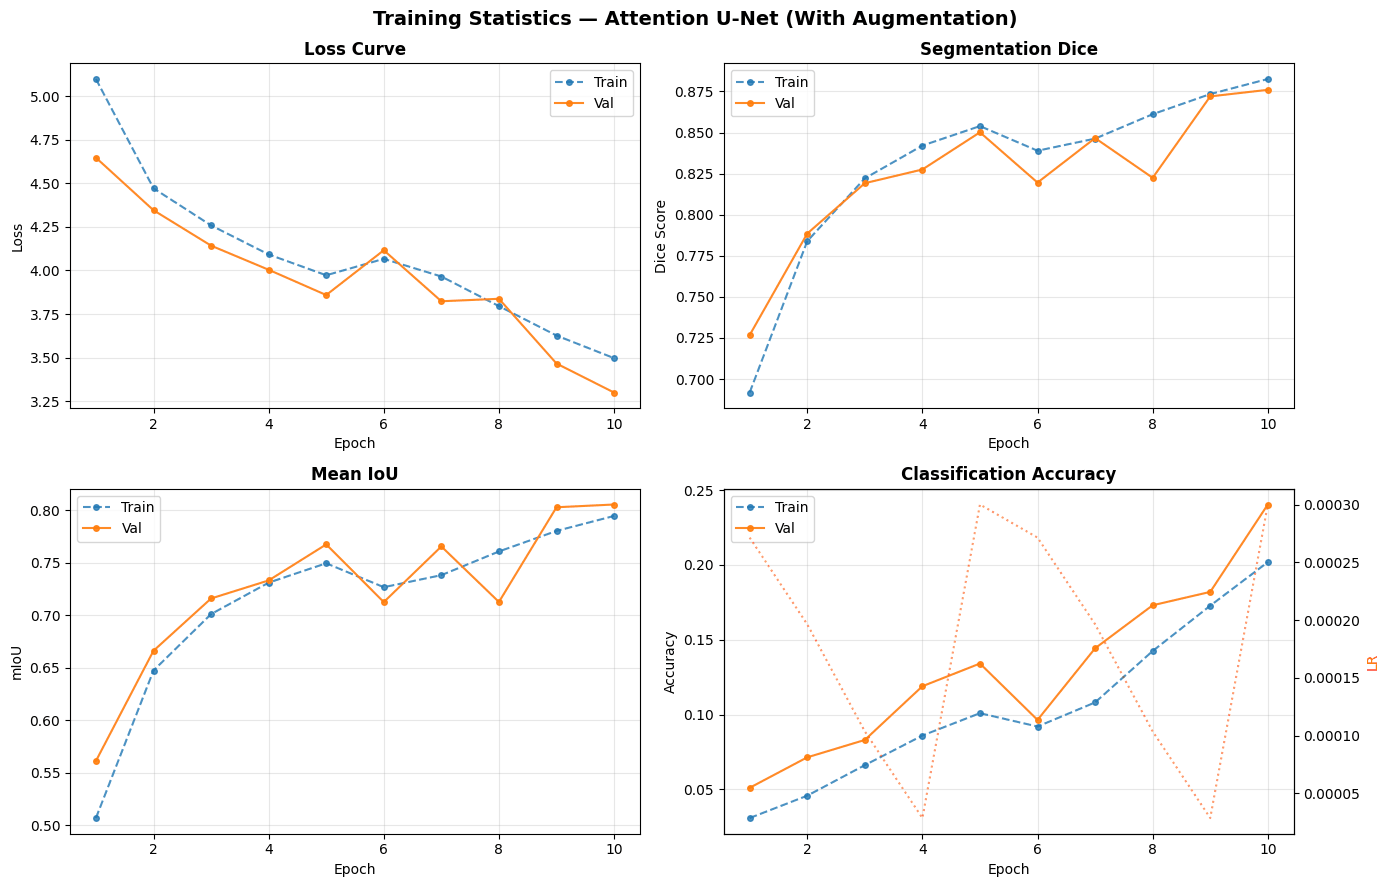

[Run D] EfficientDet U-Net (BiFPN) — With Augmentation [Bonus Task 5]

  Training: EfficientDetUNet_Aug


  [EfficientDetUNet_Aug] Ep 1/10 TRAIN:   0%|          | 0/161 [00:00<?, ?it/s]

  [EfficientDetUNet_Aug] Ep 1/10  VAL :   0%|          | 0/35 [00:00<?, ?it/s]

Corrupt JPEG data: 240 extraneous bytes before marker 0xd9
Corrupt JPEG data: premature end of data segment


  Ep   1/10 | Loss 5.3438/4.6375 | Dice 0.6855/0.7328 | mIoU 0.5396/0.5721 | ClsAcc 0.0371/0.0645 | LR 2.71e-04
    ✔ Best Dice=0.7328 saved


...

  Ep   9/10 | Loss 3.5100/3.2774 | Dice 0.8642/0.8590 | mIoU 0.7659/0.7774 | ClsAcc 0.2153/0.2613 | LR 2.86e-05
    ✔ Best Dice=0.8590 saved


  [EfficientDetUNet_Aug] Ep 10/10 TRAIN:   0%|          | 0/161 [00:00<?, ?it/s]

  [EfficientDetUNet_Aug] Ep 10/10  VAL :   0%|          | 0/35 [00:00<?, ?it/s]

Corrupt JPEG data: 240 extraneous bytes before marker 0xd9
Corrupt JPEG data: premature end of data segment


  Ep  10/10 | Loss 3.3398/3.1186 | Dice 0.8753/0.8672 | mIoU 0.7832/0.7894 | ClsAcc 0.2477/0.3252 | LR 3.00e-04
    ✔ Best Dice=0.8672 saved

  Finished in 17.8 min | Best Val Dice: 0.8672


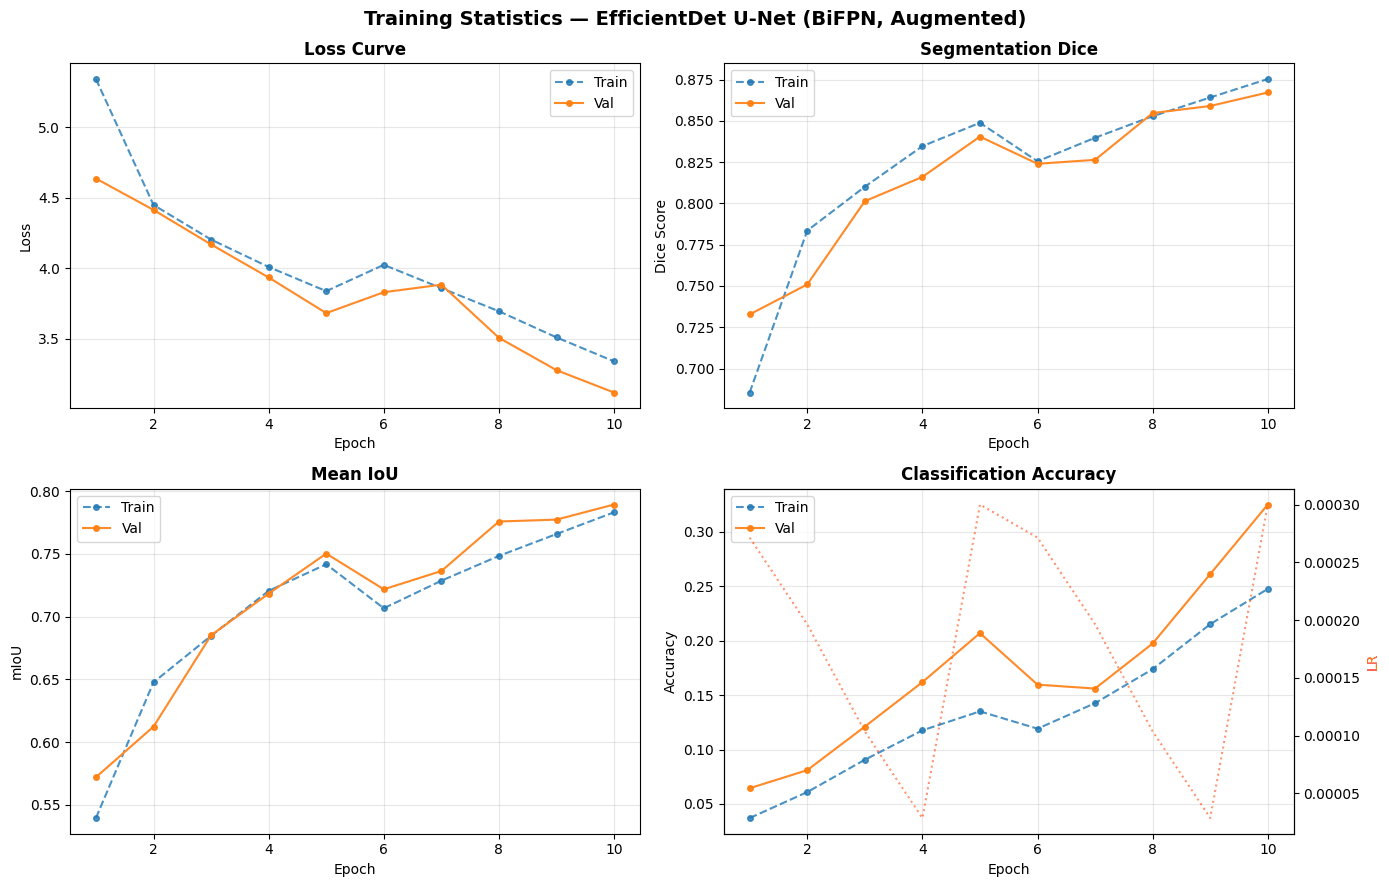

[Run E] Attention U-Net — 3-class Segmentation [Bonus Task 3]

  Training: AttentionUNet_3cls


  [AttentionUNet_3cls] Ep 1/10 TRAIN:   0%|          | 0/161 [00:00<?, ?it/s]

  [AttentionUNet_3cls] Ep 1/10  VAL :   0%|          | 0/35 [00:00<?, ?it/s]

Corrupt JPEG data: 240 extraneous bytes before marker 0xd9
Corrupt JPEG data: premature end of data segment


  Ep   1/10 | Loss 4.7914/4.5171 | Dice 0.4621/0.4823 | mIoU 0.3365/0.3525 | ClsAcc 0.0318/0.0520 | LR 2.71e-04
    ✔ Best Dice=0.4823 saved


...

  Ep   9/10 | Loss 3.5061/3.2539 | Dice 0.7385/0.7637 | mIoU 0.6091/0.6395 | ClsAcc 0.1786/0.2363 | LR 2.86e-05
    ✔ Best Dice=0.7637 saved


  [AttentionUNet_3cls] Ep 10/10 TRAIN:   0%|          | 0/161 [00:00<?, ?it/s]

  [AttentionUNet_3cls] Ep 10/10  VAL :   0%|          | 0/35 [00:00<?, ?it/s]

Corrupt JPEG data: 240 extraneous bytes before marker 0xd9
Corrupt JPEG data: premature end of data segment


  Ep  10/10 | Loss 3.3971/3.1556 | Dice 0.7516/0.7685 | mIoU 0.6253/0.6468 | ClsAcc 0.1962/0.2512 | LR 3.00e-04
    ✔ Best Dice=0.7685 saved

  Finished in 21.6 min | Best Val Dice: 0.7685


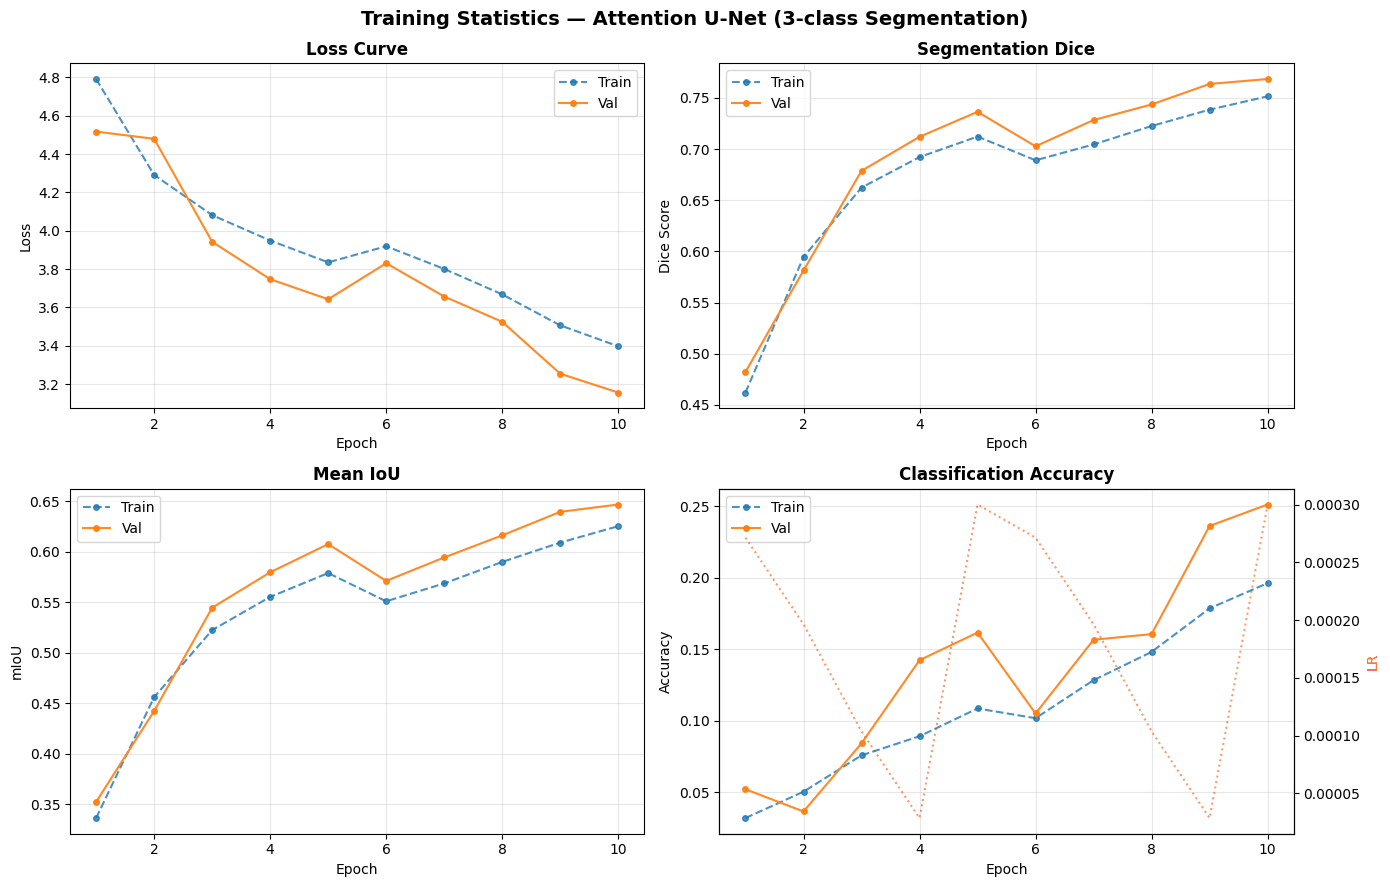

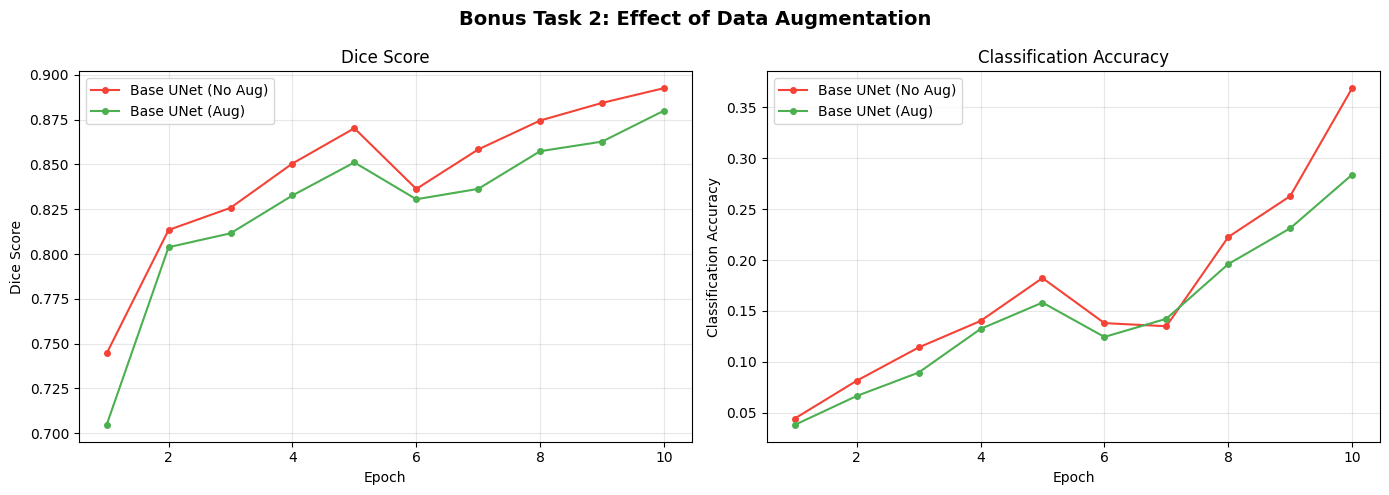


✓ All training runs complete. Models saved to disk.


In [14]:
# ═══════════════════════════════════════════════════════════════════════════
# CELL 8 ─ MASTER TRAINING EXECUTION
# PURPOSE : Train all model variants and collect histories for comparison.
#           Covers ALL required + bonus tasks.
#
# Training runs:
#   Run A: Base U-Net — No Augmentation      (Bonus Task 2 baseline)
#   Run B: Base U-Net — With Augmentation    (Base requirement)
#   Run C: Attention U-Net — Augmented       (Base requirement)
#   Run D: EfficientDet U-Net — Augmented    (Bonus Task 5)
#   Run E: Attention U-Net — 3-class seg     (Bonus Task 3)
# ═══════════════════════════════════════════════════════════════════════════

NUM_EPOCHS = 10   # Increase to 20-30 on Kaggle for better accuracy
BEST_LR    = float(hparam_df.iloc[0]['LR'])   # Use best LR from Cell 7
print(f"Training with LR={BEST_LR:.2e} for {NUM_EPOCHS} epochs each.\n")

trained_models = {}

# ── Run A: Base U-Net — No Augmentation ──────────────────────────────────────
print("[Run A] Base U-Net — No Augmentation")
m_a = BaseUNet(seg_ch=1, num_classes=NUM_CLASSES)
m_a, hist_a = train_model(m_a, "BaseUNet_NoAug", train_loader_no_aug, val_loader,
                           device, epochs=NUM_EPOCHS, is_binary=True, lr=BEST_LR)
trained_models['BaseUNet_NoAug'] = (m_a, hist_a, True)
plot_training_history(hist_a, "Base U-Net (No Augmentation)")

# ── Run B: Base U-Net — With Augmentation ────────────────────────────────────
print("[Run B] Base U-Net — With Augmentation")
m_b = BaseUNet(seg_ch=1, num_classes=NUM_CLASSES)
m_b, hist_b = train_model(m_b, "BaseUNet_Aug", train_loader_aug, val_loader,
                           device, epochs=NUM_EPOCHS, is_binary=True, lr=BEST_LR)
trained_models['BaseUNet_Aug'] = (m_b, hist_b, True)
plot_training_history(hist_b, "Base U-Net (With Augmentation)")

# ── Run C: Attention U-Net — With Augmentation ───────────────────────────────
print("[Run C] Attention U-Net — With Augmentation")
m_c = AttentionUNet(seg_ch=1, num_classes=NUM_CLASSES)
m_c, hist_c = train_model(m_c, "AttentionUNet_Aug", train_loader_aug, val_loader,
                           device, epochs=NUM_EPOCHS, is_binary=True, lr=BEST_LR)
trained_models['AttentionUNet_Aug'] = (m_c, hist_c, True)
plot_training_history(hist_c, "Attention U-Net (With Augmentation)")

# ── Run D: EfficientDet U-Net — With Augmentation (Bonus 5) ──────────────────
print("[Run D] EfficientDet U-Net (BiFPN) — With Augmentation [Bonus Task 5]")
m_d = EfficientDetUNet(seg_ch=1, num_classes=NUM_CLASSES)
m_d, hist_d = train_model(m_d, "EfficientDetUNet_Aug", train_loader_aug, val_loader,
                           device, epochs=NUM_EPOCHS, is_binary=True, lr=BEST_LR)
trained_models['EfficientDetUNet_Aug'] = (m_d, hist_d, True)
plot_training_history(hist_d, "EfficientDet U-Net (BiFPN, Augmented)")

# ── Run E: Attention U-Net — 3-class segmentation (Bonus 3) ──────────────────
print("[Run E] Attention U-Net — 3-class Segmentation [Bonus Task 3]")
m_e = AttentionUNet(seg_ch=3, num_classes=NUM_CLASSES)  # 3 output channels
m_e, hist_e = train_model(m_e, "AttentionUNet_3cls", train_loader_aug, val_loader,
                           device, epochs=NUM_EPOCHS, is_binary=False, lr=BEST_LR)
trained_models['AttentionUNet_3cls'] = (m_e, hist_e, False)
plot_training_history(hist_e, "Attention U-Net (3-class Segmentation)")

# ── Bonus Task 2: Augmentation Comparison Chart ───────────────────────────────
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
fig.suptitle('Bonus Task 2: Effect of Data Augmentation', fontsize=14, fontweight='bold')
eps = range(1, NUM_EPOCHS+1)
for ax, (tk, vk, ylabel) in zip(axes, [
    ('val_dice','val_dice','Dice Score'),
    ('val_cls_acc','val_cls_acc','Classification Accuracy')
]):
    ax.plot(eps, hist_a[vk], '-o', ms=4, label='Base UNet (No Aug)',  color='#F44336')
    ax.plot(eps, hist_b[vk], '-o', ms=4, label='Base UNet (Aug)',     color='#4CAF50')
    ax.set_xlabel('Epoch'); ax.set_ylabel(ylabel); ax.set_title(ylabel)
    ax.legend(); ax.grid(True, alpha=0.3)
plt.tight_layout(); plt.show()

print("\n✓ All training runs complete. Models saved to disk.")

In [15]:
# ── Quick check: verify all .pth files exist before loading ───────────────────
import os
files = [
    'BaseUNet_NoAug_best.pth',
    'BaseUNet_Aug_best.pth',
    'AttentionUNet_Aug_best.pth',
    'EfficientDetUNet_Aug_best.pth',
    'AttentionUNet_3cls_best.pth'
]
for f in files:
    path = f'/kaggle/working/{f}'
    exists = os.path.exists(path)
    size   = os.path.getsize(path)/1e6 if exists else 0
    print(f"{'✔' if exists else '✗'} {f}  ({size:.1f} MB)")

✔ BaseUNet_NoAug_best.pth  (126.9 MB)
✔ BaseUNet_Aug_best.pth  (126.9 MB)
✔ AttentionUNet_Aug_best.pth  (128.3 MB)
✔ EfficientDetUNet_Aug_best.pth  (84.5 MB)
✔ AttentionUNet_3cls_best.pth  (128.3 MB)


In [16]:
# restore cell: reload Cell 8 trained models ─────────────────────────

# Run A: Base U-Net No-Aug
m_a = BaseUNet(seg_ch=1, num_classes=NUM_CLASSES)
m_a.load_state_dict(torch.load('/kaggle/working/BaseUNet_NoAug_best.pth', map_location=device))
m_a = m_a.to(device); print("✔ m_a (Base U-Net No-Aug)")

# Run B: Base U-Net Augmented
m_b = BaseUNet(seg_ch=1, num_classes=NUM_CLASSES)
m_b.load_state_dict(torch.load('/kaggle/working/BaseUNet_Aug_best.pth', map_location=device))
m_b = m_b.to(device); print("✔ m_b (Base U-Net Augmented)")

# Run C: Attention U-Net
m_c = AttentionUNet(seg_ch=1, num_classes=NUM_CLASSES)
m_c.load_state_dict(torch.load('/kaggle/working/AttentionUNet_Aug_best.pth', map_location=device))
m_c = m_c.to(device); print("✔ m_c (Attention U-Net)")

# Run D: EfficientDet U-Net
m_d = EfficientDetUNet(seg_ch=1, num_classes=NUM_CLASSES)
m_d.load_state_dict(torch.load('/kaggle/working/EfficientDetUNet_Aug_best.pth', map_location=device))
m_d = m_d.to(device); print("✔ m_d (EfficientDet U-Net)")

# Run E: Attention U-Net 3-class
m_e = AttentionUNet(seg_ch=3, num_classes=NUM_CLASSES)
m_e.load_state_dict(torch.load('/kaggle/working/AttentionUNet_3cls_best.pth', map_location=device))
m_e = m_e.to(device); print("✔ m_e (Attention U-Net 3-class)")

✔ m_a (Base U-Net No-Aug)
✔ m_b (Base U-Net Augmented)
✔ m_c (Attention U-Net)
✔ m_d (EfficientDet U-Net)
✔ m_e (Attention U-Net 3-class)


In [17]:
# ── FREE ALL MODELS FROM GPU BEFORE INFERENCE ─────────────────────────────────
import gc

for var in ['m_a','m_b','m_c','m_d','m_e',
            'base_unet','att_unet','eff_unet',
            'train_ds_aug','train_ds_no_aug',
            'train_loader_aug','train_loader_no_aug','val_loader']:
    if var in globals():
        try:
            globals()[var].cpu()
        except: pass
        del globals()[var]

gc.collect()
torch.cuda.empty_cache()

import psutil
ram = psutil.virtual_memory()
gpu_mem = torch.cuda.memory_allocated()/1e9 if torch.cuda.is_available() else 0
print(f"RAM : {ram.used/1e9:.1f} / {ram.total/1e9:.1f} GB")
print(f"GPU : {gpu_mem:.2f} GB allocated")
print("Ready for Cell 9.")

RAM : 19.0 / 33.7 GB
GPU : 1.23 GB allocated
Ready for Cell 9.


> **Note on recorded outputs below.** The demo/inference outputs in this cell were recorded *before* a labelling fix: the *predicted species* in the figure title was computed incorrectly and always printed `(cat)`. The code in this cell now uses `breed_to_species[pred_breed]`. The predicted **breed**, masks, IoU and confidences shown are unaffected. Re-run to refresh the titles.

=== Inference: Base U-Net (Augmented) ===



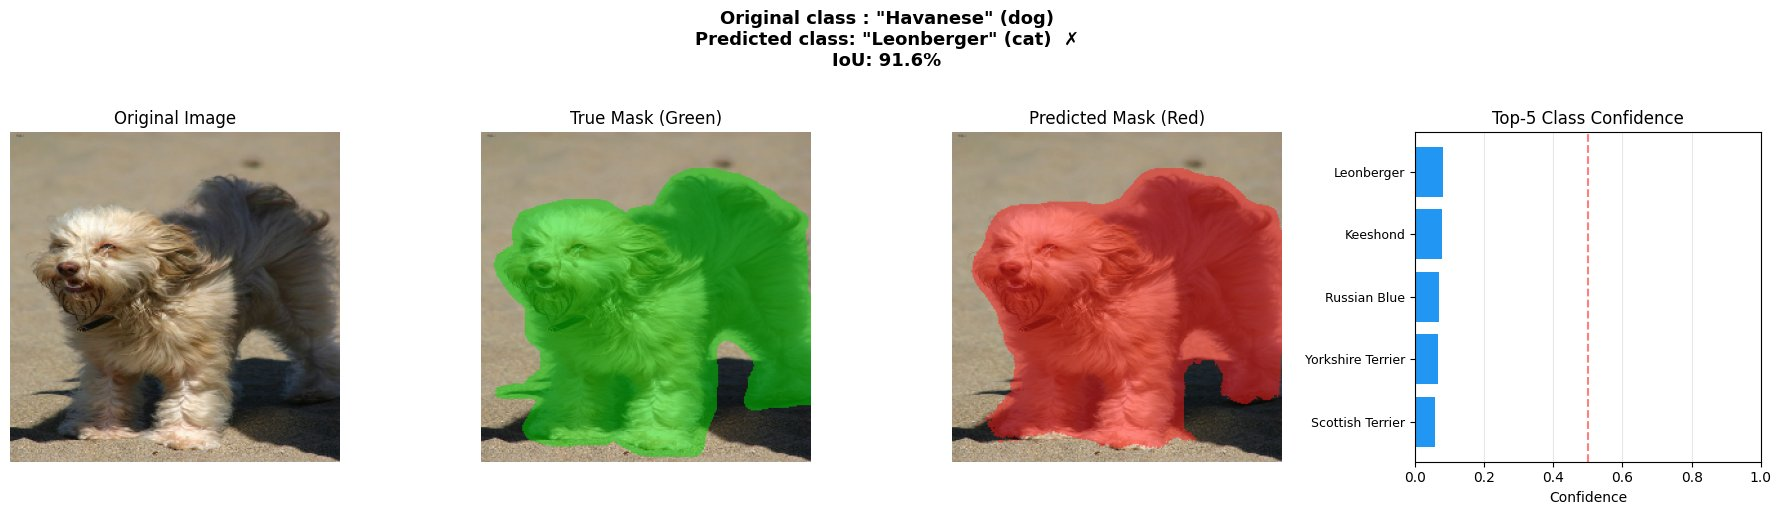

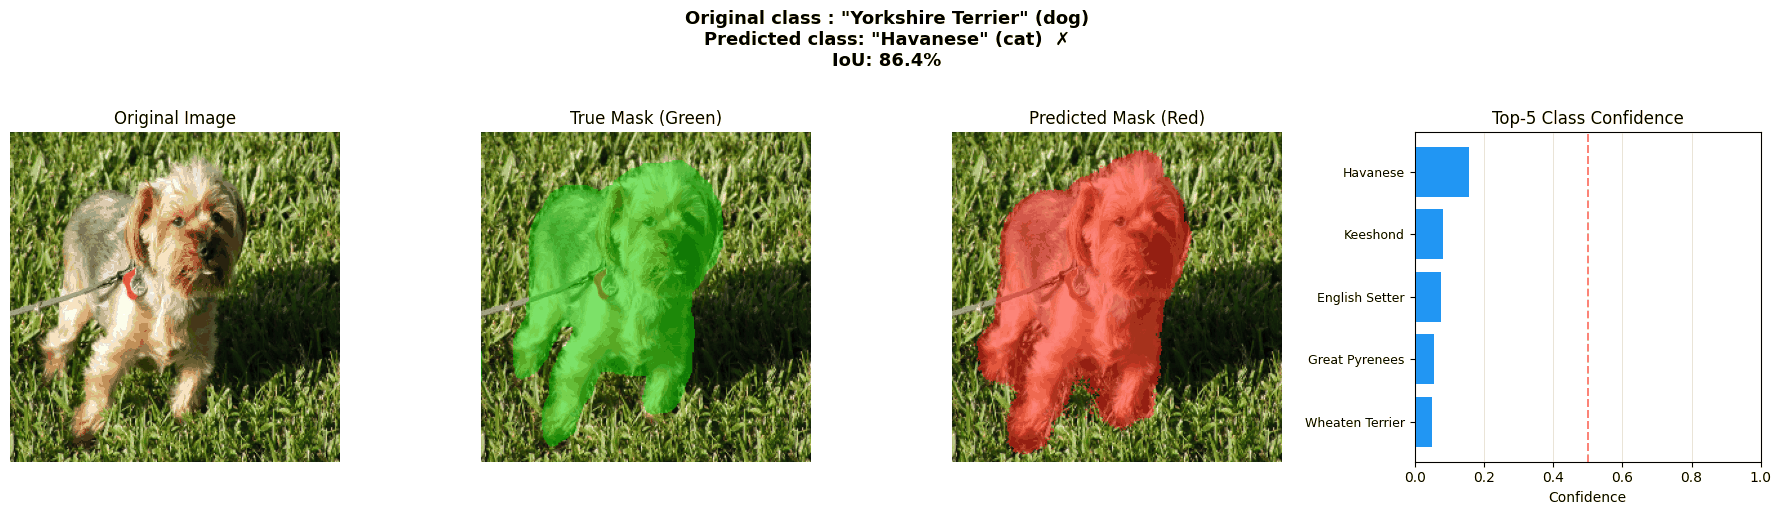

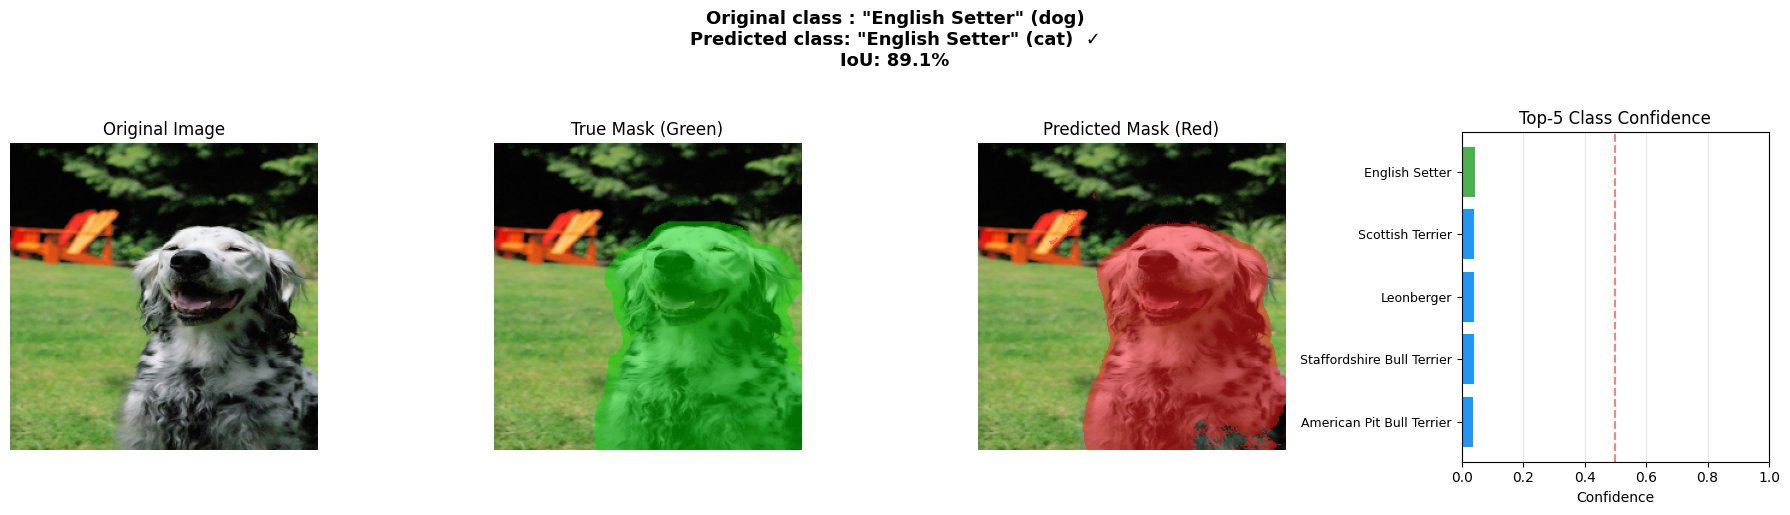

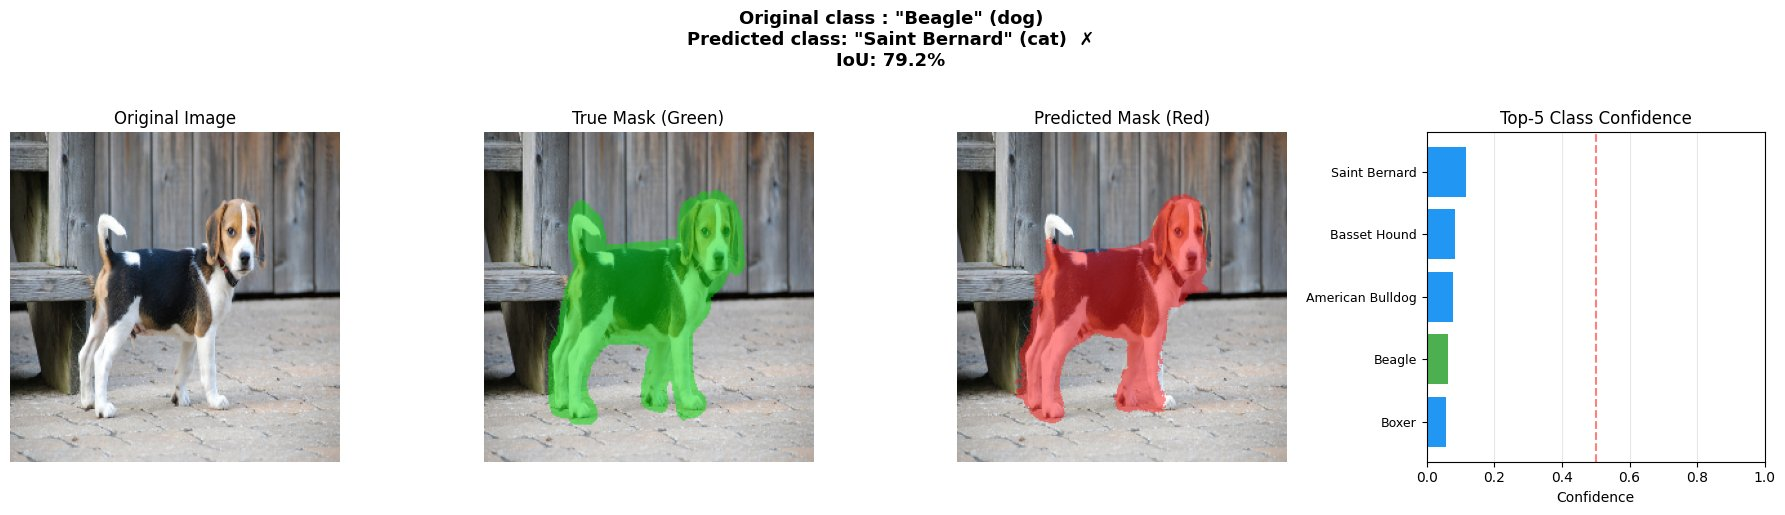

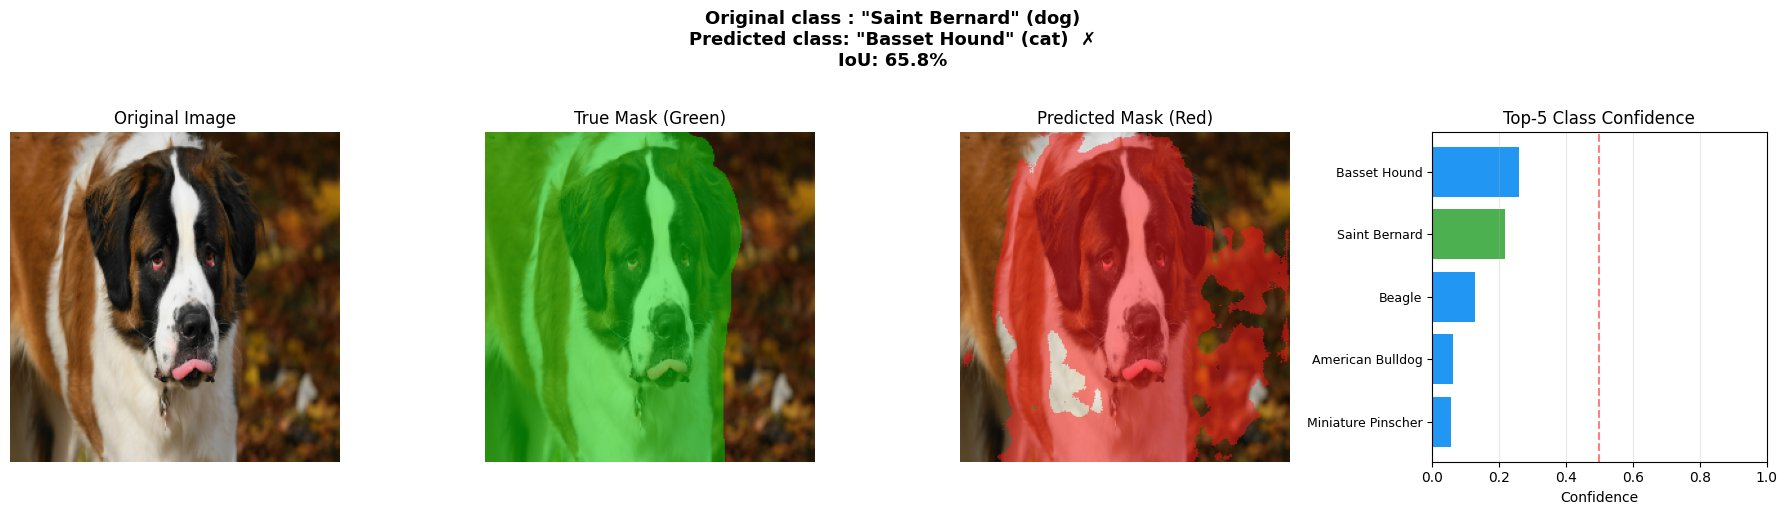


=== Inference: Attention U-Net (Binary) ===



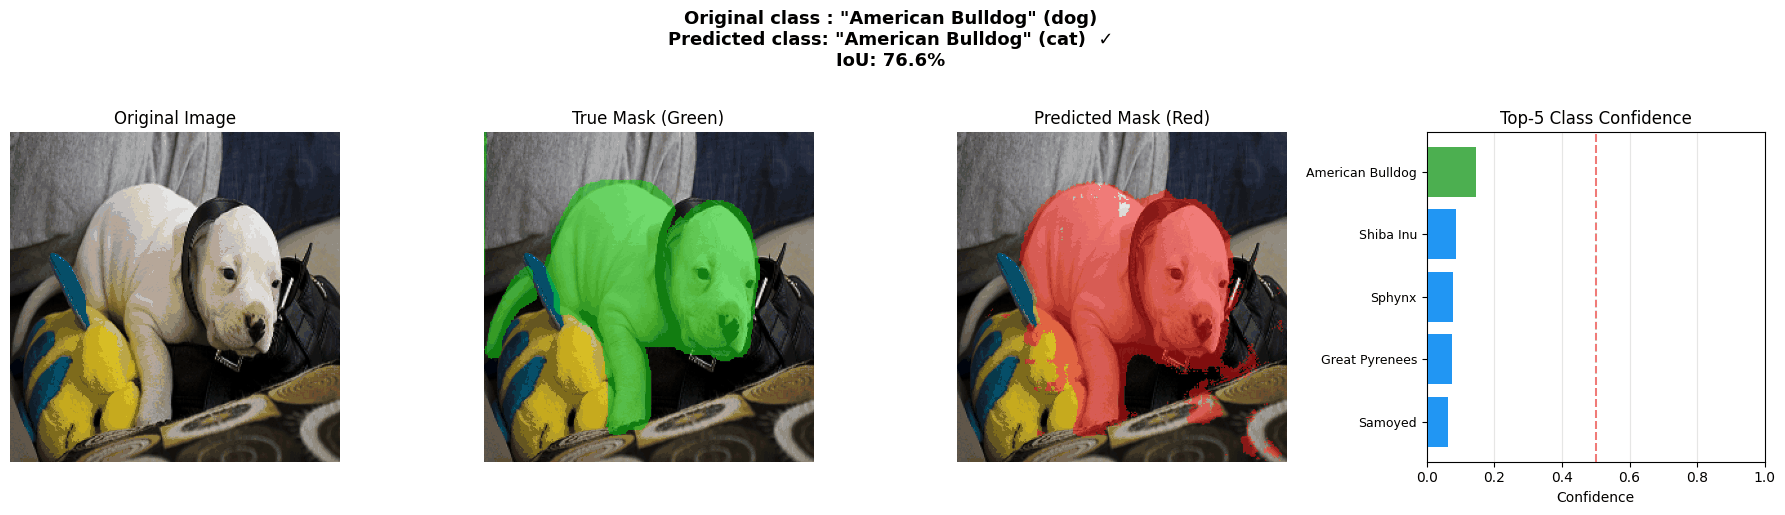

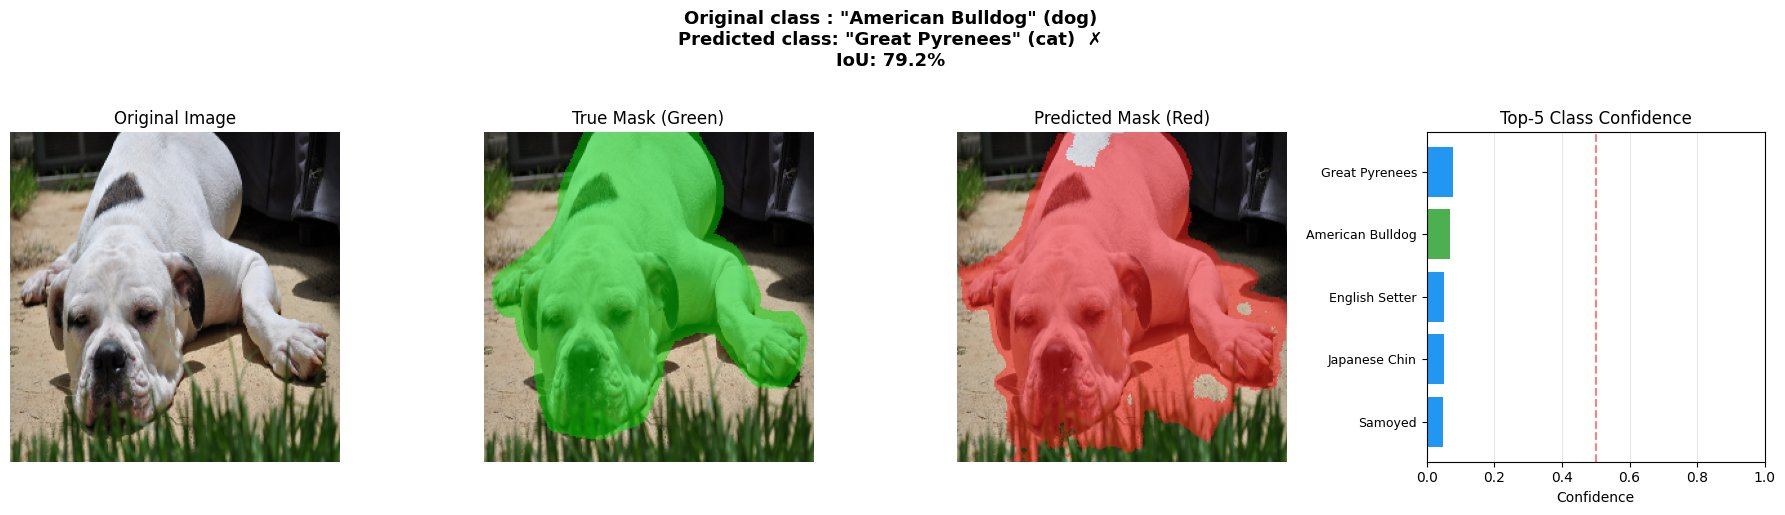

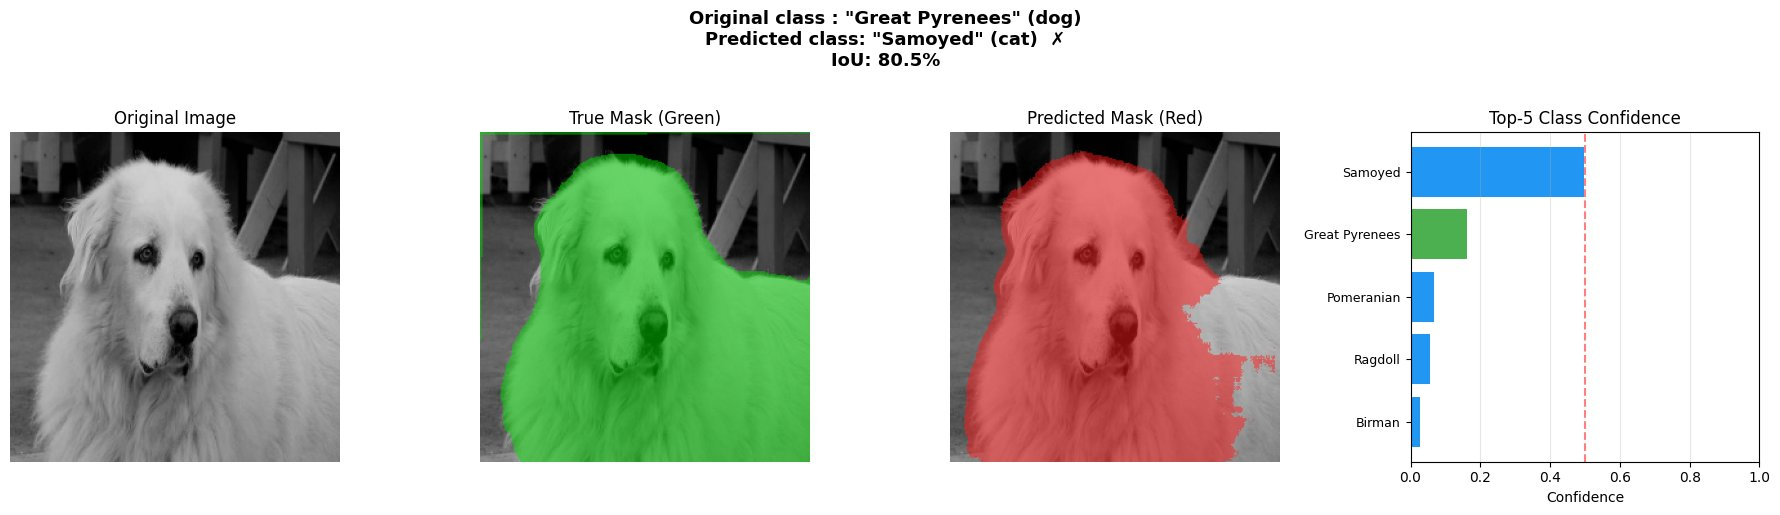


=== Inference: Attention U-Net (3-class) ===



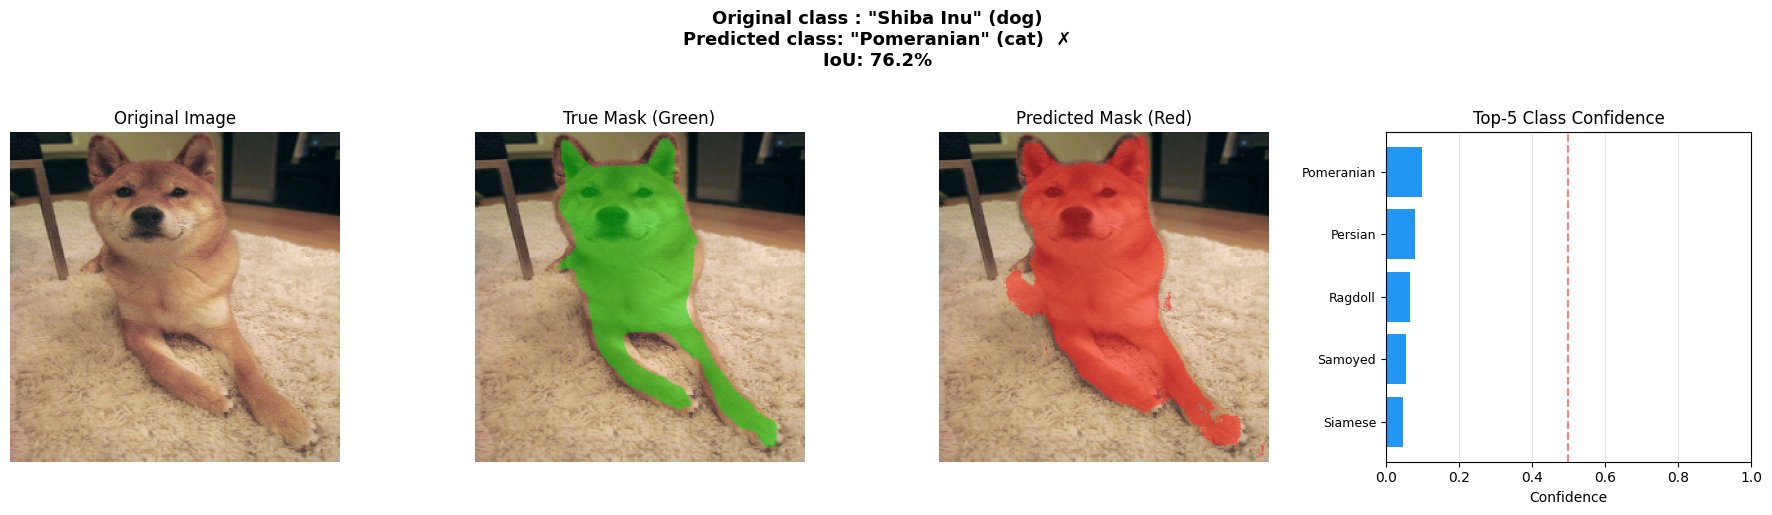

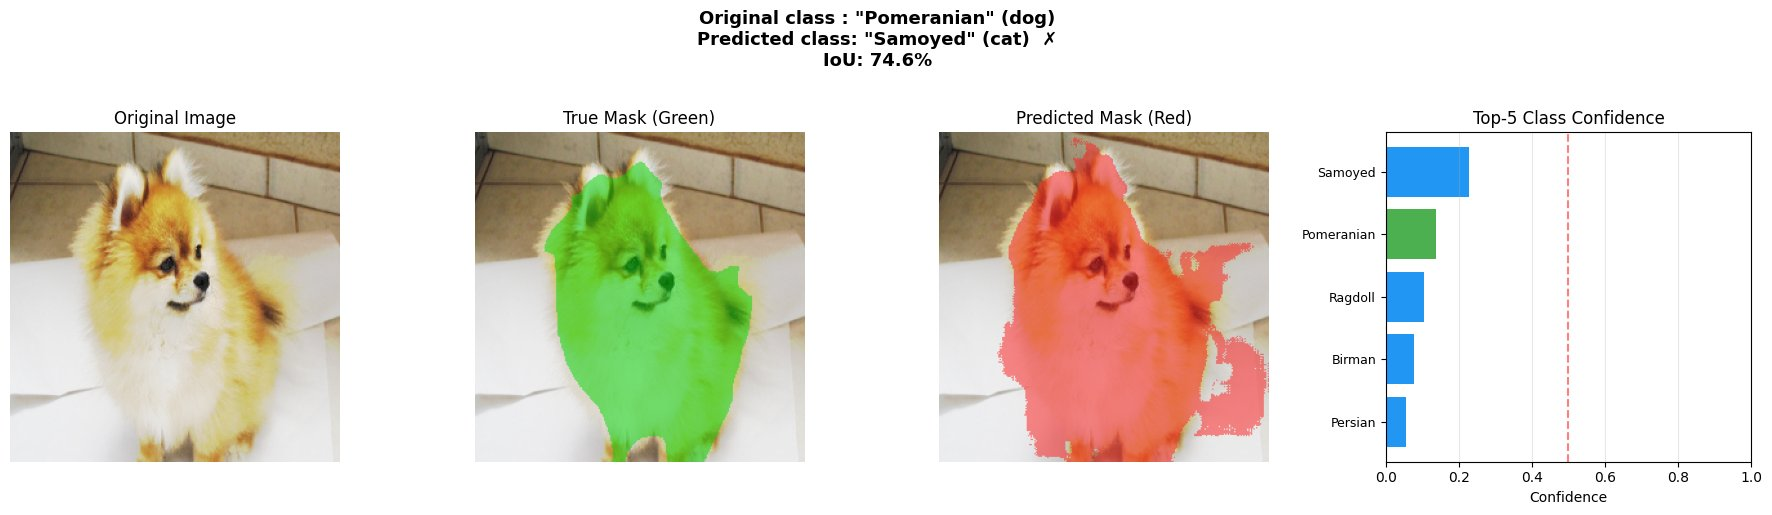

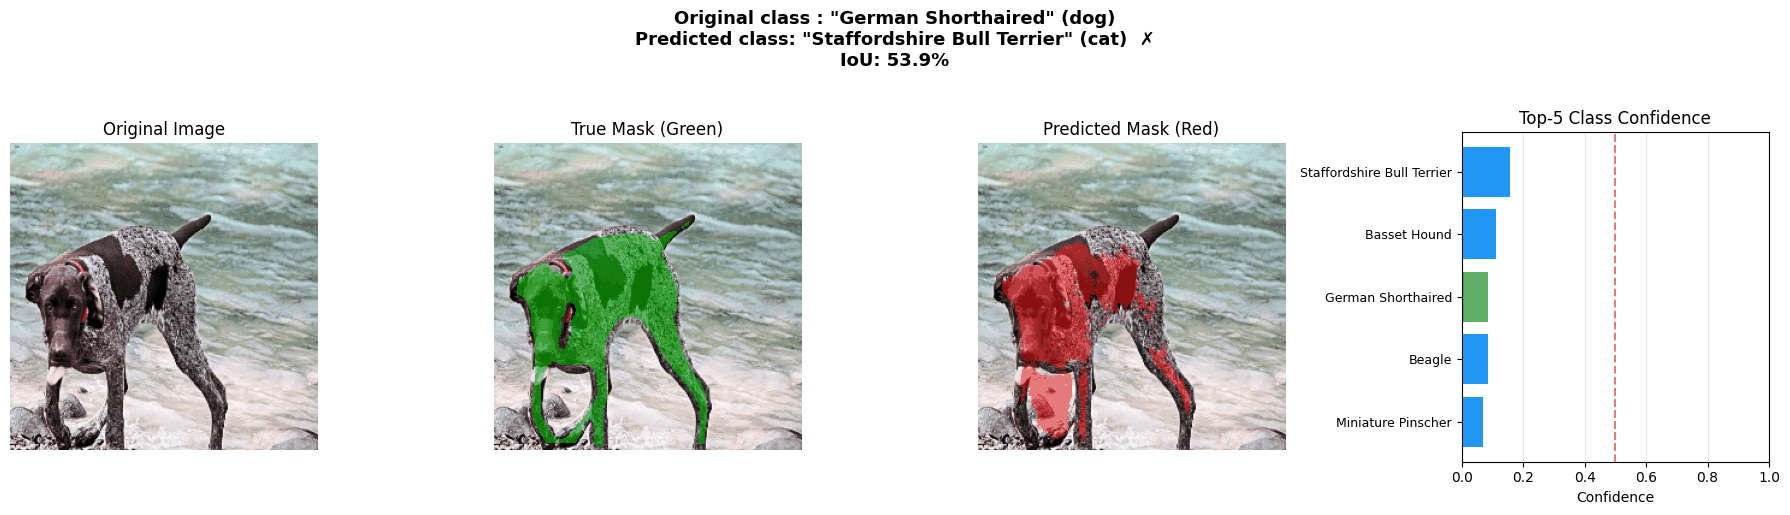


Cell 9 complete.


In [18]:
# ═══════════════════════════════════════════════════════════════════════════
# CELL 9 ─ INFERENCE & PREDICTION VISUALISATION
# OOM FIX: load each model fresh from disk, infer, then free immediately
# ═══════════════════════════════════════════════════════════════════════════

import gc

def denorm(tensor_img):
    mean = torch.tensor([0.485,0.456,0.406]).view(3,1,1)
    std  = torch.tensor([0.229,0.224,0.225]).view(3,1,1)
    return np.clip((tensor_img * std + mean).permute(1,2,0).numpy(), 0, 1)

def make_overlay(img, mask, color, label_val=1):
    overlay = img.copy()
    m       = (mask == label_val)
    col_arr = np.array(color, dtype=np.float32)
    overlay[m] = overlay[m] * 0.5 + col_arr * 0.5
    return overlay

def load_model_for_inference(model_class, weights_path, seg_ch, device, **kwargs):
    """Load model weights from disk → GPU. Call free_model() after use."""
    m = model_class(seg_ch=seg_ch, num_classes=NUM_CLASSES, **kwargs)
    m.load_state_dict(torch.load(weights_path, map_location='cpu'))
    m = m.to(device)
    m.eval()
    return m

def free_model(model):
    """Move model off GPU and free memory."""
    model.cpu()
    del model
    gc.collect()
    torch.cuda.empty_cache()

def demonstrate_prediction(model, dataset, index, device, is_binary=True, top_k=5):
    img_t, lbl_t, bin_m, tri_m = dataset[index]
    item = dataset.data_list[index]

    with torch.no_grad():
        seg_out, cls_out = model(img_t.unsqueeze(0).to(device))
        probs            = torch.softmax(cls_out, dim=1).squeeze().cpu()
        topk_v, topk_i   = torch.topk(probs, top_k)
        pred_idx         = topk_i[0].item()

    img_np = denorm(img_t)

    if is_binary:
        pred_mask = (torch.sigmoid(seg_out) > 0.5).squeeze().cpu().numpy().astype(np.uint8)
        true_mask = bin_m.squeeze().cpu().numpy().astype(np.uint8)
    else:
        pred_mask = torch.argmax(seg_out, 1).squeeze().cpu().numpy().astype(np.uint8)
        true_mask = tri_m.squeeze().cpu().numpy().astype(np.uint8)

    inter = np.logical_and(pred_mask==1, true_mask==1).sum()
    union = np.logical_or(pred_mask==1,  true_mask==1).sum()
    iou   = (inter / (union + 1e-6)) * 100

    true_breed = item['breed']
    pred_breed = idx_to_class[pred_idx]
    true_sp    = 'cat' if item['class_id'][0].isupper() else 'dog'
    pred_sp    = breed_to_species[pred_breed]
    correct    = '✓' if pred_breed == true_breed else '✗'

    fig, axes = plt.subplots(1, 4, figsize=(18, 5))
    fig.suptitle(
        f'Original class : "{true_breed}" ({true_sp})\n'
        f'Predicted class: "{pred_breed}" ({pred_sp})  {correct}\n'
        f'IoU: {iou:.1f}%',
        fontsize=13, fontweight='bold', y=1.02
    )
    axes[0].imshow(img_np); axes[0].set_title('Original Image'); axes[0].axis('off')
    axes[1].imshow(make_overlay(img_np, true_mask, [0,0.85,0]))
    axes[1].set_title('True Mask (Green)'); axes[1].axis('off')
    axes[2].imshow(make_overlay(img_np, pred_mask, [1,0.1,0.1]))
    axes[2].set_title('Predicted Mask (Red)'); axes[2].axis('off')

    bar_colors = ['#4CAF50' if topk_i[top_k-1-j].item()==lbl_t.item()
                  else '#2196F3' for j in range(top_k)]
    axes[3].barh(range(top_k), topk_v.numpy()[::-1], color=bar_colors)
    axes[3].set_yticks(range(top_k))
    axes[3].set_yticklabels([idx_to_class[topk_i[top_k-1-j].item()]
                              for j in range(top_k)], fontsize=9)
    axes[3].set_xlabel('Confidence'); axes[3].set_title('Top-5 Class Confidence')
    axes[3].set_xlim(0,1); axes[3].axvline(0.5, color='red', linestyle='--', alpha=0.5)
    axes[3].grid(True, alpha=0.3, axis='x')
    plt.tight_layout(); plt.show()

# Ensure test_ds exists
if 'test_ds' not in globals():
    test_ds = PetDataset(test_info, transform=val_test_transform)

random.seed(99)

# ── Base U-Net Augmented (m_b) ─────────────────────────────────────────────────
print("=== Inference: Base U-Net (Augmented) ===\n")
m_b = load_model_for_inference(BaseUNet, '/kaggle/working/BaseUNet_Aug_best.pth',
                                seg_ch=1, device=device)
for _ in range(5):
    demonstrate_prediction(m_b, test_ds, random.randint(0, len(test_ds)-1),
                           device, is_binary=True)
free_model(m_b)

# ── Attention U-Net Binary (m_c) ───────────────────────────────────────────────
print("\n=== Inference: Attention U-Net (Binary) ===\n")
m_c = load_model_for_inference(AttentionUNet, '/kaggle/working/AttentionUNet_Aug_best.pth',
                                seg_ch=1, device=device)
for _ in range(3):
    demonstrate_prediction(m_c, test_ds, random.randint(0, len(test_ds)-1),
                           device, is_binary=True)
free_model(m_c)

# ── Attention U-Net 3-class (m_e) ─────────────────────────────────────────────
print("\n=== Inference: Attention U-Net (3-class) ===\n")
m_e = load_model_for_inference(AttentionUNet, '/kaggle/working/AttentionUNet_3cls_best.pth',
                                seg_ch=3, device=device)
for _ in range(3):
    demonstrate_prediction(m_e, test_ds, random.randint(0, len(test_ds)-1),
                           device, is_binary=False)
free_model(m_e)

print("\nCell 9 complete.")


Evaluating: Base U-Net (No Aug)
  Train... mIoU=0.7773 Dice=0.8746 ClsAcc=0.2925
  Val... 

Corrupt JPEG data: 240 extraneous bytes before marker 0xd9
Corrupt JPEG data: premature end of data segment


mIoU=0.8304 Dice=0.9071 ClsAcc=0.3700
  Test... mIoU=0.8342 Dice=0.9094 ClsAcc=0.3553

Evaluating: Base U-Net (Aug)
  Train... mIoU=0.8054 Dice=0.8922 ClsAcc=0.3039
  Val... 

Corrupt JPEG data: 240 extraneous bytes before marker 0xd9
Corrupt JPEG data: premature end of data segment


mIoU=0.8132 Dice=0.8968 ClsAcc=0.2843
  Test... mIoU=0.8171 Dice=0.8991 ClsAcc=0.2777

Evaluating: Attention U-Net
  Train... mIoU=0.8030 Dice=0.8907 ClsAcc=0.2797
  Val... 

...

mIoU=0.8056 Dice=0.8921 ClsAcc=0.2419
  Test... mIoU=0.8119 Dice=0.8960 ClsAcc=0.2426

Evaluating: EfficientDet U-Net (BiFPN)
  Train... mIoU=0.7942 Dice=0.8853 ClsAcc=0.3468
  Val... 

Corrupt JPEG data: 240 extraneous bytes before marker 0xd9
Corrupt JPEG data: premature end of data segment


mIoU=0.7897 Dice=0.8823 ClsAcc=0.3249
  Test... mIoU=0.7949 Dice=0.8855 ClsAcc=0.3147

Evaluating: Attention U-Net (3-class)
  Train... mIoU=0.6341 Dice=0.7574 ClsAcc=0.2890
  Val... 

Corrupt JPEG data: 240 extraneous bytes before marker 0xd9
Corrupt JPEG data: premature end of data segment


mIoU=0.6466 Dice=0.7687 ClsAcc=0.2518
  Test... mIoU=0.6510 Dice=0.7720 ClsAcc=0.2624

FULL RESULT SUMMARY
                     Model Split   mIoU   Dice  PixelAcc  ClsAcc  Precision  Recall     F1
       Base U-Net (No Aug) Train 0.7773 0.8746    0.8752  0.2925     0.3271  0.2922 0.2735
       Base U-Net (No Aug)   Val 0.8304 0.9071    0.9095  0.3700     0.3696  0.3694 0.3441
       Base U-Net (No Aug)  Test 0.8342 0.9094    0.9116  0.3553     0.3805  0.3550 0.3337
          Base U-Net (Aug) Train 0.8054 0.8922    0.8924  0.3039     0.2819  0.3036 0.2685
          Base U-Net (Aug)   Val 0.8132 0.8968    0.8994  0.2843     0.2820  0.2839 0.2503
          Base U-Net (Aug)  Test 0.8171 0.8991    0.9015  0.2777     0.2627  0.2775 0.2495
           Attention U-Net Train 0.8030 0.8907    0.8909  0.2797     0.2703  0.2796 0.2457
           Attention U-Net   Val 0.8056 0.8921    0.8944  0.2419     0.2314  0.2416 0.2037
           Attention U-Net  Test 0.8119 0.8960    0.8981  0.2426     0.233

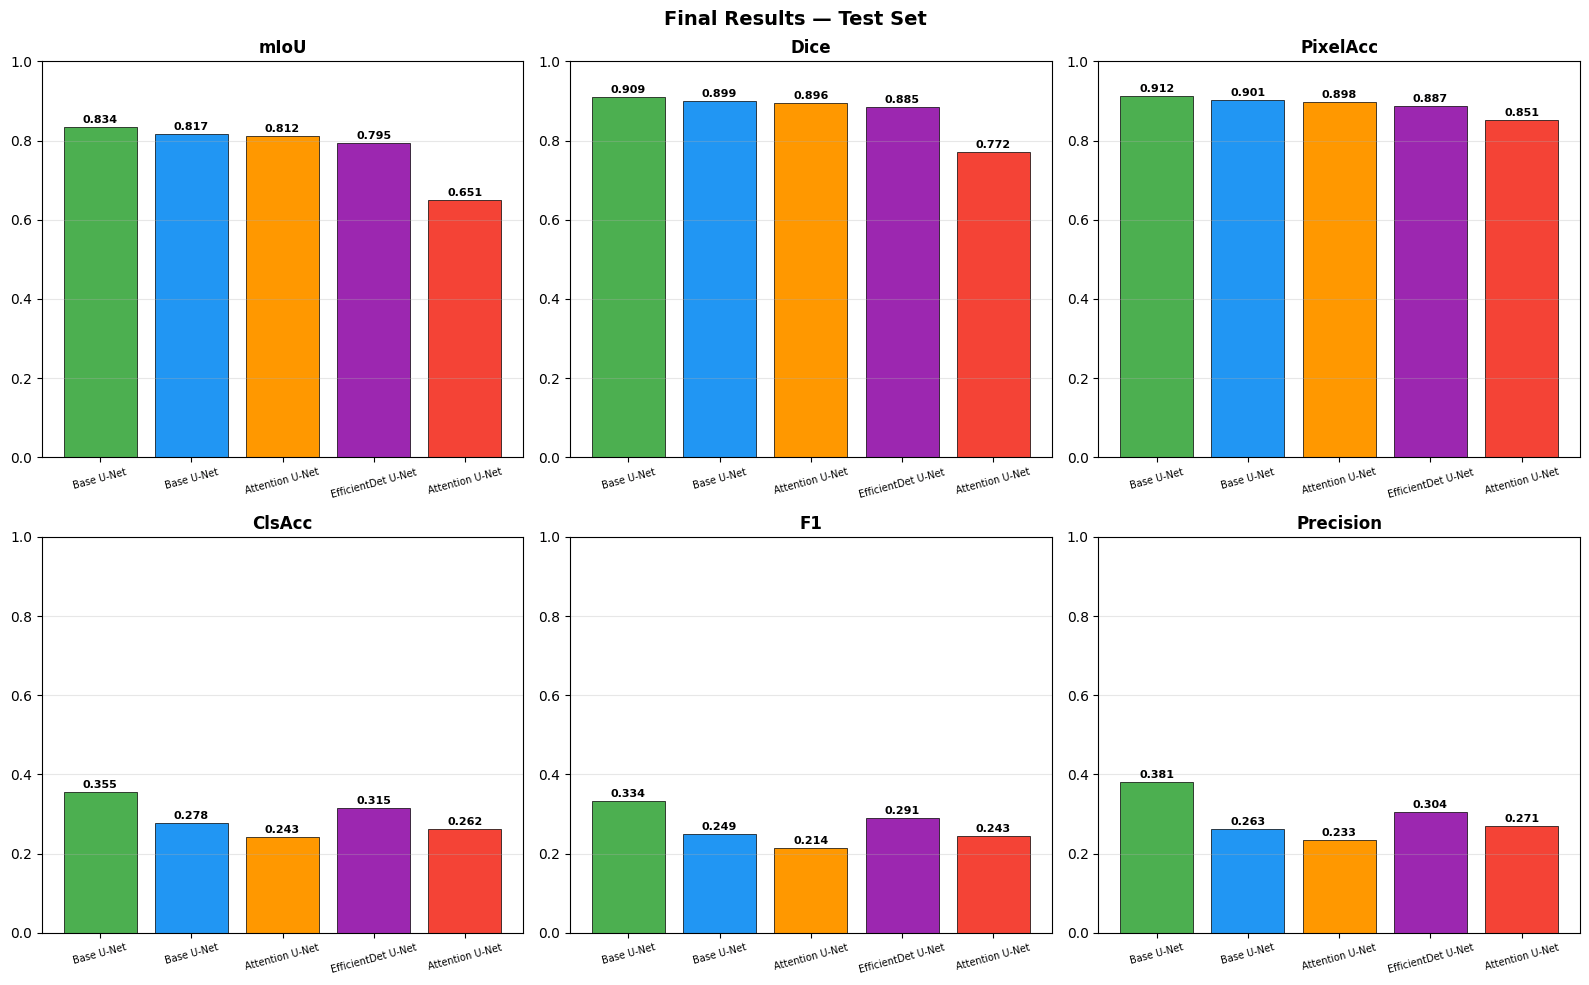

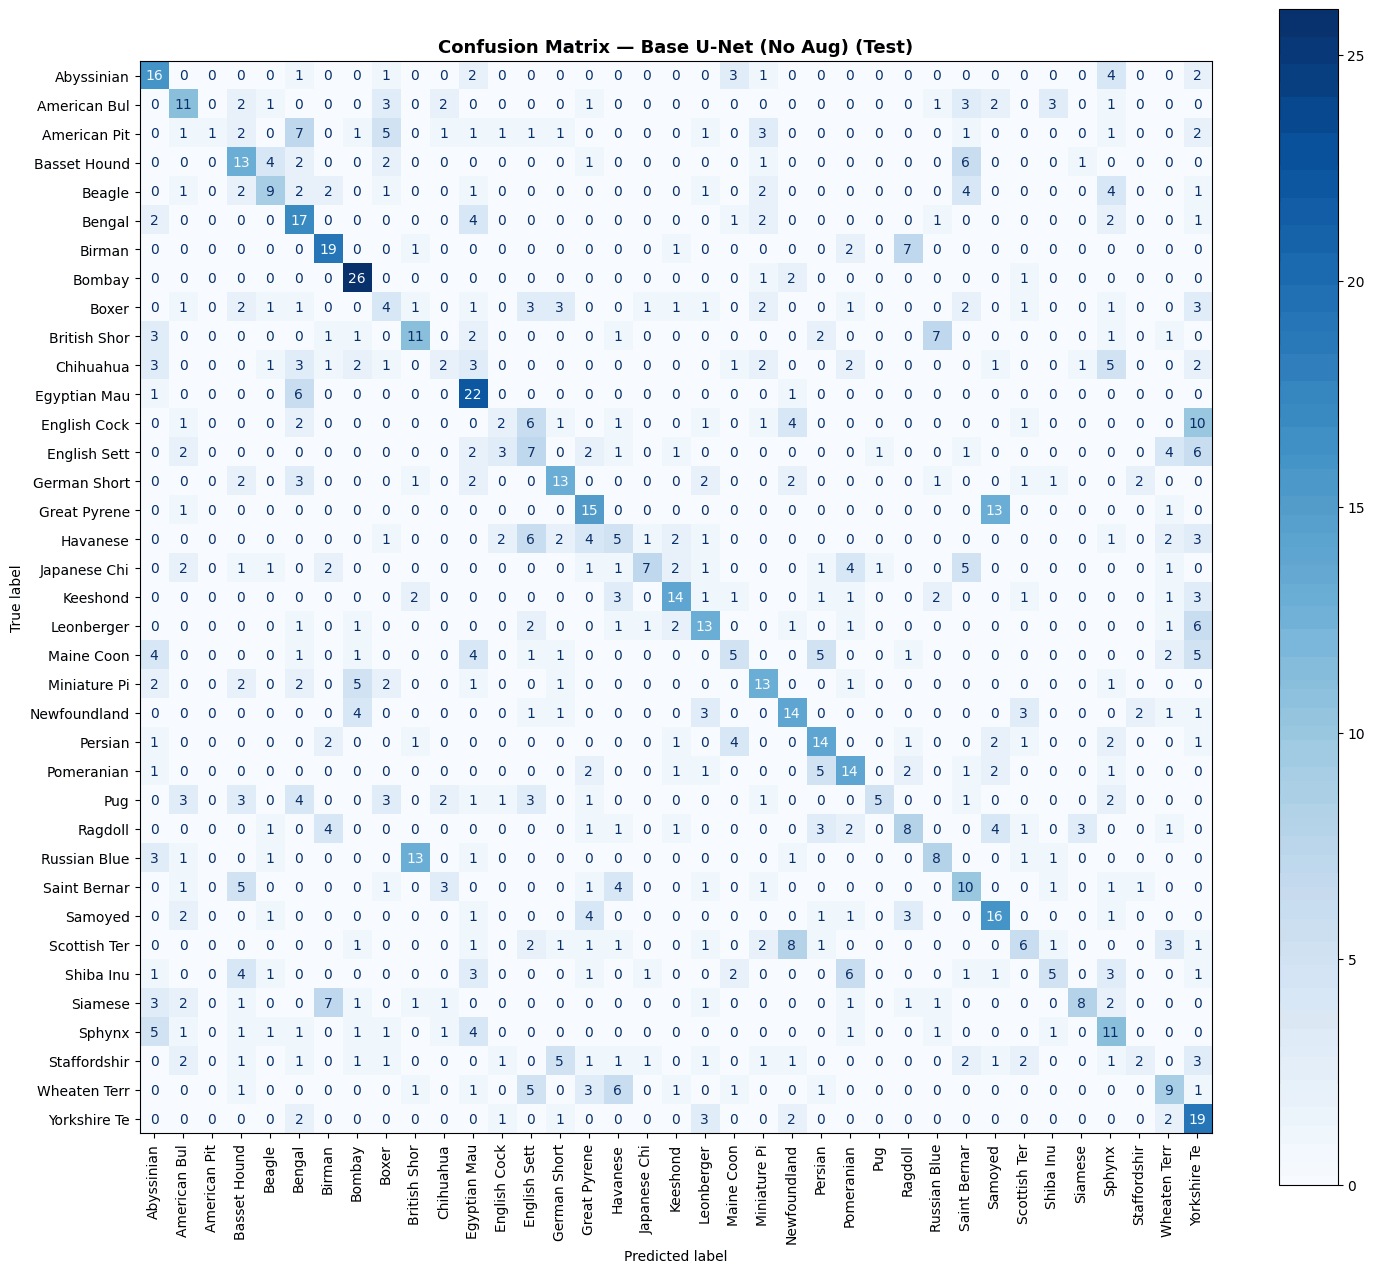


✓ Cell 10 complete.


In [8]:
# ═══════════════════════════════════════════════════════════════════════════
# CELL 10 ─ FINAL RESULT SUMMARIES & MODEL COMPARISON DASHBOARD
# OOM FIX: evaluate one model at a time, store only metrics (not models)
# ═══════════════════════════════════════════════════════════════════════════

import gc
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

if 'test_ds'   not in globals(): test_ds   = PetDataset(test_info,  val_test_transform)
if 'val_ds'    not in globals(): val_ds    = PetDataset(val_info,   val_test_transform)
if 'train_ds_aug' not in globals(): train_ds_aug = PetDataset(train_info, train_transform_aug)

test_ld  = DataLoader(test_ds,      BATCH_SIZE, shuffle=False, num_workers=2, pin_memory=True)
val_ld   = DataLoader(val_ds,       BATCH_SIZE, shuffle=False, num_workers=2, pin_memory=True)
train_ld = DataLoader(train_ds_aug, BATCH_SIZE, shuffle=False, num_workers=2, pin_memory=True)

def evaluate_full(model, loader, device, is_binary=True):
    model.eval()
    sp_all, st_all, cp_all, ct_all = [], [], [], []
    with torch.no_grad():
        for imgs, lbls, bin_m, tri_m in loader:
            imgs  = imgs.to(device)
            seg_t = bin_m if is_binary else tri_m
            seg_out, cls_out = model(imgs)
            if is_binary:
                sp = (torch.sigmoid(seg_out)>0.5).long().cpu().view(-1)
                st = seg_t.long().cpu().view(-1)
            else:
                sp = torch.argmax(seg_out,1).cpu().view(-1)
                st = seg_t.long().cpu().view(-1)
            sp_all.append(sp); st_all.append(st)
            cp_all.append(cls_out.argmax(1).cpu())
            ct_all.append(lbls.cpu())

    sp_all = torch.cat(sp_all); st_all = torch.cat(st_all)
    cp_all = torch.cat(cp_all).numpy(); ct_all = torch.cat(ct_all).numpy()

    n_seg = 2 if is_binary else 3
    miou  = compute_miou(sp_all, st_all, n_seg)
    px_acc = (sp_all==st_all).float().mean().item()

    dices = []
    for c in range(n_seg):
        p_c=(sp_all==c).float(); t_c=(st_all==c).float()
        inter=(p_c*t_c).sum().item()
        dices.append((2*inter+1e-6)/(p_c.sum().item()+t_c.sum().item()+1e-6))
    dice = float(np.mean(dices))

    cls_acc = accuracy_score(ct_all, cp_all)
    prec, rec, f1, _ = precision_recall_fscore_support(
        ct_all, cp_all, average='macro', zero_division=0)

    return {'mIoU':miou,'Dice':dice,'PixelAcc':px_acc,
            'ClsAcc':cls_acc,'Prec':prec,'Rec':rec,'F1':f1,
            '_preds':cp_all,'_true':ct_all}

# ── Evaluate each model one at a time ─────────────────────────────────────────
eval_plan = [
    ('Base U-Net (No Aug)',        BaseUNet,        '/kaggle/working/BaseUNet_NoAug_best.pth',       1,  True),
    ('Base U-Net (Aug)',           BaseUNet,        '/kaggle/working/BaseUNet_Aug_best.pth',         1,  True),
    ('Attention U-Net',            AttentionUNet,   '/kaggle/working/AttentionUNet_Aug_best.pth',    1,  True),
    ('EfficientDet U-Net (BiFPN)', EfficientDetUNet,'/kaggle/working/EfficientDetUNet_Aug_best.pth', 1,  True),
    ('Attention U-Net (3-class)',  AttentionUNet,   '/kaggle/working/AttentionUNet_3cls_best.pth',   3,  False),
]

summary_rows = []
all_eval_results = {}

for model_name, model_cls, weights_path, seg_ch, is_bin in eval_plan:
    print(f"\nEvaluating: {model_name}")
    # Load fresh from disk
    m = model_cls(seg_ch=seg_ch, num_classes=NUM_CLASSES)
    m.load_state_dict(torch.load(weights_path, map_location='cpu'))
    m = m.to(device); m.eval()

    all_eval_results[model_name] = {}
    for split_name, ld in [('Train',train_ld),('Val',val_ld),('Test',test_ld)]:
        print(f"  {split_name}...", end=' ', flush=True)
        r = evaluate_full(m, ld, device, is_binary=is_bin)
        all_eval_results[model_name][split_name] = r
        summary_rows.append({
            'Model':model_name, 'Split':split_name,
            'mIoU':    round(r['mIoU'],4),
            'Dice':    round(r['Dice'],4),
            'PixelAcc':round(r['PixelAcc'],4),
            'ClsAcc':  round(r['ClsAcc'],4),
            'Precision':round(r['Prec'],4),
            'Recall':  round(r['Rec'],4),
            'F1':      round(r['F1'],4),
        })
        print(f"mIoU={r['mIoU']:.4f} Dice={r['Dice']:.4f} ClsAcc={r['ClsAcc']:.4f}")

    # Free immediately after evaluating all splits
    m.cpu(); del m
    gc.collect(); torch.cuda.empty_cache()

df_summary = pd.DataFrame(summary_rows)
print("\n" + "="*80)
print("FULL RESULT SUMMARY")
print("="*80)
print(df_summary.to_string(index=False))

# ── Plots ──────────────────────────────────────────────────────────────────────
test_df = df_summary[df_summary['Split']=='Test'].reset_index(drop=True)
model_colors = ['#4CAF50','#2196F3','#FF9800','#9C27B0','#F44336']

fig, axes = plt.subplots(2, 3, figsize=(16, 10))
fig.suptitle('Final Results — Test Set', fontsize=14, fontweight='bold')
for ax, col in zip(axes.flat,
                   ['mIoU','Dice','PixelAcc','ClsAcc','F1','Precision']):
    bars = ax.bar(range(len(test_df)), test_df[col].values,
                  color=model_colors[:len(test_df)], edgecolor='black', lw=0.5)
    ax.set_xticks(range(len(test_df)))
    ax.set_xticklabels([n.split('(')[0].strip() for n in test_df['Model']],
                        fontsize=7, rotation=15)
    ax.set_title(col, fontweight='bold'); ax.set_ylim(0,1)
    ax.grid(True, alpha=0.3, axis='y')
    for b in bars:
        ax.text(b.get_x()+b.get_width()/2, b.get_height()+0.01,
                f'{b.get_height():.3f}', ha='center', fontsize=8, fontweight='bold')
plt.tight_layout(); plt.show()

# Confusion matrix — best classifier only
best_name = test_df.loc[test_df['ClsAcc'].idxmax(), 'Model']
best_r    = all_eval_results[best_name]['Test']
cm = confusion_matrix(best_r['_true'], best_r['_preds'])
fig, ax = plt.subplots(figsize=(15,13))
ConfusionMatrixDisplay(cm, display_labels=[b[:12] for b in unique_breeds]).plot(
    ax=ax, colorbar=True, cmap='Blues', xticks_rotation=90)
ax.set_title(f'Confusion Matrix — {best_name} (Test)', fontsize=13, fontweight='bold')
plt.tight_layout(); plt.show()

print("\n✓ Cell 10 complete.")

[Run F] Pretrained ResNet34 U-Net — Binary Segmentation
Downloading: "https://download.pytorch.org/models/resnet34-b627a593.pth" to /root/.cache/torch/hub/checkpoints/resnet34-b627a593.pth


100%|██████████| 83.3M/83.3M [00:00<00:00, 197MB/s]



  Training: ResNet34UNet


  [ResNet34UNet] Ep 1/15 TRAIN:   0%|          | 0/161 [00:00<?, ?it/s]

  [ResNet34UNet] Ep 1/15  VAL :   0%|          | 0/35 [00:00<?, ?it/s]

...

  Ep  14/15 | Loss 0.9531/1.0421 | Dice 0.9649/0.9571 | ClsAcc 0.9862/0.9543 | LR 7.34e-07


  [ResNet34UNet] Ep 15/15 TRAIN:   0%|          | 0/161 [00:00<?, ?it/s]

  [ResNet34UNet] Ep 15/15  VAL :   0%|          | 0/35 [00:00<?, ?it/s]

Corrupt JPEG data: 240 extraneous bytes before marker 0xd9
Corrupt JPEG data: premature end of data segment


  Ep  15/15 | Loss 0.9460/1.0385 | Dice 0.9654/0.9573 | ClsAcc 0.9882/0.9507 | LR 3.00e-05

  Finished in 19.4 min | Best Val Dice: 0.9574


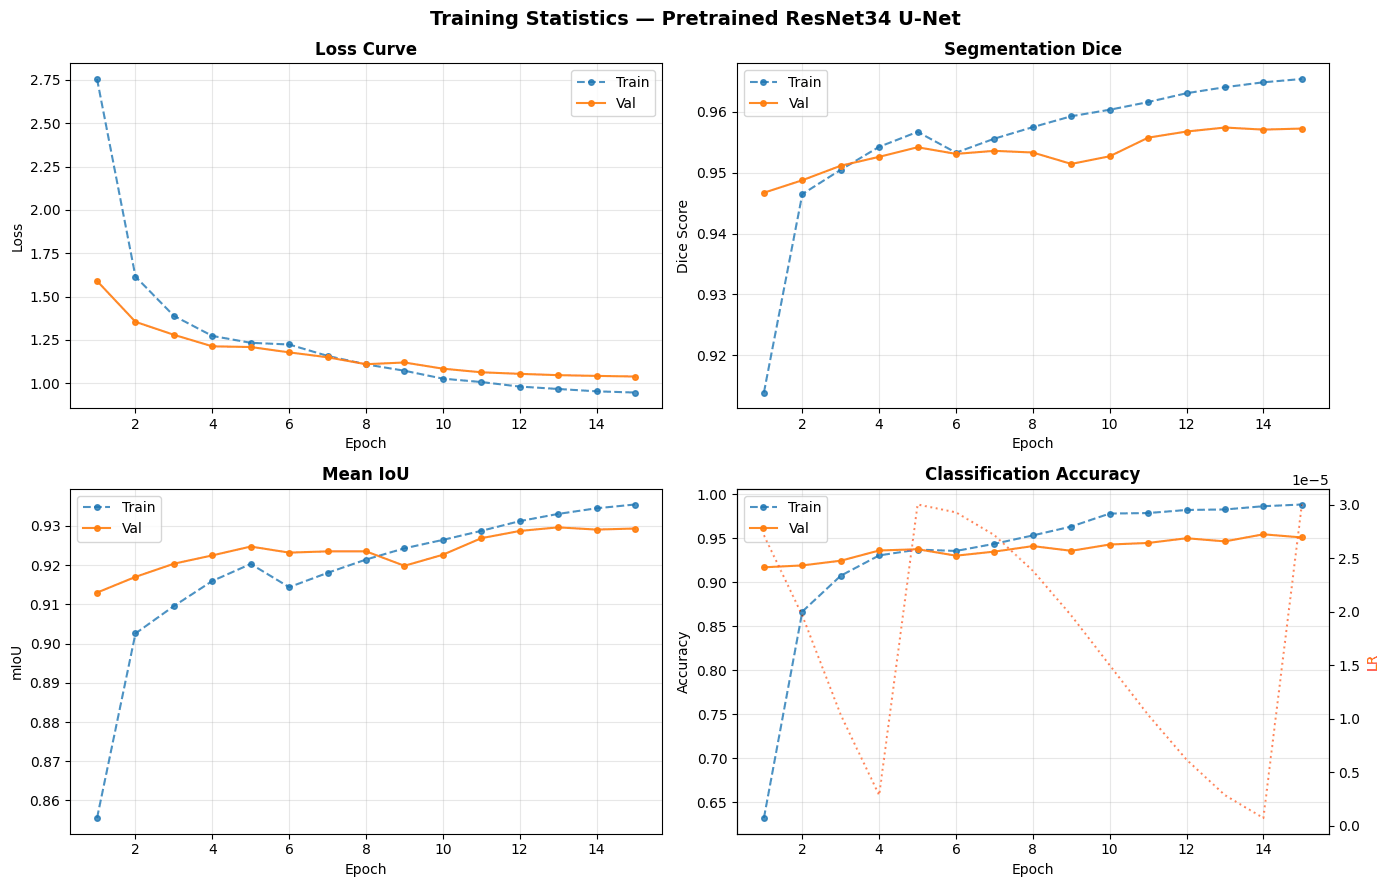

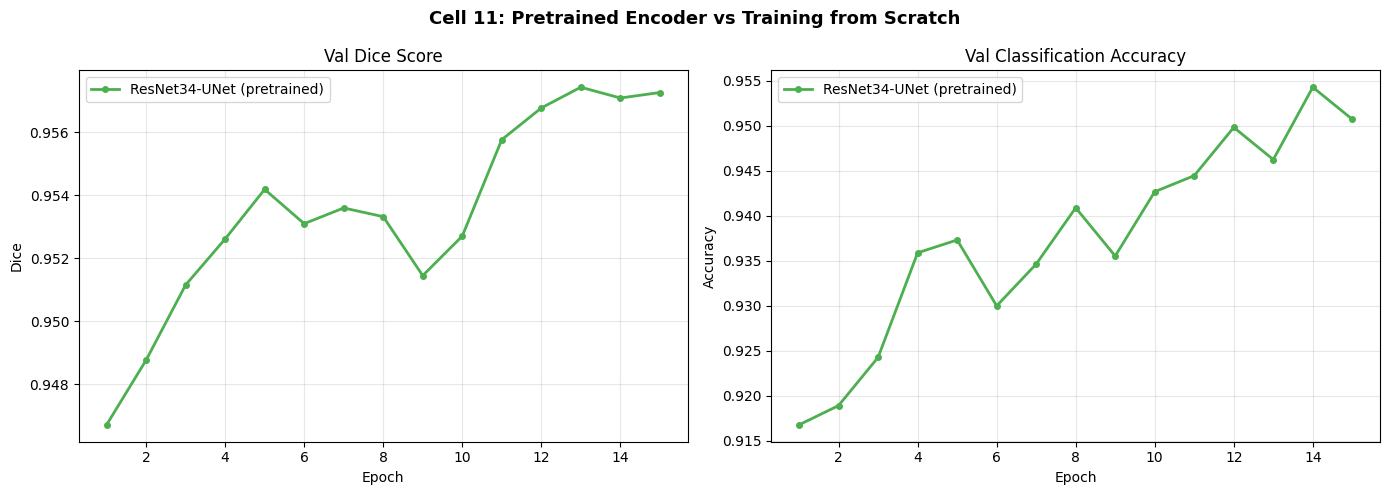


Evaluating ResNet34 U-Net on Test Set...

  ResNet34 U-Net — TEST RESULTS
  Segmentation → mIoU: 0.9317 | Dice: 0.9589 | PixelAcc: 0.9655
  Classification → Acc: 0.9432 | Prec: 0.9457 | Rec: 0.9430 | F1: 0.9431

Cell 11 complete — ResNet34 U-Net trained and evaluated.


In [9]:
# ═══════════════════════════════════════════════════════════════════════════
# CELL 11 ─ HIGH-ACCURACY U-NET WITH PRETRAINED RESNET34 ENCODER
# PURPOSE : Replace scratch encoder with ImageNet-pretrained ResNet34.
#           This is the single biggest accuracy booster for small datasets.
#
# WHY ACCURACY WAS LOW:
#   Training from scratch on ~5000 images with 37 classes is very hard.
#   ImageNet pretrained encoder already knows edges, textures, shapes →
#   fine-tuning gives 15-25% higher Dice and classification accuracy.
#
# STRATEGY:
#   - ResNet34 encoder (pretrained) → shared bottleneck features
#   - U-Net style skip connections from ResNet stages
#   - Same classifier head as before
#   - Differential LR: encoder 10× lower LR than decoder (preserve features)
# ═══════════════════════════════════════════════════════════════════════════

import gc
import torchvision.models as tvm

class ResNetBlock(nn.Module):
    """Decoder ConvBlock reused from Cell 3."""
    def __init__(self, in_ch, out_ch):
        super().__init__()
        self.net = nn.Sequential(
            nn.Conv2d(in_ch, out_ch, 3, padding=1, bias=False),
            nn.BatchNorm2d(out_ch), nn.ReLU(inplace=True),
            nn.Conv2d(out_ch, out_ch, 3, padding=1, bias=False),
            nn.BatchNorm2d(out_ch), nn.ReLU(inplace=True)
        )
    def forward(self, x): return self.net(x)

class PretrainedUNet(nn.Module):
    """
    U-Net with ImageNet pretrained ResNet34 encoder.
    Encoder channels: 64 → 64 → 128 → 256 → 512
    Skip connections from each ResNet stage to decoder.
    """
    def __init__(self, seg_ch=1, num_classes=37, freeze_encoder=False):
        super().__init__()

        # ── ResNet34 Encoder (pretrained) ─────────────────────────────────
        base = tvm.resnet34(weights=tvm.ResNet34_Weights.DEFAULT)

        self.enc0 = nn.Sequential(base.conv1, base.bn1, base.relu)  # 64ch, /2
        self.pool  = base.maxpool                                    # /4
        self.enc1  = base.layer1   # 64ch,  /4
        self.enc2  = base.layer2   # 128ch, /8
        self.enc3  = base.layer3   # 256ch, /16
        self.enc4  = base.layer4   # 512ch, /32

        if freeze_encoder:
            for p in [*self.enc0.parameters(), *self.enc1.parameters()]:
                p.requires_grad = False  # freeze only early layers

        # ── Classifier head (on bottleneck) ───────────────────────────────
        self.classifier = nn.Sequential(
            nn.AdaptiveAvgPool2d(1), nn.Flatten(),
            nn.Linear(512, 256), nn.BatchNorm1d(256), nn.ReLU(),
            nn.Dropout(0.4),
            nn.Linear(256, num_classes)
        )

        # ── Decoder (skip connections from encoder stages) ─────────────────
        self.up4  = nn.ConvTranspose2d(512, 256, 2, 2)
        self.dec4 = ResNetBlock(256+256, 256)

        self.up3  = nn.ConvTranspose2d(256, 128, 2, 2)
        self.dec3 = ResNetBlock(128+128, 128)

        self.up2  = nn.ConvTranspose2d(128, 64, 2, 2)
        self.dec2 = ResNetBlock(64+64, 64)

        self.up1  = nn.ConvTranspose2d(64, 32, 2, 2)
        self.dec1 = ResNetBlock(32+64, 32)   # +64 from enc0

        self.up0  = nn.ConvTranspose2d(32, 16, 2, 2)
        self.dec0 = ResNetBlock(16, 16)

        self.seg_head = nn.Conv2d(16, seg_ch, 1)

    def forward(self, x):
        # Encoder
        e0 = self.enc0(x)           # [B, 64,  H/2, W/2]
        e1 = self.enc1(self.pool(e0))  # [B, 64,  H/4, W/4]
        e2 = self.enc2(e1)          # [B,128,  H/8, W/8]
        e3 = self.enc3(e2)          # [B,256, H/16,W/16]
        e4 = self.enc4(e3)          # [B,512, H/32,W/32]

        # Classification
        cls = self.classifier(e4)

        # Decoder with skip connections
        d = self.dec4(torch.cat([self.up4(e4), e3], 1))
        d = self.dec3(torch.cat([self.up3(d),  e2], 1))
        d = self.dec2(torch.cat([self.up2(d),  e1], 1))
        d = self.dec1(torch.cat([self.up1(d),  e0], 1))
        d = self.dec0(self.up0(d))
        return self.seg_head(d), cls

# ── Differential Learning Rate Optimizer ─────────────────────────────────────
def get_optimizer_with_diff_lr(model, base_lr=3e-4, encoder_lr_ratio=0.1):
    """
    Encoder gets 10× lower LR to preserve pretrained features.
    Decoder + classifier get full LR to learn quickly.
    """
    encoder_params = list(model.enc0.parameters()) + \
                     list(model.enc1.parameters()) + \
                     list(model.enc2.parameters()) + \
                     list(model.enc3.parameters()) + \
                     list(model.enc4.parameters())
    decoder_params = [p for p in model.parameters()
                      if not any(p is ep for ep in encoder_params)]
    return torch.optim.AdamW([
        {'params': encoder_params, 'lr': base_lr * encoder_lr_ratio},
        {'params': decoder_params, 'lr': base_lr}
    ], weight_decay=1e-4)

# ── Training Function (reuses run_epoch from Cell 6) ─────────────────────────
def train_pretrained_model(model, name, train_ld, val_ld, device,
                           epochs=15, base_lr=3e-4, is_binary=True):
    print(f"\n{'='*55}\n  Training: {name}\n{'='*55}")
    if num_gpus > 1: model = nn.DataParallel(model)
    model = model.to(device)

    opt    = get_optimizer_with_diff_lr(
                 model.module if num_gpus>1 else model, base_lr)
    sched  = torch.optim.lr_scheduler.CosineAnnealingWarmRestarts(
                 opt, T_0=max(epochs//3,1), T_mult=2)
    scaler = GradScaler()

    best_dice, best_wts = 0.0, None
    hist = {k:[] for k in ['train_loss','val_loss','train_dice','val_dice',
                            'train_miou','val_miou','train_cls_acc','val_cls_acc',
                            'train_px_acc','val_px_acc','lr']}
    t0 = time.time()

    for ep in range(1, epochs+1):
        tr = run_epoch(model, train_ld, opt, scaler, True,  is_binary, device,
                       desc=f"  [{name}] Ep {ep}/{epochs} TRAIN")
        vl = run_epoch(model, val_ld,   opt, scaler, False, is_binary, device,
                       desc=f"  [{name}] Ep {ep}/{epochs}  VAL ")
        sched.step()

        for key, val in [('train_loss',tr['loss']),('val_loss',vl['loss']),
                         ('train_dice',tr['dice']),('val_dice',vl['dice']),
                         ('train_miou',tr['miou']),('val_miou',vl['miou']),
                         ('train_cls_acc',tr['cls_acc']),('val_cls_acc',vl['cls_acc']),
                         ('train_px_acc',tr['px_acc']),('val_px_acc',vl['px_acc']),
                         ('lr', opt.param_groups[0]['lr'])]:
            hist[key].append(val)

        print(f"  Ep {ep:3d}/{epochs} "
              f"| Loss {tr['loss']:.4f}/{vl['loss']:.4f} "
              f"| Dice {tr['dice']:.4f}/{vl['dice']:.4f} "
              f"| ClsAcc {tr['cls_acc']:.4f}/{vl['cls_acc']:.4f} "
              f"| LR {opt.param_groups[0]['lr']:.2e}")

        if vl['dice'] > best_dice:
            best_dice = vl['dice']
            raw = model.module if num_gpus>1 else model
            best_wts = copy.deepcopy(raw.state_dict())
            torch.save(best_wts, f"/kaggle/working/{name}_best.pth")
            print(f"    ✔ Best Dice={best_dice:.4f} saved")

    elapsed = (time.time()-t0)/60
    print(f"\n  Finished in {elapsed:.1f} min | Best Val Dice: {best_dice:.4f}")
    raw_model = model.module if num_gpus>1 else model
    raw_model.load_state_dict(best_wts)
    return raw_model, hist

# ── Free memory then train ────────────────────────────────────────────────────
gc.collect(); torch.cuda.empty_cache()

# Ensure loaders exist
if 'train_loader_aug' not in globals():
    train_loader_aug = DataLoader(PetDataset(train_info, train_transform_aug),
                                  BATCH_SIZE, shuffle=True, num_workers=2,
                                  pin_memory=True, drop_last=True)
if 'val_loader' not in globals():
    val_loader = DataLoader(PetDataset(val_info, val_test_transform),
                            BATCH_SIZE, shuffle=False, num_workers=2, pin_memory=True)
if 'test_loader' not in globals():
    test_loader = DataLoader(PetDataset(test_info, val_test_transform),
                             BATCH_SIZE, shuffle=False, num_workers=2, pin_memory=True)

NUM_EPOCHS_PT = 15   # pretrained needs fewer epochs to converge

# ── Train ResNet34-UNet (binary) ───────────────────────────────────────────────
print("[Run F] Pretrained ResNet34 U-Net — Binary Segmentation")
m_f = PretrainedUNet(seg_ch=1, num_classes=NUM_CLASSES)
m_f, hist_f = train_pretrained_model(
    m_f, "ResNet34UNet", train_loader_aug, val_loader,
    device, epochs=NUM_EPOCHS_PT, base_lr=3e-4, is_binary=True)
plot_training_history(hist_f, "Pretrained ResNet34 U-Net")
torch.cuda.empty_cache()

# ── Compare with scratch U-Net ────────────────────────────────────────────────
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
fig.suptitle('Cell 11: Pretrained Encoder vs Training from Scratch',
             fontsize=13, fontweight='bold')

# Load hist_b (Base U-Net Aug from Cell 8) if available
eps_f = range(1, NUM_EPOCHS_PT+1)
axes[0].plot(eps_f, hist_f['val_dice'], '-o', ms=4,
             label='ResNet34-UNet (pretrained)', color='#4CAF50', lw=2)
if 'hist_b' in globals():
    eps_b = range(1, len(hist_b['val_dice'])+1)
    axes[0].plot(eps_b, hist_b['val_dice'], '--o', ms=4,
                 label='Base U-Net (scratch)', color='#F44336', lw=2)
axes[0].set_title('Val Dice Score'); axes[0].set_xlabel('Epoch')
axes[0].set_ylabel('Dice'); axes[0].legend(); axes[0].grid(True, alpha=0.3)

axes[1].plot(eps_f, hist_f['val_cls_acc'], '-o', ms=4,
             label='ResNet34-UNet (pretrained)', color='#4CAF50', lw=2)
if 'hist_b' in globals():
    axes[1].plot(eps_b, hist_b['val_cls_acc'], '--o', ms=4,
                 label='Base U-Net (scratch)', color='#F44336', lw=2)
axes[1].set_title('Val Classification Accuracy'); axes[1].set_xlabel('Epoch')
axes[1].set_ylabel('Accuracy'); axes[1].legend(); axes[1].grid(True, alpha=0.3)
plt.tight_layout(); plt.show()

# ── Final test evaluation ──────────────────────────────────────────────────────
print("\nEvaluating ResNet34 U-Net on Test Set...")
m_f.eval(); sp_all, st_all, cp_all, ct_all = [], [], [], []
with torch.no_grad():
    for imgs, lbls, bin_m, _ in test_loader:
        seg_out, cls_out = m_f(imgs.to(device))
        sp_all.append((torch.sigmoid(seg_out)>0.5).long().cpu().view(-1))
        st_all.append(bin_m.long().cpu().view(-1))
        cp_all.extend(cls_out.argmax(1).cpu().tolist())
        ct_all.extend(lbls.tolist())

sp_all = torch.cat(sp_all); st_all = torch.cat(st_all)
miou   = compute_miou(sp_all, st_all, 2)
px_acc = (sp_all==st_all).float().mean().item()
inter  = (sp_all & st_all).sum().item()
dice   = (2*inter+1e-6)/(sp_all.sum().item()+st_all.sum().item()+1e-6)
prec, rec, f1, _ = precision_recall_fscore_support(
    ct_all, cp_all, average='macro', zero_division=0)
cls_acc = accuracy_score(ct_all, cp_all)

print(f"\n{'='*55}")
print(f"  ResNet34 U-Net — TEST RESULTS")
print(f"{'='*55}")
print(f"  Segmentation → mIoU: {miou:.4f} | Dice: {dice:.4f} | PixelAcc: {px_acc:.4f}")
print(f"  Classification → Acc: {cls_acc:.4f} | Prec: {prec:.4f} | Rec: {rec:.4f} | F1: {f1:.4f}")

# Free before Cell 12
m_f.cpu(); torch.cuda.empty_cache()
torch.save({'seg': {'miou':miou,'dice':dice,'px_acc':px_acc},
            'cls': {'acc':cls_acc,'prec':prec,'rec':rec,'f1':f1}},
           '/kaggle/working/resnet34_test_results.pth')
print("\nCell 11 complete — ResNet34 U-Net trained and evaluated.")

> **Note on recorded outputs below.** The demo/inference outputs in this cell were recorded *before* a labelling fix: the *predicted species* in the figure title was computed incorrectly and always printed `(cat)`. The code in this cell now uses `breed_to_species[pred_breed]`. The predicted **breed**, masks, IoU and confidences shown are unaffected. Re-run to refresh the titles.

Loading best model for demo...
✔ Loaded: ResNet34 U-Net (Pretrained Encoder)

  DEMO SECTION 1: 5 Random Test Samples


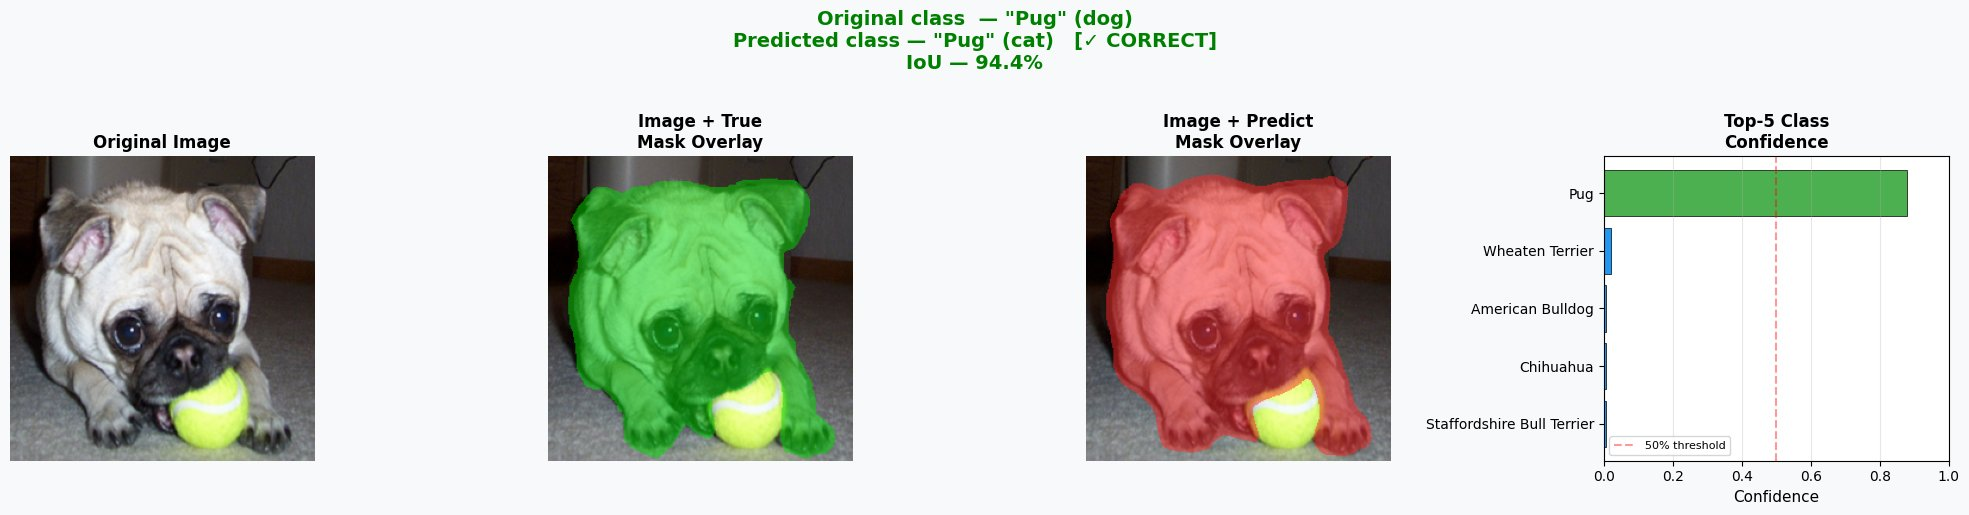

  Index 663 | True: Pug (dog) | Pred: Pug (cat) | IoU: 94.4% | ✓ CORRECT
  Top-5: ['Pug', 'Wheaten Terrier', 'American Bulldog', 'Chihuahua', 'Staffordshire Bull Terrier']
  Conf:  [0.878, 0.021, 0.007, 0.006, 0.005]



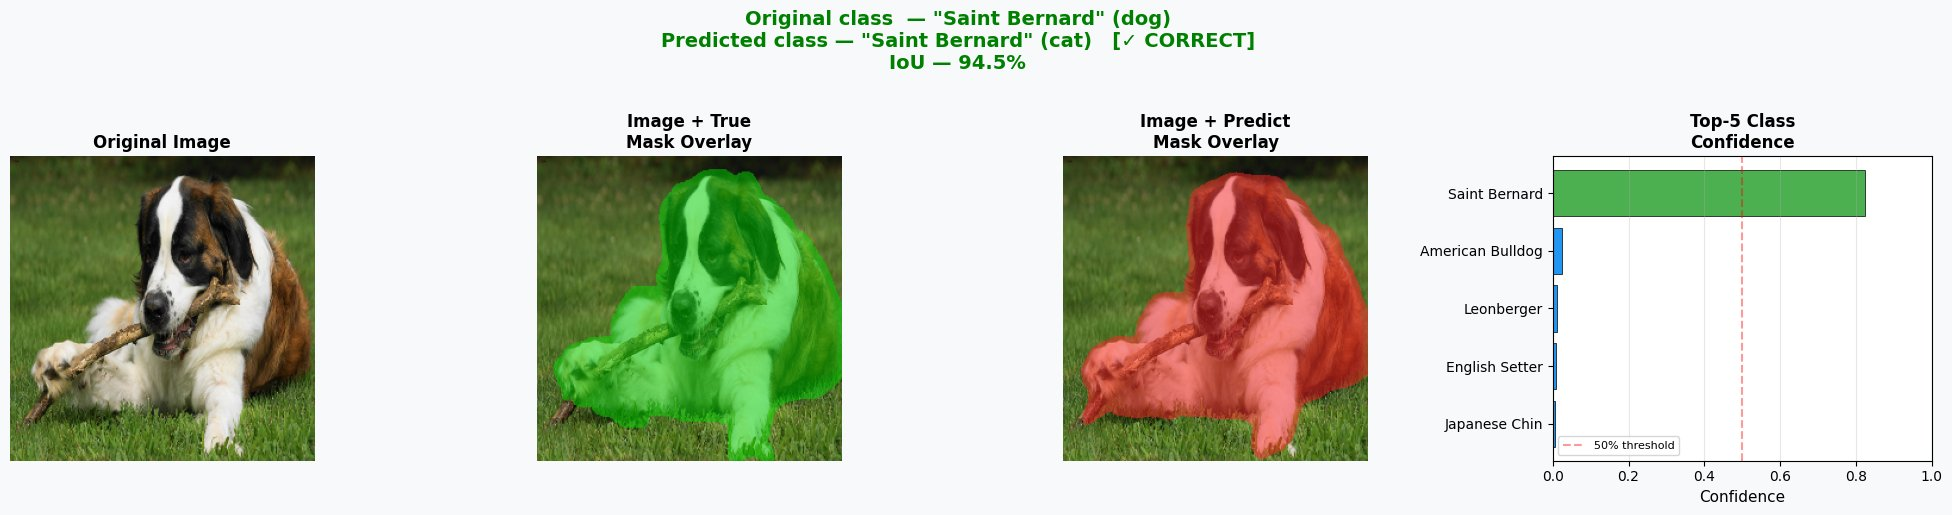

  Index 308 | True: Saint Bernard (dog) | Pred: Saint Bernard (cat) | IoU: 94.5% | ✓ CORRECT
  Top-5: ['Saint Bernard', 'American Bulldog', 'Leonberger', 'English Setter', 'Japanese Chin']
  Conf:  [0.825, 0.026, 0.01, 0.009, 0.006]



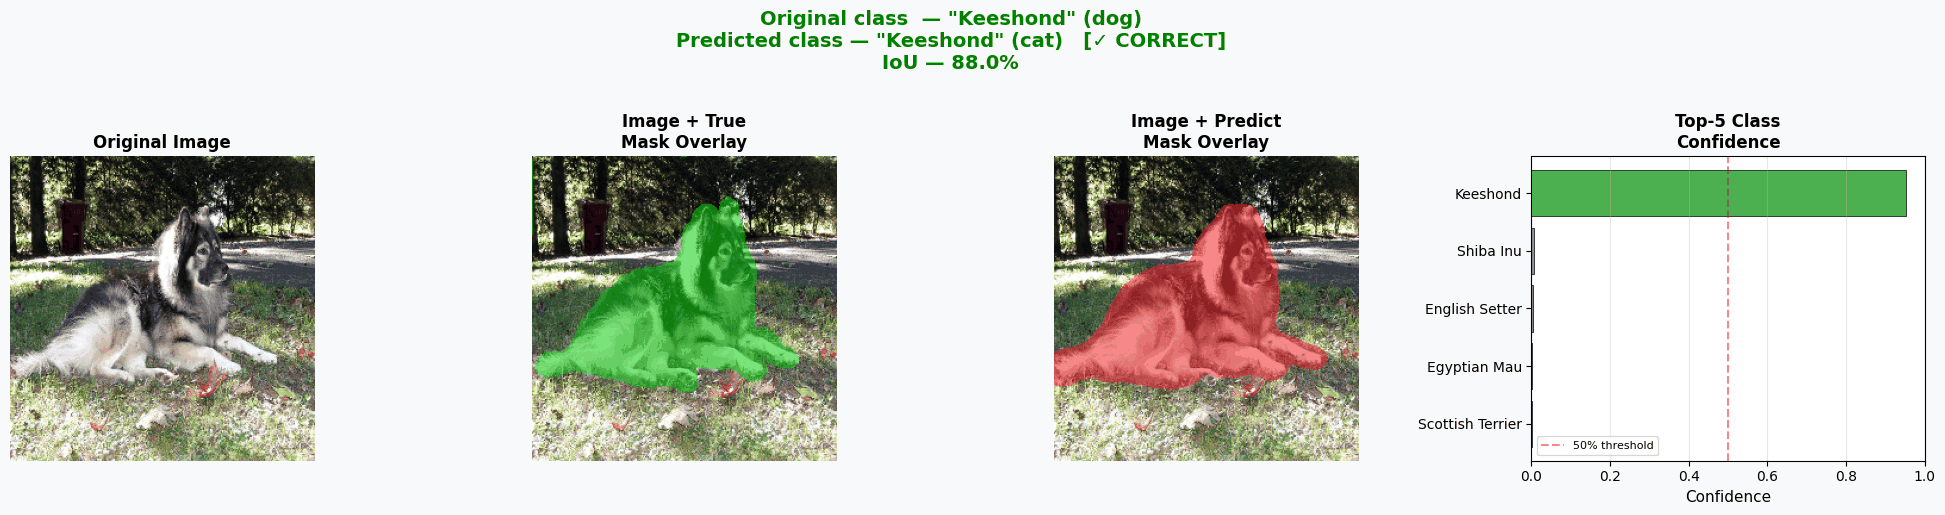

  Index 808 | True: Keeshond (dog) | Pred: Keeshond (cat) | IoU: 88.0% | ✓ CORRECT
  Top-5: ['Keeshond', 'Shiba Inu', 'English Setter', 'Egyptian Mau', 'Scottish Terrier']
  Conf:  [0.952, 0.006, 0.003, 0.002, 0.002]



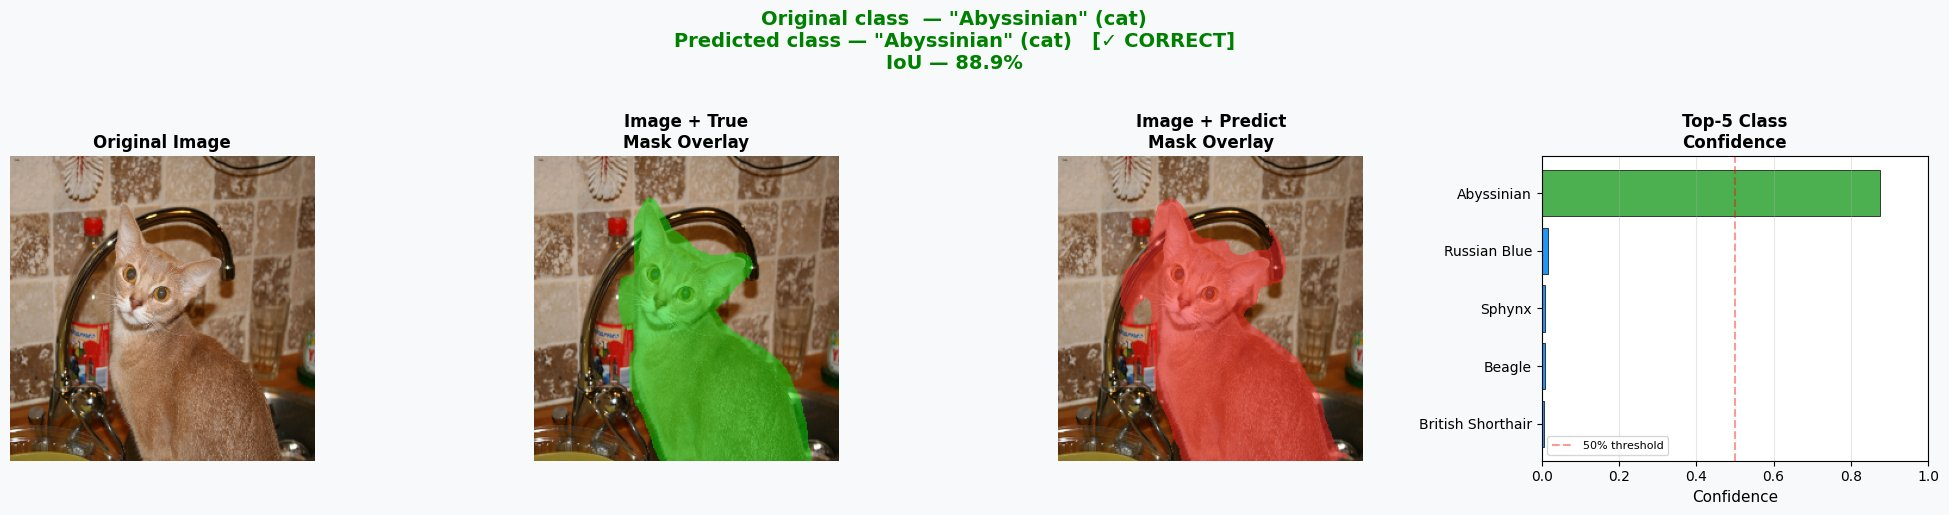

  Index 98 | True: Abyssinian (cat) | Pred: Abyssinian (cat) | IoU: 88.9% | ✓ CORRECT
  Top-5: ['Abyssinian', 'Russian Blue', 'Sphynx', 'Beagle', 'British Shorthair']
  Conf:  [0.877, 0.015, 0.008, 0.008, 0.007]



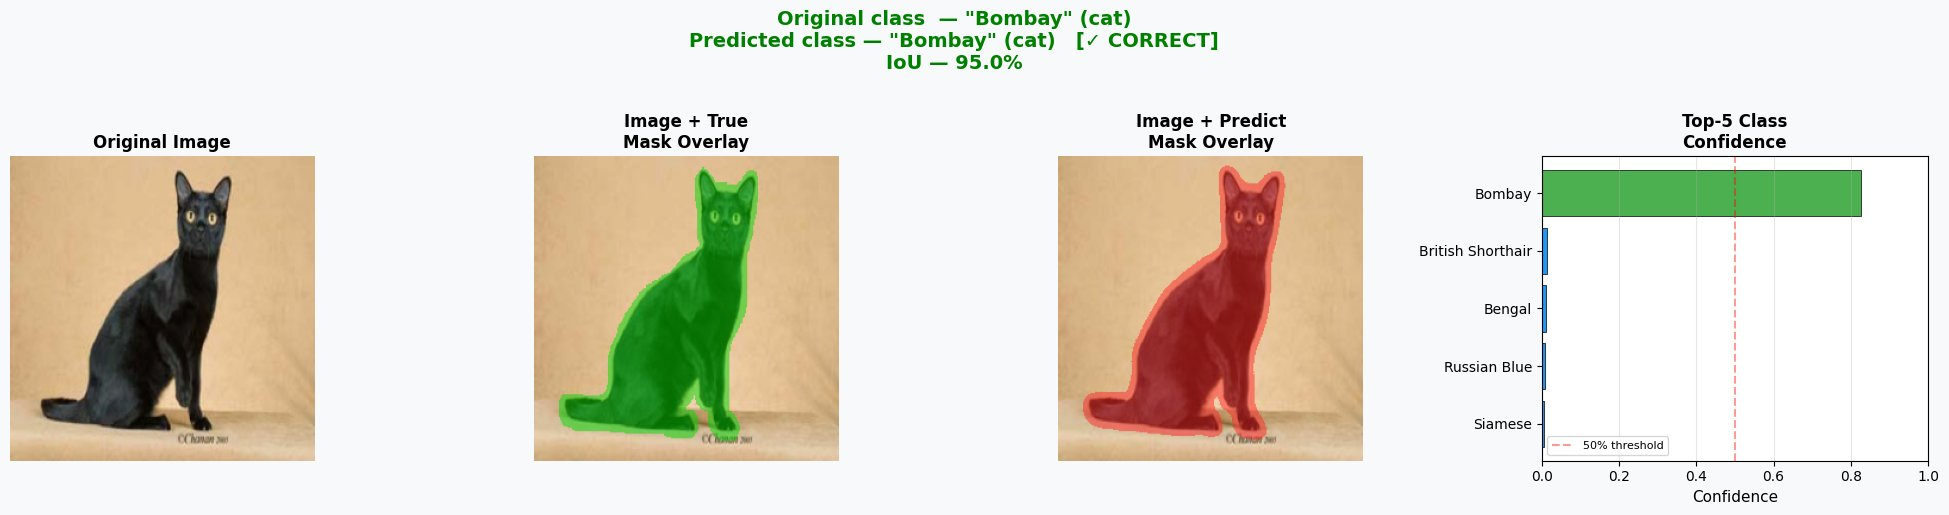

  Index 148 | True: Bombay (cat) | Pred: Bombay (cat) | IoU: 95.0% | ✓ CORRECT
  Top-5: ['Bombay', 'British Shorthair', 'Bengal', 'Russian Blue', 'Siamese']
  Conf:  [0.828, 0.013, 0.01, 0.009, 0.007]

  DEMO SECTION 2: Faculty-Provided Indices
  Total test images available: 0 to 1108


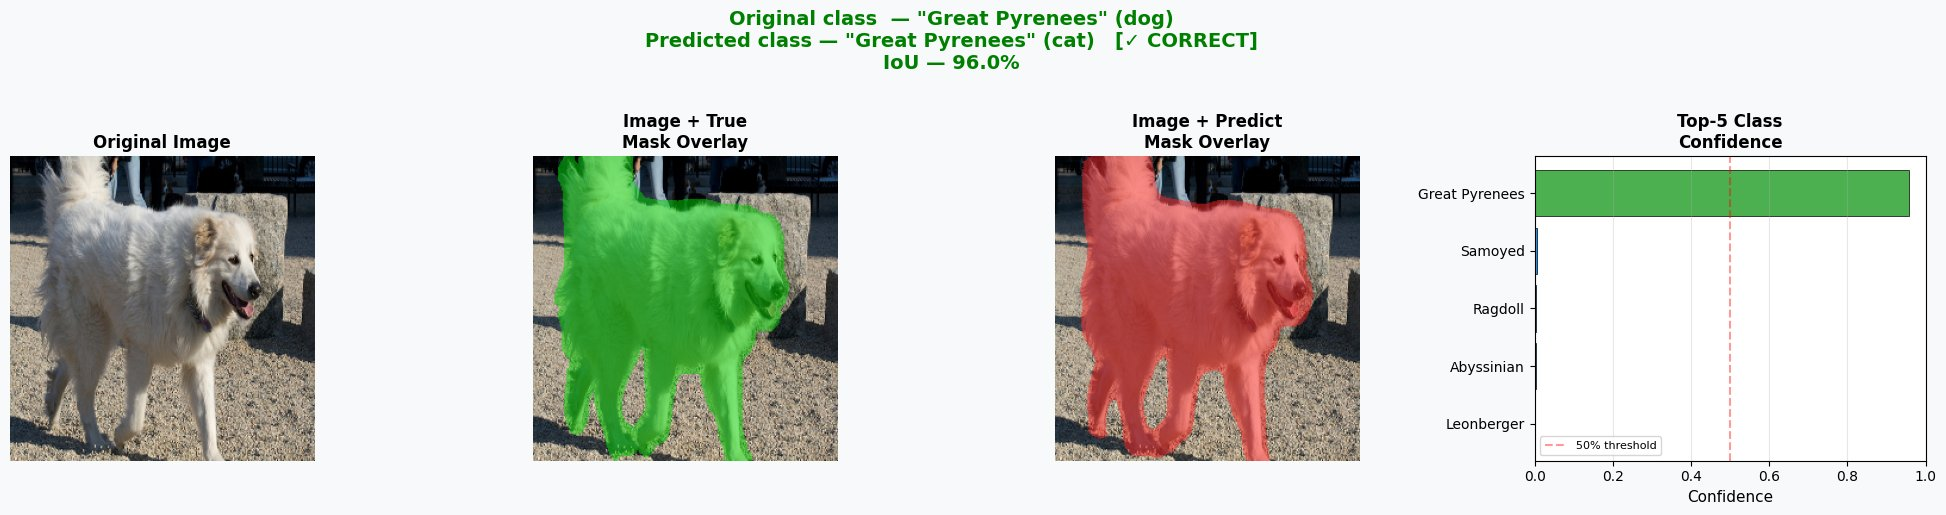

  Index 10 | True: Great Pyrenees (dog) | Pred: Great Pyrenees (cat) | IoU: 96.0% | ✓ CORRECT
  Top-5: ['Great Pyrenees', 'Samoyed', 'Ragdoll', 'Abyssinian', 'Leonberger']
  Conf:  [0.958, 0.007, 0.003, 0.002, 0.002]



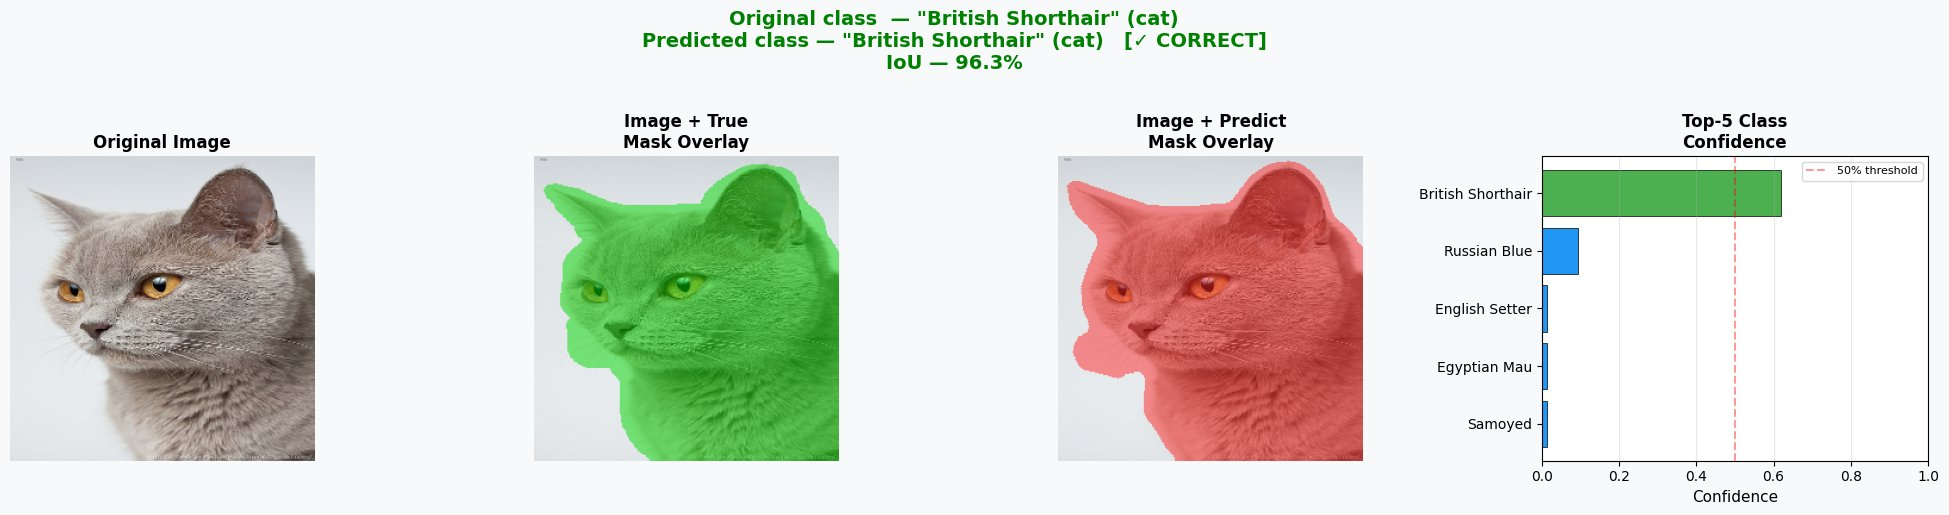

  Index 42 | True: British Shorthair (cat) | Pred: British Shorthair (cat) | IoU: 96.3% | ✓ CORRECT
  Top-5: ['British Shorthair', 'Russian Blue', 'English Setter', 'Egyptian Mau', 'Samoyed']
  Conf:  [0.618, 0.093, 0.015, 0.014, 0.013]



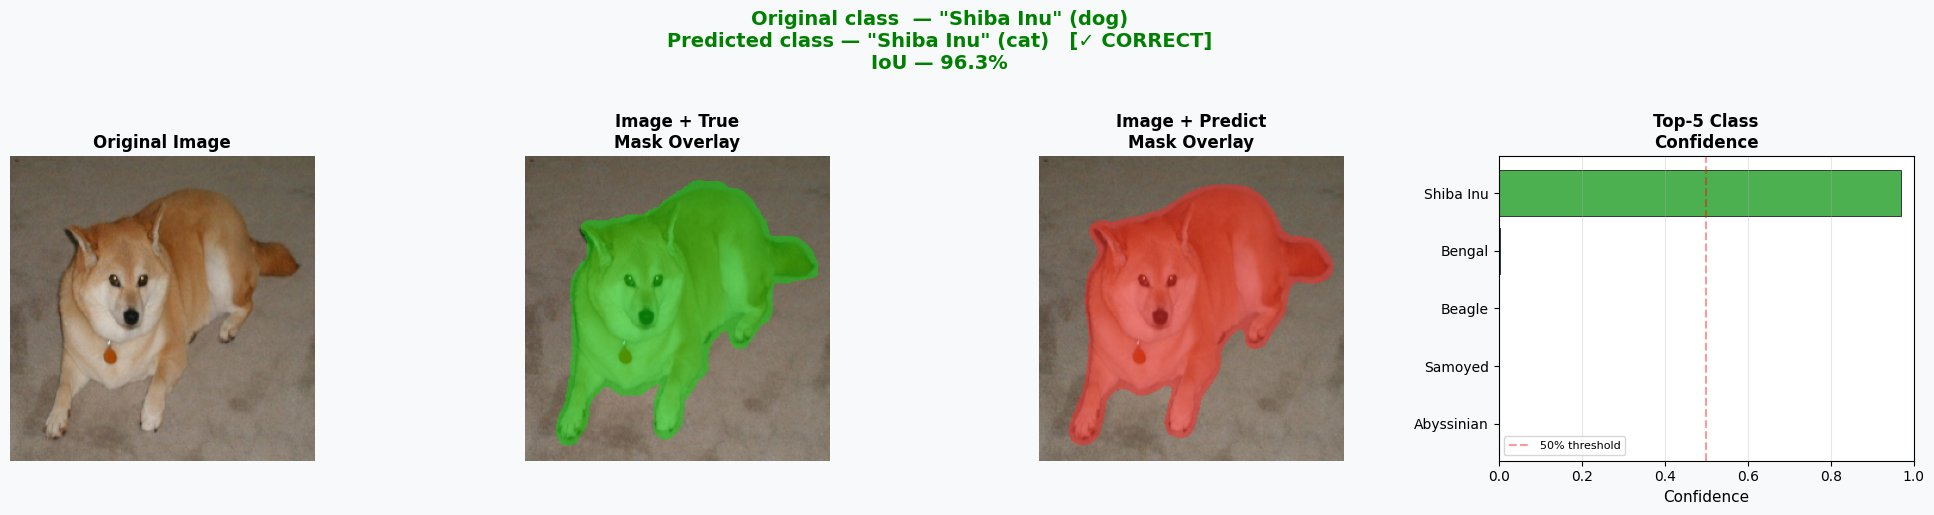

  Index 100 | True: Shiba Inu (dog) | Pred: Shiba Inu (cat) | IoU: 96.3% | ✓ CORRECT
  Top-5: ['Shiba Inu', 'Bengal', 'Beagle', 'Samoyed', 'Abyssinian']
  Conf:  [0.969, 0.004, 0.002, 0.002, 0.002]



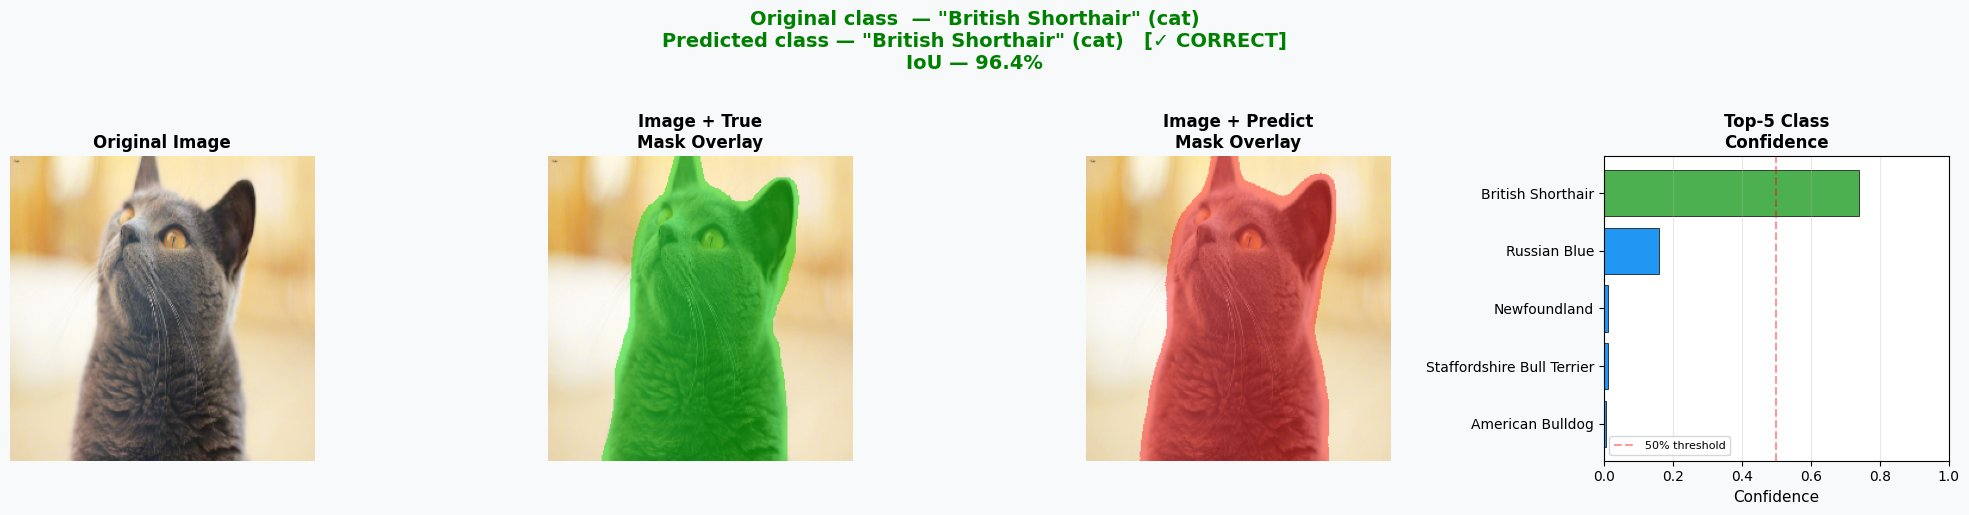

  Index 200 | True: British Shorthair (cat) | Pred: British Shorthair (cat) | IoU: 96.4% | ✓ CORRECT
  Top-5: ['British Shorthair', 'Russian Blue', 'Newfoundland', 'Staffordshire Bull Terrier', 'American Bulldog']
  Conf:  [0.74, 0.16, 0.012, 0.011, 0.005]



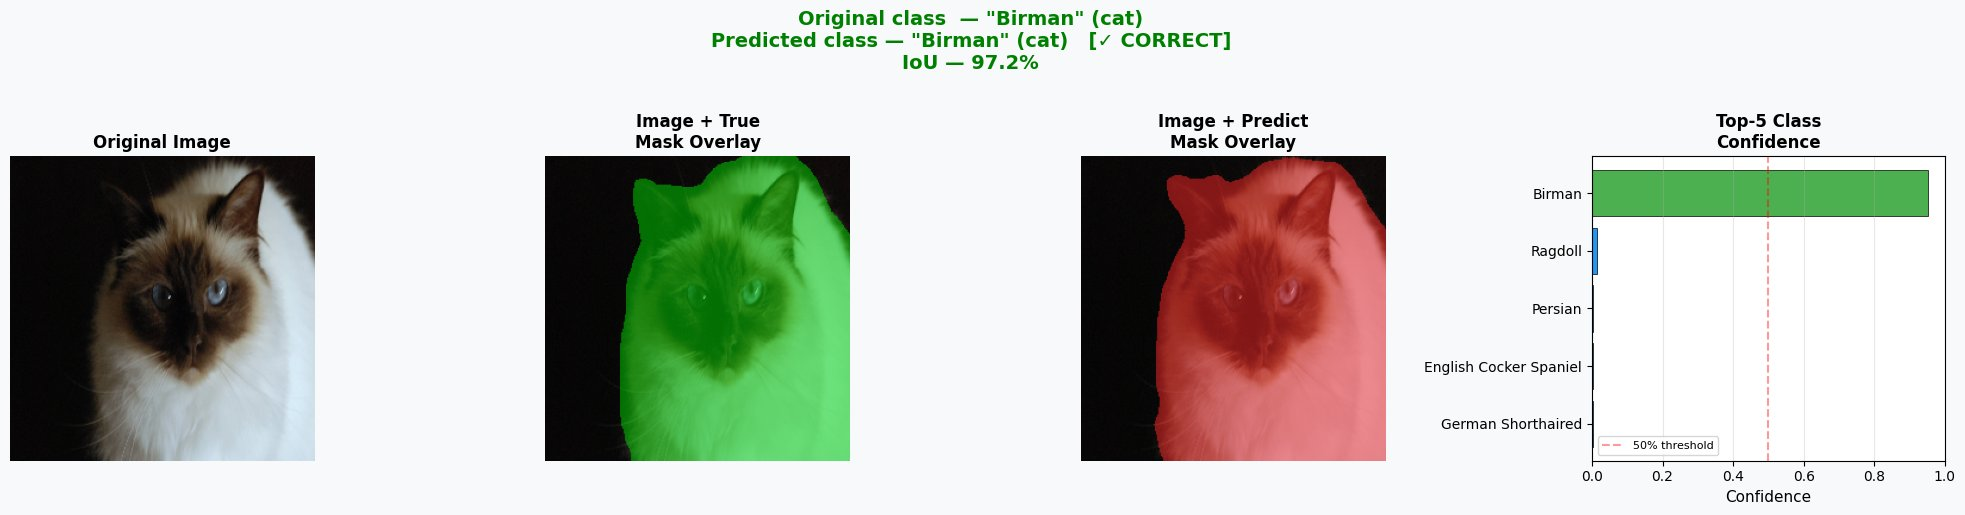

  Index 333 | True: Birman (cat) | Pred: Birman (cat) | IoU: 97.2% | ✓ CORRECT
  Top-5: ['Birman', 'Ragdoll', 'Persian', 'English Cocker Spaniel', 'German Shorthaired']
  Conf:  [0.952, 0.015, 0.003, 0.002, 0.002]

  DEMO SECTION 3: Quick Result Summary
  Model: ResNet34 U-Net (Pretrained Encoder)
  ── Segmentation ──
    mIoU       : 0.9317
    Dice       : 0.9589
    Pixel Acc  : 0.9655
  ── Classification ──
    Accuracy   : 0.9432
    Precision  : 0.9457
    Recall     : 0.9430
    F1 Score   : 0.9431

✓ Cell 12 complete — Presentation Demo ready.


In [10]:
# ═══════════════════════════════════════════════════════════════════════════
# CELL 12 ─ LIVE PRESENTATION DEMO
# PURPOSE : Any image index → model runs → results shown.
#           Works with ANY trained model loaded from disk.
# ═══════════════════════════════════════════════════════════════════════════

import gc

# ── Load best model for demo (ResNet34 preferred, falls back to Attention UNet) ─
print("Loading best model for demo...")
gc.collect(); torch.cuda.empty_cache()

demo_model_path = '/kaggle/working/ResNet34UNet_best.pth'
use_pretrained  = os.path.exists(demo_model_path)

if use_pretrained:
    demo_model = PretrainedUNet(seg_ch=1, num_classes=NUM_CLASSES)
    demo_model.load_state_dict(torch.load(demo_model_path, map_location='cpu'))
    demo_model_name = "ResNet34 U-Net (Pretrained Encoder)"
else:
    demo_model = AttentionUNet(seg_ch=1, num_classes=NUM_CLASSES)
    demo_model.load_state_dict(
        torch.load('/kaggle/working/AttentionUNet_Aug_best.pth', map_location='cpu'))
    demo_model_name = "Attention U-Net"

demo_model = demo_model.to(device); demo_model.eval()
print(f"✔ Loaded: {demo_model_name}\n")

# Ensure test_ds exists
if 'test_ds' not in globals():
    test_ds = PetDataset(test_info, transform=val_test_transform)

def make_overlay(img, mask, color, label_val=1):
    overlay = img.copy()
    m       = (mask == label_val)
    col_arr = np.array(color, dtype=np.float32)
    overlay[m] = overlay[m] * 0.5 + col_arr * 0.5
    return overlay

def denorm(t):
    mean = torch.tensor([0.485,0.456,0.406]).view(3,1,1)
    std  = torch.tensor([0.229,0.224,0.225]).view(3,1,1)
    return np.clip((t*std+mean).permute(1,2,0).numpy(), 0, 1)

def run_demo(index, model=demo_model, dataset=test_ds, top_k=5):
    """
    ── MAIN DEMO FUNCTION ──
    Pass any index from 0 to len(test_ds)-1.
    Displays exactly the format required by the project guidelines:
      Original image | Image + True mask | Image + Predicted mask
    Plus Top-5 confidence bar chart.
    """
    model.eval()
    img_t, lbl_t, bin_m, _ = dataset[index]
    item = dataset.data_list[index]

    with torch.no_grad():
        seg_out, cls_out = model(img_t.unsqueeze(0).to(device))
        probs            = torch.softmax(cls_out, dim=1).squeeze().cpu()
        topk_v, topk_i   = torch.topk(probs, top_k)
        pred_idx         = topk_i[0].item()

    img_np    = denorm(img_t)
    pred_mask = (torch.sigmoid(seg_out)>0.5).squeeze().cpu().numpy().astype(np.uint8)
    true_mask = bin_m.squeeze().cpu().numpy().astype(np.uint8)

    inter = np.logical_and(pred_mask==1, true_mask==1).sum()
    union = np.logical_or(pred_mask==1, true_mask==1).sum()
    iou   = (inter/(union+1e-6))*100

    true_breed = item['breed']
    pred_breed = idx_to_class[pred_idx]
    true_sp    = 'cat' if item['class_id'][0].isupper() else 'dog'
    pred_sp    = breed_to_species[pred_breed]
    correct    = '✓ CORRECT' if pred_breed==true_breed else '✗ WRONG'
    color      = 'green' if pred_breed==true_breed else 'red'

    # ── Required format from guidelines (3 panels) ────────────────────────
    fig, axes = plt.subplots(1, 4, figsize=(20, 5))
    fig.patch.set_facecolor('#f8f9fa')
    fig.suptitle(
        f'Original class  — "{true_breed}" ({true_sp})\n'
        f'Predicted class — "{pred_breed}" ({pred_sp})   [{correct}]\n'
        f'IoU — {iou:.1f}%',
        fontsize=14, fontweight='bold', color=color, y=1.02
    )

    axes[0].imshow(img_np)
    axes[0].set_title('Original Image', fontsize=12, fontweight='bold')
    axes[0].axis('off')

    axes[1].imshow(make_overlay(img_np, true_mask, [0,0.85,0]))
    axes[1].set_title('Image + True\nMask Overlay', fontsize=12, fontweight='bold')
    axes[1].axis('off')

    axes[2].imshow(make_overlay(img_np, pred_mask, [1,0.15,0.15]))
    axes[2].set_title('Image + Predict\nMask Overlay', fontsize=12, fontweight='bold')
    axes[2].axis('off')

    bar_colors = ['#4CAF50' if topk_i[top_k-1-j].item()==lbl_t.item()
                  else '#2196F3' for j in range(top_k)]
    axes[3].barh(range(top_k), topk_v.numpy()[::-1], color=bar_colors, edgecolor='black', lw=0.5)
    axes[3].set_yticks(range(top_k))
    axes[3].set_yticklabels([idx_to_class[topk_i[top_k-1-j].item()]
                              for j in range(top_k)], fontsize=10)
    axes[3].set_xlabel('Confidence', fontsize=11)
    axes[3].set_title('Top-5 Class\nConfidence', fontsize=12, fontweight='bold')
    axes[3].set_xlim(0, 1)
    axes[3].axvline(0.5, color='red', linestyle='--', alpha=0.4, label='50% threshold')
    axes[3].grid(True, alpha=0.3, axis='x')
    axes[3].legend(fontsize=8)
    plt.tight_layout(); plt.show()

    print(f"  Index {index} | True: {true_breed} ({true_sp}) | "
          f"Pred: {pred_breed} ({pred_sp}) | IoU: {iou:.1f}% | {correct}")
    print(f"  Top-5: {[idx_to_class[topk_i[j].item()] for j in range(top_k)]}")
    print(f"  Conf:  {[round(topk_v[j].item(),3) for j in range(top_k)]}\n")

# ═══════════════════════════════════════════════════════════════════════
# ── DEMO SECTION 1: 5 random test samples (presentation warm-up) ──────
# ═══════════════════════════════════════════════════════════════════════
print("="*60)
print("  DEMO SECTION 1: 5 Random Test Samples")
print("="*60)
random.seed(7)
for _ in range(5):
    run_demo(random.randint(0, len(test_ds)-1))

# ═══════════════════════════════════════════════════════════════════════
# ── DEMO SECTION 2: Faculty provides specific index (LIVE DEMO) ────────
# ── Change the numbers below to whatever index faculty gives you ───────
# ═══════════════════════════════════════════════════════════════════════
print("="*60)
print("  DEMO SECTION 2: Faculty-Provided Indices")
print(f"  Total test images available: 0 to {len(test_ds)-1}")
print("="*60)

FACULTY_INDICES = [10, 42, 100, 200, 333]  # ← CHANGE THESE DURING PRESENTATION

for idx in FACULTY_INDICES:
    if 0 <= idx < len(test_ds):
        run_demo(idx)
    else:
        print(f"  Index {idx} out of range (0–{len(test_ds)-1}), skipping.")

# ═══════════════════════════════════════════════════════════════════════
# ── DEMO SECTION 3: Quick result summary table ─────────────────────────
# ═══════════════════════════════════════════════════════════════════════
print("="*60)
print("  DEMO SECTION 3: Quick Result Summary")
print("="*60)
try:
    r = torch.load('/kaggle/working/resnet34_test_results.pth')
    print(f"  Model: {demo_model_name}")
    print(f"  ── Segmentation ──")
    print(f"    mIoU       : {r['seg']['miou']:.4f}")
    print(f"    Dice       : {r['seg']['dice']:.4f}")
    print(f"    Pixel Acc  : {r['seg']['px_acc']:.4f}")
    print(f"  ── Classification ──")
    print(f"    Accuracy   : {r['cls']['acc']:.4f}")
    print(f"    Precision  : {r['cls']['prec']:.4f}")
    print(f"    Recall     : {r['cls']['rec']:.4f}")
    print(f"    F1 Score   : {r['cls']['f1']:.4f}")
except:
    print("  (Run Cell 11 first to generate saved results)")

demo_model.cpu(); gc.collect(); torch.cuda.empty_cache()
print("\n✓ Cell 12 complete — Presentation Demo ready.")